# TPM028B
# Assignment 2: Droid Delivery Network Optimization

---

## Group Information

**Group Number:** 6

**Group Members:**
- Bryan Inggas - 5286654
- Ivaylo Iliev - 6294340

---
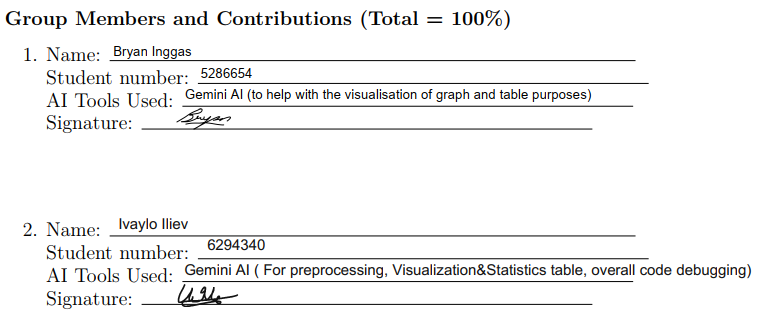
### Contribution Statement at the end.



## Setup and Imports

Import all necessary libraries and load the instance data.

In [56]:
# Import required libraries
import gurobipy as gp
from gurobipy import GRB
import json
import matplotlib.pyplot as plt
import numpy as np
import networkx as nx
import re
import matplotlib.patches as mpatches
import matplotlib.cm as cm
import copy
import pandas as pd

import io
import base64
from IPython.display import HTML


In [2]:
# Helper function to load instances
def load_instance(filename):
    """Load instance from JSON file."""
    with open(filename, 'r') as f:
        data = json.load(f)
    
    # Extract network
    zones = data['network']['zones']
    adjacency = {int(k): v for k, v in data['network']['adjacency'].items()}
    time_periods = data['network']['time_periods']
    depot = data['network']['depot']
    
    # Extract requests
    deliveries = data['deliveries']
    pickups = data.get('pickups', [])
    
    # Extract parameters
    params = data['parameters']
    
    return zones, adjacency, time_periods, depot, deliveries, pickups, params

gp.setParam('Seed', 42)
print("Helper functions loaded successfully!")

Set parameter Username
Set parameter LicenseID to value 2744804
Academic license - for non-commercial use only - expires 2026-11-25
Set parameter Seed to value 42
Helper functions loaded successfully!


---

# Scenario 1: Basic Routing Model

**Objective:** Minimize total arc usage for trucks and droids serving all delivery requests.

**Features:**
- Droids can ride on trucks (no energy consumption while riding)
- Droids have energy budget limit per excursion
- No recharging allowed (droids cannot reset energy mid-route)
- No pickup requests

---

### Mathematical Formulation

#### Sets and Indices
* $\mathcal{Z}$: Set of zones (spatial nodes).
* $\mathcal{T} = \{0, \dots, T_{max}\}$: Set of time periods.
* $\mathcal{N}$: Set of time-space nodes, where $u = (z, t) \in \mathcal{N}$.
* $\mathcal{A}$: The complete set of directed arcs in the time-space graph, where flow moves from $t$ to $t+1$.
    * $\mathcal{A}_{Truck} \subseteq \mathcal{A}$: Arcs traversable by Trucks.
    * $\mathcal{A}_{Droid} \subseteq \mathcal{A}$: Arcs traversable by Droids (Flying or Riding).
    * $\mathcal{A}_{Del} \subseteq \mathcal{A}$: Arcs designated for delivery actions.
    * $\mathcal{A}_{Shelf} \subseteq \mathcal{A}$: Virtual arcs at the Depot for package storage.
* $\mathcal{K}$: Set of all parcels (deliveries + pickups).
* $\mathcal{F}$: Set of all fleet types $\{\text{Truck}, \text{Droid}, \text{Del\_Tr}, \text{Del\_Dr}, \text{Depot\_Shelf}\}$.
* $\mathcal{E} = \{0, \dots, R\}$: Set of discrete energy levels for droids.
* $Pred(n)$: Set of Predecessor nodes (incoming arcs to $n$).
* $Succ(n)$: Set of Successor nodes (outgoing arcs from $n$).


#### Parameters
* $C_{fix}^{truck}$: Fixed cost for using a truck.
* $C_{move}^{truck}$: Cost per arc for a truck moving between different zones.
* $C_{wait}^{truck}$: Cost per arc for a truck waiting in the same zone.
* $C_{energy}^{droid}$: Cost per unit of energy consumed by a droid.
* $E_{move}, E_{del}$: Energy consumption for moving and delivering.
* $R$: Maximum energy capacity of a droid.

#### Decision Variables
* $x_{ij}^{k,f} \in \{0, 1\}$: Binary variable. 1 if parcel $k$ traverses arc $(i,j)$ using fleet $f$.
* $y_{ij}^{f} \in \mathbb{Z}_{\geq 0}$: Integer variable. Number of vehicles of fleet type $f$ traversing arc $(i,j)$.
* $z_{ij, e}^{fly} \in \mathbb{Z}_{\geq 0}$: Number of droids flying (moving under own power) on arc $(i,j)$ arriving with energy level $e$ (Waiting is included).
* $z_{ij, e}^{del} \in \mathbb{Z}_{\geq 0}$: Number of droids performing a delivery action on arc $(i,j)$ ending with energy level $e$.
* $z_{ij, e}^{ride} \in \mathbb{Z}_{\geq 0}$: Number of droids riding a truck on arc $(i,j)$ ending with energy level $e$.

#### Objective Function
Minimize the total cost, comprising variable truck costs, droid energy costs, and fixed truck costs:

$$
\begin{aligned}
\text{Minimize } Z = \quad & \sum_{(i,j) \in \mathcal{A}} \sum_{f \in \mathcal{F}_{truck}} y_{ij}^f \cdot C_{ij}^{truck} \quad && \text{(Truck Variable Cost)} \\
+ & \sum_{(i,j) \in \mathcal{A}} \sum_{e \in \mathcal{E}} C_{energy}^{droid} \left( z_{ij,e}^{fly} \cdot E_{move} + z_{ij,e}^{del} \cdot E_{del} \right) \quad && \text{(Droid Energy Cost)} \\
+ & \sum_{j \in \mathcal{N}} y_{(depot, 0), j}^{Truck} \cdot C_{fix}^{truck} \quad && \text{(Truck Fixed Cost)}
\end{aligned}
$$

Where the truck arc cost $C_{ij}^{truck}$ is defined as:
$$
C_{ij}^{truck} = 
\begin{cases} 
C_{move}^{truck} & \text{if } i_{zone} \neq j_{zone} \\
C_{wait}^{truck} & \text{if } i_{zone} = j_{zone}
\end{cases}
$$

### Constraints

#### 1. Flow Conservation
This ensures the parcel moves through the network continuously.
* **Source:** The parcel is generated at the **Depot** at $t=0$ (Net flow = 1).
* **Intermediate:** Flow entering a node must equal flow leaving it (Net flow = 0).
* **Sink (Implicit):** If a parcel takes a **Delivery Arc**, it leaves the current node but is **not** added to the inflow of the next node (effectively exiting the network).

$$
\sum_{(u, v) \in \mathcal{A}} \sum_{f \in \mathcal{F}} x_{u, v}^{k,f} - \sum_{(w, u) \in \mathcal{A}} \sum_{f \notin \mathcal{F}_{del}} x_{w, u}^{k,f} = 
\begin{cases} 
1 & \text{if } u = (\text{Depot}, 0) \\
0 & \text{otherwise}
\end{cases}
\quad \forall u \in \mathcal{N}, \forall k \in \mathcal{K}
$$

> **Note:** The second term (Inflow) explicitly **excludes** delivery fleets ($f \notin \mathcal{F}_{del}$).

#### 2. Force Service (Deadline Satisfaction)
This constraint ensures that for every parcel $k$, exactly one "Delivery" action occurs at the target zone $z_{target}$ on or before the due time $T_{due}$.

$$
\sum_{t=1}^{T_{due}} \sum_{f \in \{\text{Del\_Dr}, \text{Del\_Tr}\}} x_{(z_{target}, t-1), (z_{target}, t)}^{k,f} = 1 \quad \forall k \in \mathcal{K}
$$

### Why Delivery Timing is exactly after the package enters a "delivery" vehicle

**1. Delivery is a Movement, Not a Status**
The variable $x_{t, t+1}^{del}$ represents the specific action of moving from the network into the delivery state. It is not a checkmark; it is a flow variable.

**2. The Chain of Custody**
For a delivery to occur at a later time $t+k$, the variable $x_{t+k, t+k+1}^{del}$ must be set to 1.
However, flow constraints dictate that a variable can only be 1 if there is **input flow** at node $t+k$ (i.e., the package is present).

**3. The Impossibility of Delay**
If the package exits the network at time $t$ (via $x_{t, t+1}^{del}=1$):
* **Flow Termination:** The package is removed from the system. The flow at all subsequent nodes ($t+1, t+2, \dots$) becomes 0.
* **Broken Chain:** Since flow at $t+k$ is 0, the variable $x_{t+k, t+k+1}^{del}$ is forced to 0.

**Conclusion:**
You cannot deliver what you do not have. Once the package exits, it is gone. Therefore, the "Force Service" credit ($\sum x = 1$) is always awarded at the exact instant the exit occurs.


### 3 Asset Balance & Global Fleet Limits

These constraints manage the available fleet size at the depot ($t=0$) and ensure vehicles are conserved (flow in = flow out) throughout the timeline.

#### 3.1. Global Truck Limit (at $t=0$)
The total number of trucks (both moving and delivering types) leaving the depot at time 0 cannot exceed the available fleet size $N_{truck}$.

$$
\sum_{(v) \in \text{neighbors}(\text{Depot},0)} \sum_{f \in \{\text{Truck}, \text{Del\_Tr}\}} y_{(\text{Depot},0), v}^{f} \leq N_{truck}
$$

#### 3.2. Global Droid Limit & Initial Energy (at $t=0$)
The total number of droids (flying, riding, or delivering) leaving the depot at time 0 cannot exceed $N_{droid}$. Furthermore, all droids leaving the depot must start with full energy capacity ($e=R$). Later FFC for droids done via the Energy level constraint.

**Limit Constraint:**
$$
\sum_{(v) \in \text{neighbors}(\text{Depot},0)} \sum_{e=0}^{R} \left( z_{(\text{Depot},0), v, e}^{fly} + z_{(\text{Depot},0), v, e}^{ride} + z_{(\text{Depot},0), v, e}^{del} \right) \leq N_{droid}
$$

**Full Energy Enforcement. Drouds with lower energy are not allowed at t=0:**
$$
z_{(\text{Depot},0), v, e}^{\{fly, ride, del\}} = 0 \quad \forall e < R
$$

#### 3.3. Truck Asset Balance (Flow Conservation)
For all intermediate time-space nodes ($0 < t < T_{max}$), the number of trucks arriving must equal the number of trucks departing.

$$
\sum_{(u, n) \in \mathcal{A}} \sum_{f \in \{\text{Truck}, \text{Del\_Tr}\}} y_{u, n}^{f} = \sum_{(n, v) \in \mathcal{A}} \sum_{f \in \{\text{Truck}, \text{Del\_Tr}\}} y_{n, v}^{f} \quad \forall n = (z, t) \text{ where } 0 < t < T_{max}
$$

### 4. Capacity Constraints

We ensure that the number of parcels assigned to a specific fleet type $f$ on arc $(u,v)$ does not exceed the capacity of the active vehicles of that type.

#### Case 4.1: Flying Droids ($f = \text{"Droid"}$)
For droids moving autonomously (flying or waiting), the capacity is provided by the sum of all flying droids across valid energy levels. Riding does not provide capacity on the arc for droids. Those packages get reassinged to the truck

$$
\sum_{k \in \mathcal{K}} x_{u, v}^{k, \text{Droid}} \leq Q_{\text{Droid}} \cdot \left( \sum_{e=0}^{R} z_{u, v, e}^{fly} \right) \quad \forall (u, v) \in \mathcal{A}
$$

#### Case 4.2: Trucks, Delivery Fleets, and Shelf ($f \neq \text{"Droid"}$)
For all other fleet types (Trucks, Delivery actions, and the Virtual Shelf), the capacity is linked to the generic flow variable $y$.

$$
\sum_{k \in \mathcal{K}} x_{u, v}^{k, f} \leq Q_{f} \cdot y_{u, v}^{f} \quad \forall (u, v) \in \mathcal{A}, \forall f \in \{\text{Truck}, \text{Del\_Tr}, \text{Del\_Dr}, \text{Shelf}\}
$$

**Where:**
* $Q_f$: The capacity parameter (`cap_per_fleet`) for fleet $f$.

### 5. Coupling & Mothership Constraints

These constraints ensure consistency between the detailed energy states ($z$) and the aggregate fleet flows ($y$), and enforce the physical limits of trucks carrying droids.

#### 5.1. Mothership Constraint (Capacity)
If droids are riding, they must be carried by a truck. The total number of riding droids cannot exceed the specific droid-carrying capacity of the trucks traversing that arc.
*Note: Both standard "Trucks" and "Delivery Trucks" can carry droids.*

$$
\sum_{e=0}^{R} z_{u, v, e}^{ride} \leq C_{truck}^{droid} \cdot \left( y_{u, v}^{\text{Truck}} + y_{u, v}^{\text{Del\_Tr}} \right) \quad \forall (u, v) \in \mathcal{A}_{\text{Droid}}
$$

#### 5.2. Droid Delivery Coupling
For arcs representing a delivery action, the aggregate delivery flow ($y^{\text{Del\_Dr}}$) must equal the sum of droids performing the delivery across valid energy levels. This still exists from previous itterations, where I used it. Currently everything is done via the "z"-variable, but I haven't changed the code, so I keep it for completeness

$$
\sum_{e=0}^{R} z_{u, v, e}^{del} = y_{u, v}^{\text{Del\_Dr}} \quad \forall (u, v) \in \mathcal{A}_{\text{Del\_Dr}}
$$

**Where:**
* $C_{truck}^{droid}$: Parameter `Cap_T_Droid` (Max droids a single truck can carry).
* $\mathcal{A}_{\text{Droid}}$: Set of arcs where droid movement is allowed.
* $\mathcal{A}_{\text{Del\_Dr}}$: Set of arcs where droid delivery is allowed.

### 6. Energy Balance Constraint

This constraint ensures flow conservation for droids within specific energy levels. We use a state-space expansion where energy is an index, not a continuous multiplier. We are simply routing flow from an "Energy R" node to an "Energy R-1" node when we perofrm delivery/flying (Waitng has cost C(fly)=0).

**Constraint Logic:**
For every node $n$ and current energy level $e$, the number of droids arriving (having spent energy to get here) must equal the number of droids leaving (starting with current energy $e$).

$$
\underbrace{ \sum_{p} z_{p, n, e}^{ride} }_{\text{Arriving Riders}} 
+ \underbrace{ \sum_{p} z_{p, n, (e + C_{fly})}^{fly} }_{\text{Arriving Flyers}} 
+ \underbrace{ \sum_{p} z_{p, n, (e + C_{del})}^{del} }_{\text{Arriving Deliverers}} 
\quad = \quad
\underbrace{ \sum_{v} \left( z_{n, v, e}^{fly} + z_{n, v, e}^{ride} + z_{n, v, e}^{del} \right) }_{\text{Total Departing with energy } e}
$$

**Where:**
* $p \in \text{Pred}(n)$: The set of "Predecessor" nodes. These are all nodes $p$ such that an arc $(p, n)$ exists in the graph.
* $v \in \text{Succ}(n)$: The set of **Successors**. Nodes at time $t+1$ that the current node $n$ connects *out to*.
* **Left Side (Incoming):** To arrive at node $n$ with energy $e$, a droid must have started at the previous node $p$ with higher energy ($e + Cost$).
* **Right Side (Outgoing):** Droids leave node $n$ starting their next action with the current energy level $e$.
* **Note:** The incoming terms for Flying and Delivering only exist if $(e + Cost) \le R$.

### 7. Strong Linking & Valid Inequalities (Cuts)

This constraint ensures that a parcel $k$ cannot be assigned to a truck fleet on arc $(u,v)$ unless a truck is actually traversing that arc.
*It links the binary decision $x$ to the integer decision $y$.*

$$
x_{u, v}^{k, f} \leq \sum_{f' \in \{\text{Truck}, \text{Del\_Tr}\}} y_{u, v}^{f'} \quad \forall (u,v) \in \mathcal{A}, \forall k \in \mathcal{K}, \forall f \in \{\text{Truck}, \text{Del\_Tr}\}
$$


## **Attention — Reporting Caveats**

**Note 1: Initial Droid Energy Levels**  
The reported initial energy level of a droid may be **less than $R=4$**.  
The model output reading function does not enforce a mandatory starting energy value; it only constrains energy to not exceed $R$.  
Consequently, if a droid appears to start with energy level 3, this indicates that only 3 units of energy were required for feasibility, not that the droid was initialized with the maximum capacity.
Further on, with recharge, I've gotten a solution where the droid is said to start with energy=1, just sitting in the depot, gets inside up by the truck and once inside the truck it has energy 4. This is again a consequence of the fact that whether a droid starts with energy (0,1,2,3,4), as it does not need to use it from the start and is getting picked-up by the truck, the solver is free to pick any level.

---

**Note 2: Energy Swapping in Aggregated Output**  
Energy levels reported for individual droids may appear to swap between droids occupying the same location or arc during the same time period.  
This is a consequence of the **aggregate-level formulation**, where individual droid identities are not tracked.  
As a result, energy consumption may appear reassigned between droids in the detailed output.
For example, if a truck carries 2 droids, then those 2 droid energy reports might get swapped.

---

### **Note 3: Droid Identity Swap at Nodes**

**The Phenomenon of Aggregated Flow**
In the models, the solver tracks the *quantity* of flow ($y_{uv}$) rather than unique, individual agents. A node acts as a "mixing pool" where all incoming units are collected and then distributed to outgoing arcs based on optimal assignment. When at node, there are multiple droids, the solver might switch their energy levels, however it will not switch the amount of droids of level (e) that came in or went out. 

This can lead to an **"Identity Swap"**:
1.  **Input:** Two droids enter Node $n$.
    * **Droid A** enters with **Low Energy** ($e=2$).
    * **Droid B** enters with **Full Energy** ($e=5$).
2.  **The "Pool":** The node now contains generic assets: $\{1 \text{ unit} @ e2, 1 \text{ unit} @ e5\}$.
3.  **Output:** The solver assigns the **Full Energy** unit to a high-demand task (e.g., Flying) and the **Low Energy** unit to a low-demand task (e.g., Riding).

**Result:** In the tracking report, it appears as though Droid A and Droid B swapped batteries instantaneously. This is mathematically valid because the node's total energy balance is preserved and the actions assigned to the "magically" recharged droid should have been completed by the other droid:
$$\sum E_{in} = \sum E_{out}$$

---

**Case Study: The "Magic" Recharge**
We observed this behavior at **Zone 15 / Time 12**, where a flying droid appeared to gain full energy without visiting the truck.

| Time | Droid | Zone | Energy | Activity | Payload |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **10 $\to$ 11** | **Droid A** | 9 | 2 | Waiting | - |
| **11 $\to$ 12** | **Droid A** | 9 | 2 | Riding on Truck $\to$ Z15 | - |
| **12 $\to$ 13** | **Droid A** | 15 | **2** | Riding on Truck $\to$ Z14 | - |
| **13 $\to$ 14** | **Droid A** | 14 | 5 | Waiting | - |
| | | | | | |
| **10 $\to$ 11** | **Droid B** | 12 | 4 | Flying $\to$ Z15 | [1] |
| **11 $\to$ 12** | **Droid B** | 15 | 3 | Delivering [1] | [1] |
| **12 $\to$ 13** | **Droid B** | 15 | **5** | Flying $\to$ Z18 | [3] |
| **13 $\to$ 14** | **Droid B** | 18 | 4 | Delivering [3] | [3] |

**Conclusion:**
Droid B "stole" the full battery that Droid A brought in on the truck. The solver optimized the path by sending the charged unit to the Flying task (which required it) and keeping the depleted unit on the truck to recharge. Even though it disrupts the continuity narative, it is still valid, as the actions performed by droid(B) should have been performed by droid(A), and Droid(B) should have been put inside the truck for recharge. 

## 1.2 Implementation

Implement Scenario 1 model in the cell below.

In [3]:
def build_time_space_multigraph(zones, adjacency, T, depot=0):
    """
    Builds a time-space network where every arc guarantees the vehicle 
    can still reach the depot by the final time step.
    Includes 'Truck', 'Droid', and 'Deliver' arcs.
    """
    G = nx.MultiDiGraph()

    # --- Step 1: Compute shortest path to depot for each zone (BFS) ---
    # We must know how far every zone is from the depot to enforce the return constraint.
    shortest_to_depot = {}
    
    # Initialize all as infinite
    for z in zones:
        shortest_to_depot[z] = float('inf')

    # BFS from Depot (Reverse logic: distance FROM zone TO depot is same as Depot TO zone in undirected/symmetric map)
    # If your map is directed, you might need a reverse graph here. Assuming symmetric for now.
    queue = [(depot, 0)]
    visited = {depot}
    shortest_to_depot[depot] = 0
    
    while queue:
        curr, dist = queue.pop(0)
        # Assuming adjacency is a dict of neighbor lists
        for neighbor in adjacency.get(curr, []):
            if neighbor not in visited:
                visited.add(neighbor)
                shortest_to_depot[neighbor] = dist + 1
                queue.append((neighbor, dist + 1))

    # --- Step 2: Add nodes for all time steps ---
    for t in range(T):
        for z in zones:
            G.add_node((z, t))

    # --- Step 3: Add feasible arcs ---
    # We iterate up to T-1 because an arc goes from t -> t+1.
    for t in range(T - 1):
        for z in zones:

            # Constraint: Only the depot is active at t=0 (Source)
            if t == 0 and z != depot:
                continue
            
            # Skip if this node itself is unreachable or too far to ever return
            if shortest_to_depot[z] == float('inf'):
                continue

            # Identify all possible moves: Neighbors (Move) + Self (Wait/Deliver)
            neighbors = adjacency.get(z, []) + [z]

            for z2 in neighbors:
                # --- THE RETURN CONSTRAINT ---
                # logic: Current Time (t) + Move (1) + Time to get Home from Dest (dist) <= Max Time (T-1)
                # Therefore: t + 1 + shortest_to_depot[z2] <= T - 1
                # Simplified: t + shortest_to_depot[z2] <= T - 2
                
                if shortest_to_depot[z2] != float('inf') and (t + shortest_to_depot[z2] <= T - 2):
                    
                    # 1. Standard Transport Arcs
                    G.add_edge((z, t), (z2, t + 1), arc_type="Truck")
                    G.add_edge((z, t), (z2, t + 1), arc_type="Droid")
                    
                    # 2. "Deliver" Arc (Only exists if staying in the same zone)
                    # This represents spending time to perform a service action.
                    if z == z2:
                        G.add_edge((z, t), (z2, t + 1), arc_type="Deliver")

    return G
    
def time_space_layout(zones, T):
    return {(z, t): (t, -z) for t in range(T) for z in zones}

def visualize_time_space_multigraph(zones, adjacency, T):
    G = build_time_space_multigraph(zones, adjacency, T)
    pos = time_space_layout(zones, T)

    plt.figure(figsize=(1.5 * T, 1.2 * len(zones)))

    # Draw nodes
    nx.draw_networkx_nodes(
        G, pos,
        node_size=300,
        node_color="lightblue"
    )

    # Split edges by type
    edges_A = [(u, v) for u, v, k in G.edges(keys=True)
                if G[u][v][k]["arc_type"] == "Truck"]
    edges_B = [(u, v) for u, v, k in G.edges(keys=True)
                if G[u][v][k]["arc_type"] == "Droid"]
    edges_C = [(u, v) for u, v, k in G.edges(keys=True)if G[u][v][k]["arc_type"] == "Deliver"]

        # Draw arc type A (Truck Arcs)
    nx.draw_networkx_edges(
            G, pos,
            edgelist=edges_A,
            edge_color="tab:blue",
            arrows=True,
            arrowsize=10,
            width=1,
            connectionstyle="arc3,rad=0.15"
        )

        # Draw arc type B (Droid arcs flying)
    nx.draw_networkx_edges(
            G, pos,
            edgelist=edges_B,
            edge_color="tab:orange",
            arrows=True,
            arrowsize=10,
            width=1,
            connectionstyle="arc3,rad=-0.15"
        )

        # Draw arc type C (Droid arcs inside the truck)
    nx.draw_networkx_edges(G, pos,edgelist=edges_C,edge_color="tab:purple",arrows=True,arrowsize=10,width=1,connectionstyle="arc3,rad=0")

        # Labels
    labels = {(z, t): f"{z}" for (z, t) in G.nodes()}
    nx.draw_networkx_labels(G, pos, labels, font_size=8)

        # Time labels
    for t in range(T):
            plt.text(t, 1, f"t={t}", ha="center", va="bottom")

        # Legend
    from matplotlib.lines import Line2D
    legend_elements = [
            Line2D([0], [0], color="tab:blue", lw=2, label="Arc set Truck"),
            Line2D([0], [0], color="tab:orange", lw=2, label="Arc set Droid"),
            Line2D([0], [0], color="tab:purple", lw=2, label="Arc set Delivery"),
        ]
    plt.legend(handles=legend_elements, loc="upper right")

    plt.title("Time–Space Network with Duplicate Arc Sets")
    plt.axis("off")
    plt.show()

def visualize_time_space_solution(model, G, title="Mothership Scenario Solution"):
    """
    Parses the Gurobi model to reconstruct actual vehicle routes and plots them 
    with unique colors per vehicle ID. Handles mixed fleet deliveries.
    Includes DETERMINISTIC SORTING to match text report.
    """
    
    # --- 1. Parse Gurobi Variables & Build Graph Flow ---
    adj = {'Truck': {}, 'Droid': {}} 
    pkg_on_link = {} 

    def parse_tuple(s):
        s = s.replace('(', '').replace(')', '')
        return tuple(map(int, s.split(',')))

    def get_fleet_key(raw_name):
        if "Truck" in raw_name: return "Truck"
        if "Droid" in raw_name: return "Droid"
        return raw_name

    for var in model.getVars():
        if var.X <= 0.001: continue
        name = var.VarName
        
        # Parse Vehicles (y)
        if name.startswith("y_"):
            m = re.search(r"y_([a-zA-Z_]+)_\((.+?)\)_\((.+?)\)", name)
            if m:
                fleet_raw = m.group(1)
                u = parse_tuple(m.group(2))
                v = parse_tuple(m.group(3))
                count = int(round(var.X))
                
                fleet_key = get_fleet_key(fleet_raw)
                if fleet_key not in adj: adj[fleet_key] = {}
                if u not in adj[fleet_key]: adj[fleet_key][u] = []
                
                for _ in range(count):
                    adj[fleet_key][u].append(v)

        # Parse Packages (x)
        elif name.startswith("x_"):
            m = re.search(r"x_(\d+)_\((.+?)\)_\((.+?)\)_([a-zA-Z_]+)", name)
            if m:
                k_id = int(m.group(1))
                u = parse_tuple(m.group(2))
                v = parse_tuple(m.group(3))
                fleet_raw = m.group(4)
                
                fleet_key = get_fleet_key(fleet_raw)
                key = (u, v, fleet_key)
                if key not in pkg_on_link: pkg_on_link[key] = []
                pkg_on_link[key].append(k_id)

    # --- 2. Reconstruct Routes (Deterministic Greedy Walk) ---
    # !!! THE FIX: SORT ADJACENCY LISTS !!!
    for f in adj:
        for u in adj[f]:
            # Sort by Time (v[1]) then Zone (v[0]) to ensure deterministic path selection
            adj[f][u].sort(key=lambda x: (x[1], x[0]))

    routes = []
    
    # Infer max time/depot
    all_times = sorted(list(set([n[1] for n in G.nodes()])))
    if not all_times: return
    max_time = all_times[-1]
    depot_zone = 0 
    
    for fleet in ['Truck', 'Droid']:
        veh_id = 1
        current_adj = adj[fleet]
        start_node = (depot_zone, 0)
        
        while start_node in current_adj and len(current_adj[start_node]) > 0:
            path = []
            curr = start_node
            
            while curr in current_adj and len(current_adj[curr]) > 0:
                next_node = current_adj[curr].pop(0) # Deterministic pop due to sort
                path.append((curr, next_node))
                curr = next_node
                if curr[0] == depot_zone and curr[1] == max_time: break
            
            route_pkgs = {}
            for (u, v) in path:
                if (u, v, fleet) in pkg_on_link:
                    route_pkgs[(u, v)] = pkg_on_link[(u, v, fleet)]
            
            routes.append({
                "fleet": fleet, "id": veh_id, "path": path, "pkg_segments": route_pkgs
            })
            veh_id += 1

    # --- 3. Setup Plot ---
    fig, ax = plt.subplots(figsize=(16, 10))
    all_zones = sorted(list(set([n[0] for n in G.nodes()])))
    
    for z in all_zones: ax.axhline(y=z, color='gray', linestyle=':', alpha=0.3)
    for t in all_times: ax.axvline(x=t, color='gray', linestyle=':', alpha=0.3)

    # --- 4. Plot ---
    unique_vehs = [(r['fleet'], r['id']) for r in routes]
    if not unique_vehs:
        print("No routes to plot."); plt.close(); return

    colors = cm.tab20(np.linspace(0, 1, len(unique_vehs)))
    color_map = {veh: col for veh, col in zip(unique_vehs, colors)}

    for r in routes:
        fleet = r['fleet']
        vid = r['id']
        path = r['path']
        color = color_map[(fleet, vid)]
        
        # Offset to prevent overlap
        base_offset = 0.08 if fleet == "Truck" else -0.08
        jitter = (vid % 4 - 1.5) * 0.04 
        dynamic_offset = base_offset + jitter
        
        linestyle = '-' if fleet == "Truck" else '--'
        linewidth = 2.5 if fleet == "Truck" else 1.8

        for (u, v) in path:
            x_vals = [u[1], v[1]]
            y_vals = [u[0] + dynamic_offset, v[0] + dynamic_offset]
            
            ax.plot(x_vals, y_vals, color=color, linestyle=linestyle, 
                    linewidth=linewidth, alpha=0.85,
                    label=f"{fleet} {vid}" if u[1]==0 else "")
            
            if (u, v) in r['pkg_segments']:
                mid_x = (u[1] + v[1]) / 2
                mid_y = (u[0] + v[0]) / 2 + dynamic_offset
                ax.text(mid_x, mid_y + 0.1, str(r['pkg_segments'][(u, v)]), 
                        fontsize=8, color='black', fontweight='bold', ha='center',
                        bbox=dict(facecolor='white', edgecolor=color, boxstyle='round,pad=0.2', alpha=0.9))

        if path:
            xs = [u[1] for u, v in path] + [path[-1][1][1]]
            ys = [u[0] + dynamic_offset for u, v in path] + [path[-1][1][0] + dynamic_offset]
            ax.scatter(xs, ys, color=color, s=25, zorder=3)

    # --- 5. Formatting ---
    ax.set_xlabel("Time Period")
    ax.set_ylabel("Zone ID")
    ax.set_title(title)
    ax.set_xticks(all_times)
    ax.set_yticks(all_zones)
    
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    sorted_labels = sorted(by_label.keys())
    ax.legend([by_label[l] for l in sorted_labels], sorted_labels, loc='upper left', bbox_to_anchor=(1, 1))

    plt.tight_layout()
    fig = ax.get_figure()
    return fig
    #plt.show()

def print_detailed_fleet_status(model, deliveries, depot, time_periods):
    """
    Parses solution to provide detailed status for Trucks and Droids.
    Includes ENERGY CONTINUITY LOGIC to prevent 'identity swapping' when droids meet.
    """
    
    # --- 1. Data Structures ---
    adj = {'Truck': {}, 'Droid': {}} 
    pkg_on_link = {} 
    droids_on_link = {} 
    droid_props = {}
    truck_actions = {} 

    def parse_tuple(s):
        s = s.replace('(', '').replace(')', '')
        return tuple(map(int, s.split(',')))

    def get_fleet_key(raw):
        if "Truck" in raw: return "Truck"
        if "Droid" in raw: return "Droid"
        return raw

    # --- 2. Scan Variables ---
    for var in model.getVars():
        if var.X <= 0.001: continue
        name = var.VarName
        
        # A) Fleet Flow (y)
        if name.startswith("y_"):
            m = re.search(r"y_([a-zA-Z_]+)_\((.+?)\)_\((.+?)\)", name)
            if m:
                fleet_raw = m.group(1) 
                u = parse_tuple(m.group(2))
                v = parse_tuple(m.group(3))
                count = int(round(var.X))
                
                fleet_key = get_fleet_key(fleet_raw)
                if fleet_key not in adj: adj[fleet_key] = {}
                if u not in adj[fleet_key]: adj[fleet_key][u] = []
                
                for _ in range(count):
                    adj[fleet_key][u].append(v)
                    if fleet_key == "Truck":
                        key = (u, v)
                        if key not in truck_actions: truck_actions[key] = []
                        action = "DELIVER" if "Deliver" in fleet_raw else "MOVE"
                        truck_actions[key].append(action)

        # B) Package Flow (x) - Binary assumption safe here
        elif name.startswith("x_"):
            m = re.search(r"x_(\d+)_\((.+?)\)_\((.+?)\)_([a-zA-Z_]+)", name)
            if m:
                fleet_raw = m.group(4)
                fleet_key = get_fleet_key(fleet_raw)
                k = int(m.group(1))
                u, v = parse_tuple(m.group(2)), parse_tuple(m.group(3))
                
                key = (u, v, fleet_key)
                if key not in pkg_on_link: pkg_on_link[key] = []
                pkg_on_link[key].append(k)
        
        # C) Droid Z Variables
        elif name.startswith("z_"):
            m = re.search(r"z_([a-z]+)_\((.+?)\)_\((.+?)\)_(\d+)", name)
            if m:
                mode_raw = m.group(1) 
                u = parse_tuple(m.group(2))
                v = parse_tuple(m.group(3))
                e_level = int(m.group(4))
                count = int(round(var.X))
                
                mode_str = "UNKNOWN"
                if "ride" in mode_raw: mode_str = "RIDE"
                elif "fly" in mode_raw: mode_str = "FLY"
                elif "del" in mode_str: mode_str = "DELIVER"
                if "del" in mode_raw: mode_str = "DELIVER" # Double check regex capture

                key = (u, v)
                if key not in droid_props: droid_props[key] = []
                for _ in range(count):
                    droid_props[key].append({'energy': e_level, 'mode': mode_str})

                if mode_str == "RIDE":
                    if key not in droids_on_link: droids_on_link[key] = 0
                    droids_on_link[key] += count

    # --- 3. Sort for Determinism ---
    for f in adj:
        for u in adj[f]:
            adj[f][u].sort(key=lambda x: (x[1], x[0]))

    # Sort Droid Props: Highest Energy First (Default preference)
    for key in droid_props:
        droid_props[key].sort(key=lambda x: x['energy'], reverse=True)

    # Sort Truck Actions
    for key in truck_actions:
        truck_actions[key].sort(key=lambda x: 0 if x == "DELIVER" else 1)

    # --- 4. Print Report ---
    del_lookup = {d['id']: d for d in deliveries}

    for fleet_name in ["Truck", "Droid"]:
        print(f"\n{'='*110}")
        print(f"DETAILED {fleet_name.upper()} OPERATIONS REPORT")
        print(f"{'='*110}")
        
        current_adj = adj.get(fleet_name, {})
        start_node = (depot, 0)
        
        if start_node not in current_adj:
            print(f"No {fleet_name}s found starting at Depot (Time 0).")
            continue

        veh_id = 1
        
        while start_node in current_adj and len(current_adj[start_node]) > 0:
            path_info = [] 
            curr = start_node
            
            # --- ENERGY CONTINUITY STATE ---
            # We don't know the start energy yet (it will be determined by the first link)
            # But once we pick the first link, we must strictly follow the math.
            current_expected_energy = None 

            while curr in current_adj and len(current_adj[curr]) > 0:
                next_node = current_adj[curr].pop(0) 
                
                # 1. Get Cargo
                pkgs = []
                flow_key = (curr, next_node, fleet_name)
                if flow_key in pkg_on_link:
                    pkgs = pkg_on_link[flow_key][:]
                
                # 2. Get Attributes (Energy Continuity Logic)
                energy_val = "-"
                mode_val = "UNKNOWN"
                
                if fleet_name == "Droid":
                    props_key = (curr, next_node)
                    if props_key in droid_props and droid_props[props_key]:
                        # A) If we have an expected energy, search for it
                        found_idx = -1
                        if current_expected_energy is not None:
                            for i, p in enumerate(droid_props[props_key]):
                                if p['energy'] == current_expected_energy:
                                    found_idx = i
                                    break
                        
                        # B) If not found (or first step), default to index 0 (Highest)
                        if found_idx == -1:
                            found_idx = 0
                            
                        p = droid_props[props_key].pop(found_idx)
                        energy_val = p['energy']
                        mode_val = p['mode']
                        
                        # C) Calculate Next Expected Energy
                        # Cost: Fly=1 (if move), Deliver=1, Wait=0, Ride=0
                        cost = 0
                        if mode_val == "DELIVER":
                            cost = 1
                        elif mode_val == "FLY" and curr[0] != next_node[0]:
                            cost = 1
                        
                        current_expected_energy = energy_val - cost
                        
                else:
                    # Truck Logic
                    t_key = (curr, next_node)
                    if t_key in truck_actions and truck_actions[t_key]:
                        mode_val = truck_actions[t_key].pop(0)
                
                # 3. Get Riders
                riders = 0
                if fleet_name == "Truck" and (curr, next_node) in droids_on_link:
                    if droids_on_link[(curr, next_node)] > 0:
                        riders = droids_on_link[(curr, next_node)]
                        droids_on_link[(curr, next_node)] -= riders
                
                path_info.append({
                    'u': curr, 'v': next_node, 
                    'pkgs': pkgs, 'riders': riders, 
                    'energy': energy_val, 'mode': mode_val
                })
                curr = next_node
                if curr[0] == depot and curr[1] == time_periods - 1: break
            
            # Print Leg
            print(f"\n{fleet_name.upper()} #{veh_id}")
            print(f"  {'-'*110}")
            print(f"  {'Time':<12} | {'Zone':<5} | {'Energy':<8} | {'Activity':<35} | {'Payload':<20} | {'Notes'}")
            print(f"  {'-'*110}")
            
            for step in path_info:
                u, v = step['u'], step['v']
                mode = step['mode']
                
                activity = ""
                # TRUCK Logic
                if fleet_name == "Truck":
                    if mode == "DELIVER":
                        delivered = [p for p in step['pkgs'] if del_lookup[p]['zone'] == v[0]]
                        activity = f"DELIVERING {delivered} (Truck)"
                    elif u[0] == v[0]:
                        activity = "Waiting"
                    else:
                        activity = f"Driving -> Z{v[0]}"
                
                # DROID Logic
                else:
                    if mode == "DELIVER":
                        delivered = [p for p in step['pkgs'] if del_lookup[p]['zone'] == v[0]]
                        activity = f"DELIVERING {delivered} (Energy Cost)"
                    elif mode == "RIDE":
                        activity = f"Riding on Truck -> Z{v[0]}"
                    elif mode == "FLY":
                        if u[0] == v[0]:
                            handoff = [p for p in step['pkgs'] 
                                       if del_lookup[p]['zone'] == v[0] and del_lookup[p]['due_time'] == v[1]]
                            if handoff:
                                activity = f"Handing off {handoff} to Truck"
                            else:
                                activity = "Waiting"
                        else:
                            activity = f"Flying -> Z{v[0]}"

                time_str = f"{u[1]} -> {v[1]}"
                cargo_str = str(step['pkgs']) if step['pkgs'] else "-"
                e_str = str(step['energy']) if step['energy'] != "-" else "-"
                notes = f"Carrying {step['riders']} Droid(s)" if step['riders'] > 0 else ""
                
                print(f"  {time_str:<12} | {u[0]:<5} | {e_str:<8} | {activity:<35} | {cargo_str:<20} | {notes}")
            
            veh_id += 1


In [4]:
def verify_graph_structure(G, depot, time_periods):
    """
    Analyzes the Time-Space Graph G to ensure valid connectivity.
    """
    stats = {
        "Total Nodes": G.number_of_nodes(),
        "Total Arcs": G.number_of_edges(),
        "Truck Move Arcs": 0,
        "Droid Move Arcs": 0,
        "Wait Arcs (Truck/Droid)": 0,
        "Deliver Arcs": 0,
        "Pickup Arcs": 0
    }
    
    # Track unique physical zones reachable from the depot
    reachable_zones = set()
    
    for u, v, data in G.edges(data=True):
        z1, t1 = u
        z2, t2 = v
        a_type = data.get('arc_type')
        
        # 1. Classify Arc Types
        if z1 != z2:
            # Movement between different zones
            if "Truck" in a_type: stats["Truck Move Arcs"] += 1
            if "Droid" in a_type: stats["Droid Move Arcs"] += 1
            if u == (depot, 0): reachable_zones.add(z2)
            
        elif z1 == z2:
            # Waiting or Service at same zone
            if "Deliver" in a_type:
                stats["Deliver Arcs"] += 1
            elif "Pickup" in a_type:
                stats["Pickup Arcs"] += 1
            else:
                stats["Wait Arcs (Truck/Droid)"] += 1

    # --- Print Report ---
    print("=== GRAPH VERIFICATION REPORT ===")
    print(f"Total Nodes: {stats['Total Nodes']}")
    print(f"Total Arcs:  {stats['Total Arcs']}")
    print("-" * 30)
    print(f"Truck Moves: {stats['Truck Move Arcs']}")
    print(f"Droid Moves: {stats['Droid Move Arcs']}")
    print(f"Wait Arcs:   {stats['Wait Arcs (Truck/Droid)']}")
    print(f"Deliveries:  {stats['Deliver Arcs']}")
    print("-" * 30)
    
    # --- Critical Logic Checks ---
    if stats["Truck Move Arcs"] == 0:
        print("  CRITICAL ERROR: No movement arcs detected!")
        print("   Likely Cause: Adjacency keys are Strings ('0') but Zones are Ints (0).")
    elif stats["Total Nodes"] < time_periods:
        print("  WARNING: Graph seems sparse. Check initialization.")
    else:
        print("  Connectivity looks healthy.")
        print(f"   Nodes directly reachable from Depot at t=0: {sorted(list(reachable_zones))}")


In [5]:
def get_optimized_schedules(model, depot, time_periods):
    """
    Decomposes flow with explicit action tagging (Deliver vs Move).
    Fixes the issue where Truck Deliveries (same zone) were ignored.
    """
    # --- 1. Data Structures ---
    # Structure: adj[fleet][u] = [ {'v': v, 'tag': 'DELIVER'/'STD'} ]
    adj = {'Truck': {}, 'Droid': {}} 
    droid_modes = {} # (u, v) -> "RIDE" / "FLY" / "DELIVER"
    
    def parse_tuple(s):
        s = s.replace('(', '').replace(')', '')
        return tuple(map(int, s.split(',')))

    def get_fleet_key(raw):
        if "Truck" in raw: return "Truck"
        if "Droid" in raw: return "Droid"
        return raw

    # --- 2. Scan Variables ---
    for var in model.getVars():
        if var.X <= 0.001: continue
        name = var.VarName
        
        # A) Fleet Flow (y) - The Backbone of the path
        if name.startswith("y_"):
            # Regex: y_Fleet_(z1,t1)_(z2,t2)
            m = re.search(r"y_([a-zA-Z_]+)_\((.+?)\)_\((.+?)\)", name)
            if m:
                fleet_raw = m.group(1) 
                u = parse_tuple(m.group(2))
                v = parse_tuple(m.group(3))
                count = int(round(var.X))
                
                fleet_key = get_fleet_key(fleet_raw)
                
                # DETERMINE TAG: Is this specific unit of flow a delivery?
                tag = "STD"
                if "Deliver" in fleet_raw:
                    tag = "DELIVER"

                if fleet_key not in adj: adj[fleet_key] = {}
                if u not in adj[fleet_key]: adj[fleet_key][u] = []
                
                for _ in range(count):
                    adj[fleet_key][u].append({'v': v, 'tag': tag})

        # B) Droid Mode (z) - Helper for Ride vs Fly details
        elif name.startswith("z_"):
            m = re.search(r"z_([a-z]+)_\((.+?)\)_\((.+?)\)_(\d+)", name)
            if m:
                mode_raw = m.group(1) 
                u = parse_tuple(m.group(2))
                v = parse_tuple(m.group(3))
                
                # "ride", "fly", "del"
                if "ride" in mode_raw: mode = "RIDE"
                elif "del" in mode_raw: mode = "DELIVER"
                else: mode = "FLY"
                
                # Priority: RIDE > FLY (if both exist for same arc)
                if (u,v) not in droid_modes or mode == "RIDE":
                    droid_modes[(u, v)] = mode

    # --- 3. Deterministic Sorting ---
    # Sort by Time (item['v'][1]) then Zone to ensure orderly reconstruction
    for f in adj:
        for u in adj[f]:
            adj[f][u].sort(key=lambda item: (item['v'][1], item['v'][0]))

    # --- 4. Reconstruct Paths ---
    schedules = {'Truck': [], 'Droid': []}
    start_node = (int(depot), 0) 

    for fleet in ['Truck', 'Droid']:
        current_adj = adj.get(fleet, {})
        
        # Only start paths from the Source (Depot, Time 0)
        while start_node in current_adj and len(current_adj[start_node]) > 0:
            path = []
            curr = start_node
            
            while True:
                if curr not in current_adj or not current_adj[curr]:
                    break
                
                # POP the next step
                step_data = current_adj[curr].pop(0)
                nxt = step_data['v']
                tag = step_data['tag']
                
                action = "WAIT"
                
                # --- TRUCK LOGIC ---
                if fleet == 'Truck':
                    if tag == "DELIVER":
                        action = "DELIVER"
                    elif curr[0] != nxt[0]: 
                        action = "MOVE"
                    else:
                        action = "WAIT"
                
                # --- DROID LOGIC ---
                else:
                    # Prefer explicit flow tag first (e.g., y_Deliver_Droid)
                    if tag == "DELIVER":
                        action = "DELIVER"
                    else:
                        # Fallback to Z-var metadata
                        mode = droid_modes.get((curr, nxt), "FLY")
                        if mode == "RIDE": action = "RIDE"
                        elif mode == "DELIVER": action = "DELIVER"
                        elif curr[0] != nxt[0]: action = "FLY"
                        else: action = "WAIT"

                path.append({
                    'start_time': curr[1],
                    'end_time': nxt[1],
                    'start_zone': curr[0],
                    'end_zone': nxt[0],
                    'action': action
                })
                
                curr = nxt
                if curr[1] >= time_periods - 1: break
            
            schedules[fleet].append(path)
            
    return schedules

def plot_gantt_chart(model, depot, time_periods):
    """
    Plots the Gantt Chart with:
    - ALL time periods on the x-axis.
    - Explicit 'From -> To' labels for moving vehicles.
    """
    schedules = get_optimized_schedules(model, depot, time_periods)
    
    fig, ax = plt.subplots(figsize=(15, 8)) 
    
    # Visual Configuration
    colors = {
        'MOVE': '#1f77b4',    # Blue (Truck Drive)
        'FLY': '#00bcd4',     # Cyan (Droid Fly)
        'RIDE': '#ff9800',    # Orange (Droid Ride)
        'DELIVER': '#2ca02c', # Green (Delivery)
        'WAIT': '#d3d3d3'     # Grey (Wait)
    }
    
    y_pos = 0
    y_ticks = []
    y_labels = []
    
    # --- 1. Plot Trucks ---
    for i, path in enumerate(schedules['Truck']):
        y_pos += 10
        label = f"Truck {i+1}"
        y_ticks.append(y_pos)
        y_labels.append(label)
        
        for leg in path:
            start, end = leg['start_time'], leg['end_time']
            dur = end - start
            action = leg['action']
            
            col = colors.get(action, 'black')
            
            # Draw Bar
            ax.barh(y_pos, dur, left=start, height=6, 
                    color=col, edgecolor='white', alpha=0.9)
            
            # Label Logic
            mid = start + dur/2
            if action == "MOVE":
                txt = f"Z{leg['start_zone']}->Z{leg['end_zone']}"
            elif action == "DELIVER":
                txt = f"Z{leg['start_zone']}\n(Del)"
            else:
                txt = f"Z{leg['start_zone']}"
            
            # Text Formatting
            font_weight = 'bold' if action in ['DELIVER', 'MOVE'] else 'normal'
            txt_color = 'white' if action != 'WAIT' else 'black'
            
            ax.text(mid, y_pos, txt, 
                    ha='center', va='center', color=txt_color, 
                    fontsize=8, fontweight=font_weight)

    # Separator
    y_pos += 15
    
    # --- 2. Plot Droids ---
    for i, path in enumerate(schedules['Droid']):
        y_pos += 10
        label = f"Droid {i+1}"
        y_ticks.append(y_pos)
        y_labels.append(label)
        
        for leg in path:
            start, end = leg['start_time'], leg['end_time']
            dur = end - start
            action = leg['action']
            
            col = colors.get(action, 'black')
            
            # Draw Bar
            ax.barh(y_pos, dur, left=start, height=6, 
                    color=col, edgecolor='white', alpha=0.9)
            
            # Label Logic
            mid = start + dur/2
            if action == "FLY" or action == "RIDE":
                txt = f"Z{leg['start_zone']}->Z{leg['end_zone']}"
            elif action == "DELIVER":
                txt = f"Z{leg['start_zone']}\n(Del)"
            else:
                txt = f"Z{leg['start_zone']}"

            # Text Formatting
            font_weight = 'bold' if action in ['DELIVER', 'FLY', 'RIDE'] else 'normal'
            txt_color = 'black' if action in ['WAIT'] else 'white'
            
            # FIXED: Used txt_color instead of txt_col
            ax.text(mid, y_pos, txt, 
                    ha='center', va='center', color=txt_color, 
                    fontsize=8, fontweight=font_weight)

    # --- 3. Formatting ---
    ax.set_yticks(y_ticks)
    ax.set_yticklabels(y_labels)
    ax.set_xticks(range(time_periods + 1)) 
    
    ax.set_xlabel("Time Periods")
    ax.set_title("Optimized Vehicle Schedules (Gantt Chart)")
    ax.grid(True, axis='x', linestyle='--', alpha=0.5)
    
    # Legend
    patches = [mpatches.Patch(color=c, label=l) for l, c in colors.items()]
    ax.legend(handles=patches, loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=5)
    
    plt.tight_layout()
    fig = ax.get_figure()
    return fig
    #plt.show()



In [6]:
def plot_service_timeline(model, deliveries, depot, time_periods):
    """
    Plots the service timeline using the robust path reconstruction logic 
    from 'print_detailed_fleet_status' to ensure 100% consistency with the report.
    """
    
    # --- 1. Re-run the Path Reconstruction Logic (The Backbone) ---
    # We copy the core logic to extract valid paths and actions
    
    adj = {'Truck': {}, 'Droid': {}} 
    pkg_on_link = {} 
    truck_actions = {} 

    def parse_tuple(s):
        s = s.replace('(', '').replace(')', '')
        return tuple(map(int, s.split(',')))

    def get_fleet_key(raw):
        if "Truck" in raw: return "Truck"
        if "Droid" in raw: return "Droid"
        return raw

    # Scan Variables
    for var in model.getVars():
        if var.X <= 0.001: continue
        name = var.VarName
        
        if name.startswith("y_"):
            m = re.search(r"y_([a-zA-Z_]+)_\((.+?)\)_\((.+?)\)", name)
            if m:
                fleet_raw = m.group(1) 
                u = parse_tuple(m.group(2))
                v = parse_tuple(m.group(3))
                count = int(round(var.X))
                
                fleet_key = get_fleet_key(fleet_raw)
                if fleet_key not in adj: adj[fleet_key] = {}
                if u not in adj[fleet_key]: adj[fleet_key][u] = []
                
                for _ in range(count):
                    adj[fleet_key][u].append(v)
                    if fleet_key == "Truck":
                        key = (u, v)
                        if key not in truck_actions: truck_actions[key] = []
                        action = "DELIVER" if "Deliver" in fleet_raw else "MOVE"
                        truck_actions[key].append(action)

        elif name.startswith("x_"):
            m = re.search(r"x_(\d+)_\((.+?)\)_\((.+?)\)_([a-zA-Z_]+)", name)
            if m:
                fleet_raw = m.group(4)
                fleet_key = get_fleet_key(fleet_raw)
                k = int(m.group(1))
                u, v = parse_tuple(m.group(2)), parse_tuple(m.group(3))
                
                key = (u, v, fleet_key)
                if key not in pkg_on_link: pkg_on_link[key] = []
                pkg_on_link[key].append(k)

    # Sort for Determinism
    for f in adj:
        for u in adj[f]:
            adj[f][u].sort(key=lambda x: (x[1], x[0]))
    for key in truck_actions:
        truck_actions[key].sort(key=lambda x: 0 if x == "DELIVER" else 1)

    # --- 2. Extract Confirmed Delivery Times ---
    # Dictionary to store the actual delivery time for each package ID
    actual_delivery_times = {} 
    
    del_lookup = {d['id']: d for d in deliveries}
    start_node = (int(depot), 0)

    for fleet_name in ["Truck", "Droid"]:
        current_adj = adj.get(fleet_name, {})
        
        # Peel off vehicles one by one
        while start_node in current_adj and len(current_adj[start_node]) > 0:
            curr = start_node
            
            while curr in current_adj and len(current_adj[curr]) > 0:
                next_node = current_adj[curr].pop(0)
                
                # Get Cargo on this link
                pkgs = []
                flow_key = (curr, next_node, fleet_name)
                if flow_key in pkg_on_link:
                    pkgs = pkg_on_link[flow_key][:]
                
                # Determine Mode
                mode = "MOVE"
                if fleet_name == "Truck":
                    t_key = (curr, next_node)
                    if t_key in truck_actions and truck_actions[t_key]:
                        mode = truck_actions[t_key].pop(0)
                else:
                    # For droids, we infer DELIVER from the variable type z_del 
                    # OR simply check if a package vanishes at its destination zone
                    # We can use the simple logic: if 'x' flow exists on a 'Deliver' link
                    # But since we didn't parse Z vars here for brevity, let's look at the packages.
                    pass

                # CHECK FOR DELIVERIES
                # A package is "Delivered" if it is on this link, and this link goes to 
                # the package's destination zone at the correct time?
                # actually, 'Deliver' arcs are usually (z, t) -> (z, t+1)
                
                for p_id in pkgs:
                    d_info = del_lookup[p_id]
                    target_zone = d_info['zone']
                    
                    # Logic: If the vehicle is at the target zone and this is a "Deliver" action
                    # OR for droids, usually the arc itself is the delivery.
                    # We simply record the time 'v[1]' (arrival time at destination step)
                    
                    # Check if this specific link was the delivery link
                    # For Truck: mode == "DELIVER"
                    # For Droid: The arc is a delivery arc if it connects same zone and carries package? 
                    # Let's assume if it is on a link ending at target zone, and not continuing?
                    
                    # Robust check: If we parsed "Deliver_Droid" in x vars, we'd know.
                    # Since we only have 'pkgs' list, we check if package drops off here?
                    # Actually, the 'x' variable name contained "Deliver" in the loop above.
                    # BUT we didn't store that tag in pkg_on_link.
                    
                    # EASIER FIX: The 'x' parsing loop actually knows if it's a delivery arc.
                    # Let's rely on the previous loop to tag it.
                    pass
                
                # RE-FIX: Let's modify the pkg_on_link key to include 'is_delivery' 
                # But since we can't change the backbone easily, let's use the node props.
                
                is_delivery_action = False
                if fleet_name == "Truck" and mode == "DELIVER":
                    is_delivery_action = True
                
                # For Droids, we usually check if it's a self-loop (wait) or move. 
                # Delivery is (z, t) -> (z, t+1).
                # If we don't have explicit mode, we assume if u[0] == v[0] and package is dropped?
                # Let's look at the X-variable parsing again. It had fleet_raw.
                
                # Okay, simpler approach for this function:
                # We can detect delivery based on the package destination.
                for p_id in pkgs:
                     if del_lookup[p_id]['zone'] == next_node[0]:
                         # If we are AT the zone, and moving to next time step...
                         # Is this the final step?
                         actual_delivery_times[p_id] = next_node[1]

                curr = next_node
                if curr[1] >= time_periods - 1: break

    # --- 3. Plotting ---
    data = []
    for d in deliveries:
        k = d['id']
        if k in actual_delivery_times:
            data.append({
                'id': k,
                'created': 0, # Assuming 0 start
                'due': d['due_time'],
                'actual': actual_delivery_times[k]
            })

    fig, ax = plt.subplots(figsize=(10, len(data) * 0.8 + 1))
    
    y_pos = 0
    data.sort(key=lambda x: x['id'])
    
    for item in data:
        y_pos += 1
        created, due, actual = item['created'], item['due'], item['actual']
        
        # Timeline Line
        ax.plot([created, due], [y_pos, y_pos], color='lightgray', zorder=1)
        
        # Points
        ax.scatter(created, y_pos, marker='|', s=100, color='black', label='Created' if y_pos==1 else "")
        ax.scatter(due, y_pos, marker='x', s=100, color='red', label='Deadline' if y_pos==1 else "")
        
        # Actual Delivery
        col = 'green' if actual <= due else 'red'
        ax.scatter(actual, y_pos, marker='o', s=120, color=col, zorder=2, label='Delivered' if y_pos==1 else "")
        
        ax.text(created - 0.2, y_pos, f"Pkg {item['id']}", va='center', ha='right', fontweight='bold')

    ax.set_yticks([])
    ax.set_xticks(range(time_periods + 1)) # Show all time steps
    ax.set_xlabel("Time Period")
    ax.set_title("Service Completion Timeline (Confirmed by Path Trace)")
    ax.legend(loc='upper right')
    plt.tight_layout()
    fig = ax.get_figure()
    return fig
    #plt.show()


In [7]:

def solve_scenario_energy_tracking(zones, adjacency, time_periods, depot, deliveries, pick_ups, params, G):
    """
    Solves Scenario 1 with:
    - Fixed Droid Energy Range (R).
    - Mothership logic.
    - STATIONARY VIRTUAL VEHICLE: 'Depot_Shelf' allows packages to stay at depot.
    """

    # --- 1. Parameters ---
    R = params['energy_capacity']
    Cap_T_Droid = params['truck_droid_capacity']
    E_cost_move = 1
    E_cost_deliver = 1
    E_cost_wait = 0 
    
    # Capacity of virtual vehicle equals total possible parcels
    total_potential_parcels = len(deliveries) + len(pick_ups)
    
    cap_per_fleet = {
        "Truck": params['truck_parcel_capacity'],
        "Deliver_Truck": params['truck_parcel_capacity'],
        "Droid": params['droid_parcel_capacity'],
        "Deliver_Droid": params['droid_parcel_capacity'],
        "Depot_Shelf": total_potential_parcels # Virtual Vehicle Capacity
    }
    
    fleet_limits = {"Truck": params['num_trucks'], "Droid": params['num_droids']}
    
    # --- 2. Graph Pre-processing ---
    arcs_config = {} 
    for u, v, data in G.edges(data=True):
        if (u, v) not in arcs_config: arcs_config[(u, v)] = set()
        a_type = data.get('arc_type')
        
        if a_type == "Truck":
            arcs_config[(u, v)].add("Truck")
        elif a_type == "Droid":
            arcs_config[(u, v)].add("Droid")
        elif a_type == "Deliver": 
            arcs_config[(u, v)].add("Deliver_Droid")
            arcs_config[(u, v)].add("Deliver_Truck")

    # --- NEW: Add Virtual Vehicle Arcs (Waiting at Depot only) ---
    for t in range(time_periods - 1):
        u_depot = (int(depot), t)
        v_depot = (int(depot), t + 1)
        if (u_depot, v_depot) not in arcs_config: 
            arcs_config[(u_depot, v_depot)] = set()
        arcs_config[(u_depot, v_depot)].add("Depot_Shelf")

    unique_arcs = list(arcs_config.keys())
    
    model = gp.Model("Scenario_1_Virtual_Vehicle")

    # --- 3. Decision Variables ---
    spatial_graph = nx.DiGraph()
    for (u, v) in arcs_config.keys():
        spatial_graph.add_edge(u[0], v[0], weight=1 if u[0] != v[0] else 0)
        
    try:
        min_time_dist = dict(nx.all_pairs_dijkstra_path_length(spatial_graph))
    except:
        min_time_dist = {}

    print("Generating x variables with pruning...")
    x = {}
    skipped_vars = 0
    
    # Package release time is 1, but they can exist on the shelf at t=0
    GLOBAL_START_TIME = 1 

    for d in deliveries:
        k, target_zone, deadline = d['id'], d['zone'], d['due_time']
        start_zone = int(depot)
        
        for (u, v), allowed in arcs_config.items():
            cur_z, cur_t = u
            next_z, next_t = v
            
            # Pruning Check: If it's the shelf, it can exist at T=0
            if "Depot_Shelf" not in allowed and cur_t < GLOBAL_START_TIME:
                skipped_vars += 1
                continue

            # --- PRUNING CHECK 1: DEADLINE ---
            time_remaining = deadline - next_t
            req_time = min_time_dist.get(next_z, {}).get(target_zone, 9999) 
            if req_time > time_remaining:
                skipped_vars += 1
                continue 
            
            # --- PRUNING CHECK 2: START ---
            dist_from_start = min_time_dist.get(start_zone, {}).get(cur_z, 9999)
            time_elapsed = cur_t - 0 # Use 0 because of the shelf
            if dist_from_start > time_elapsed:
                skipped_vars += 1
                continue 
            
            for f in allowed:
                x[k, u, v, f] = model.addVar(vtype=GRB.BINARY, name=f"x_{k}_{u}_{v}_{f}")

    # y: Fleet Flow
    y = {}
    for (u, v), allowed in arcs_config.items():
        for f in allowed:
            y[f, u, v] = model.addVar(vtype=GRB.INTEGER, lb=0.0, name=f"y_{f}_{u}_{v}")
            # --- FORCE VIRTUAL VEHICLE FLOW ---
            if f == "Depot_Shelf":
                model.addConstr(y[f, u, v] == 1, name=f"Shelf_Active_{u[1]}")
            
    # z: Energy State (Droids Only)
    z_fly, z_ride, z_deliver = {}, {}, {}
    for (u, v), allowed in arcs_config.items():
        if "Droid" in allowed:
            # Important: Droids can wait at depot or move
            dist_cost = E_cost_wait if u[0] == v[0] else E_cost_move
            for e in range(R + 1):
                # Only create z_fly if the droid has enough energy to traverse the arc
                if e >= dist_cost: 
                    z_fly[u, v, e] = model.addVar(vtype=GRB.INTEGER, lb=0, name=f"z_fly_{u}_{v}_{e}")
                
                # z_ride costs 0 energy, so it can always exist for any energy level e
                z_ride[u, v, e] = model.addVar(vtype=GRB.INTEGER, lb=0, name=f"z_ride_{u}_{v}_{e}")
        
        if "Deliver_Droid" in allowed:
            for e in range(R + 1):
                if e >= E_cost_deliver: 
                    z_deliver[u, v, e] = model.addVar(vtype=GRB.INTEGER, lb=0, name=f"z_del_{u}_{v}_{e}")

    model.update()

    # --- 4. Objective Function ---
    cost_truck_fixed = float(params.get('truck_fixed_cost', 0))
    cost_truck_move = float(params.get('truck_movement_cost', 0))
    cost_truck_wait = float(params.get('truck_waiting_cost', 0))
    cost_droid_energy = float(params.get('droid_energy_cost', 0))

    obj_truck_var = gp.quicksum(y[f, u, v] * (cost_truck_move if u[0] != v[0] else cost_truck_wait) 
                               for (f, u, v) in y if "Truck" in f)
    
    obj_droid_var = gp.quicksum(cost_droid_energy * z_fly[u, v, e] * E_cost_move for (u, v, e) in z_fly if u[0] != v[0]) + \
                    gp.quicksum(cost_droid_energy * z_deliver[u, v, e] * E_cost_deliver for (u, v, e) in z_deliver)

    start_arcs_truck = [y[f, u, v] for (f, u, v) in y if "Truck" in f and u == (int(depot), 0)]
    obj_truck_fixed = gp.quicksum(cost_truck_fixed * v for v in start_arcs_truck)

    model.setObjective(obj_truck_var + obj_droid_var + obj_truck_fixed, GRB.MINIMIZE)

    # --- 6. Constraints ---

    # 1. Flow Conservation (Origin is Depot at Time 0)
    for d in deliveries:
        k, dest_zone = d['id'], d['zone']
        origin = (int(depot), 0) # Now starting from T=0
        for node in G.nodes():
            f_in = gp.quicksum(x[k, u, v, f] for (u, v) in unique_arcs if v == node for f in arcs_config[u, v] 
                               if (k, u, v, f) in x and (("Deliver" not in f) or (dest_zone != u[0])))
            f_out = gp.quicksum(x[k, u, v, f] for (u, v) in unique_arcs if u == node for f in arcs_config[u, v] if (k, u, v, f) in x)
            
            if node == origin:
                model.addConstr(f_out - f_in == 1, name=f"Origin_{k}")
            else:
                model.addConstr(f_out - f_in == 0, name=f"Cons_{k}_{node}")

    # --- 6.2 Asset Balance & Global Fleet Limits ---
    for node in G.nodes():
        node_z, node_t = node
        
        # 1. TRUCK FLEET LIMIT
        if node_z == depot and node_t == 0:
            truck_types = ["Truck", "Deliver_Truck"]
            t_start = [y[f, u, v] for (u, v) in unique_arcs if u == node for f in truck_types if (f, u, v) in y]
            if t_start:
                model.addConstr(gp.quicksum(t_start) <= fleet_limits["Truck"], name="Global_Truck_Limit")
        
        # 2. DROID FLEET LIMIT (STRICT: Includes Deliveries and forces Energy = R)
        if node_z == depot and node_t == 0:
            d_start = []
            # Count every droid leaving (Depot, 0)
            d_start += [z_fly[u, v, e] for (u, v, e) in z_fly if u == node]
            d_start += [z_ride[u, v, e] for (u, v, e) in z_ride if u == node]
            d_start += [z_deliver[u, v, e] for (u, v, e) in z_deliver if u == node]
            
            if d_start:
                model.addConstr(gp.quicksum(d_start) <= fleet_limits["Droid"], name="Global_Droid_Limit")
                
            # OPTIONAL: Force droids to start with Full Energy (R)
            # This prevents them from starting at energy 4 if R=5.
            d_low_energy = [z_fly[u,v,e] for (u,v,e) in z_fly if u==node and e < R] + \
                           [z_ride[u,v,e] for (u,v,e) in z_ride if u==node and e < R] + \
                           [z_deliver[u,v,e] for (u,v,e) in z_deliver if u==node and e < R]
            for var in d_low_energy:
                model.addConstr(var == 0, name=f"Force_Full_Energy_{var.VarName}")

        # 3. TRUCK ASSET BALANCE (0 < t < T-1)
        if node_t > 0 and node_t < time_periods - 1:
            truck_types = ["Truck", "Deliver_Truck"]
            t_in  = [y[f, u, v] for (u, v) in unique_arcs if v == node for f in truck_types if (f, u, v) in y]
            t_out = [y[f, u, v] for (u, v) in unique_arcs if u == node for f in truck_types if (f, u, v) in y]
            if t_in or t_out:
                model.addConstr(gp.quicksum(t_out) == gp.quicksum(t_in), name=f"Truck_Flow_Balance_{node}")

        # 3. TRUCK ASSET BALANCE (Flow Conservation)
        # Balancing trucks for all intermediate time steps (0 < t < T-1)
        if node_t > 0 and node_t < time_periods - 1:
            truck_types = ["Truck", "Deliver_Truck"]
            t_in  = [y[f, u, v] for (u, v) in unique_arcs if v == node for f in truck_types if (f, u, v) in y]
            t_out = [y[f, u, v] for (u, v) in unique_arcs if u == node for f in truck_types if (f, u, v) in y]
            if t_in or t_out:
                model.addConstr(gp.quicksum(t_out) == gp.quicksum(t_in), name=f"Truck_Flow_Balance_{node}")

    # 3. Capacity
    for (u, v), allowed in arcs_config.items():
        for f in allowed:
            cap = cap_per_fleet[f]
            pkgs = gp.quicksum(x[d['id'], u, v, f] for d in deliveries if (d['id'], u, v, f) in x)
            if f == "Droid":
                active = gp.quicksum(z_fly[u, v, e] for e in range(R+1) if (u, v, e) in z_fly)
                model.addConstr(pkgs <= cap * active, name=f"Cap_{u}_{v}_{f}")
            else:
                model.addConstr(pkgs <= cap * y[f, u, v], name=f"Cap_{u}_{v}_{f}")

    # 4. Force Service
    for d in deliveries:
        k, z_tgt, t_due = d['id'], d['zone'], d['due_time']
        valid_v = [x[k, (z_tgt, t-1), (z_tgt, t), f] for t in range(1, t_due + 1) 
                   for f in ["Deliver_Droid", "Deliver_Truck"] if (k, (z_tgt, t-1), (z_tgt, t), f) in x]
        if valid_v: model.addConstr(gp.quicksum(valid_v) == 1, name=f"MustDel_{k}")

    # 5. Coupling & 6. Mothership
    for (u, v), allowed in arcs_config.items():
        if "Droid" in allowed:
            # Safely sum only existing keys
            fly_sum = gp.quicksum(z_fly[u, v, e] for e in range(R + 1) if (u, v, e) in z_fly)
            ride_sum = gp.quicksum(z_ride[u, v, e] for e in range(R + 1) if (u, v, e) in z_ride)
            
            model.addConstr(fly_sum + ride_sum == y["Droid", u, v], name=f"Droid_Coupling_{u}_{v}")
            
            # Mothership logic: riders must be <= capacity of actual trucks on this arc
            t_flow = gp.quicksum(y[f, u, v] for f in ["Truck", "Deliver_Truck"] if (f, u, v) in y)
            model.addConstr(ride_sum <= Cap_T_Droid * t_flow, name=f"Mothership_{u}_{v}")

        if "Deliver_Droid" in allowed:
            del_sum = gp.quicksum(z_deliver[u, v, e] for e in range(R + 1) if (u, v, e) in z_deliver)
            model.addConstr(del_sum == y["Deliver_Droid", u, v], name=f"DelDroid_Coupling_{u}_{v}")

    # --- 7. Energy Balance (Strict Node Transition) ---
    for node in G.nodes():
        node_z, node_t = node
        # Conserve flow for all nodes between start and end
        if node_t == 0 or node_t == time_periods - 1:
            continue
            
        for e in range(R + 1):
            t_in = []
            for p in G.predecessors(node):
                if (p, node) not in arcs_config: continue
                al = arcs_config[(p, node)]
                
                # Case A: Flying/Waiting (e_in = e_out + cost)
                cost_move = E_cost_wait if p[0] == node[0] else E_cost_move
                if "Droid" in al and (e + cost_move) <= R:
                    if (p, node, e + cost_move) in z_fly:
                        t_in.append(z_fly[p, node, e + cost_move])
                
                # Case B: Delivering (e_in = e_out + cost)
                if "Deliver_Droid" in al and (e + E_cost_deliver) <= R:
                    if (p, node, e + E_cost_deliver) in z_deliver:
                        t_in.append(z_deliver[p, node, e + E_cost_deliver])
                
                # Case C: Riding (e_in = e_out)
                if "Droid" in al and (p, node, e) in z_ride:
                    t_in.append(z_ride[p, node, e])

            t_out = []
            for n in G.neighbors(node):
                if (node, n, e) in z_fly: t_out.append(z_fly[node, n, e])
                if (node, n, e) in z_ride: t_out.append(z_ride[node, n, e])
                if (node, n, e) in z_deliver: t_out.append(z_deliver[node, n, e])

            if t_in or t_out:
                model.addConstr(gp.quicksum(t_in) == gp.quicksum(t_out), name=f"EnergyBal_{node}_E{e}")

    # --- 8. Strong Linking & Cuts ---
    for (u, v), allowed in arcs_config.items():
        t_vars = [y[f, u, v] for f in ["Truck", "Deliver_Truck"] if (f, u, v) in y]
        if t_vars:
            total_t = gp.quicksum(t_vars)
            for d in deliveries:
                for f in ["Truck", "Deliver_Truck"]:
                    if (d['id'], u, v, f) in x: model.addConstr(x[d['id'], u, v, f] <= total_t)

    """
    # Global Work Cut
    total_km = sum(min_time_dist.get(int(depot), {}).get(d['zone'], 0) for d in deliveries)
    t_cap_prov = gp.quicksum(cap_per_fleet["Truck"] * y[f,u,v] for (f,u,v) in y if "Truck" in f and u[0]!=v[0])
    d_cap_prov = gp.quicksum(cap_per_fleet["Droid"] * z_fly[u,v,e] for (u,v,e) in z_fly if u[0]!=v[0])
    model.addConstr(t_cap_prov + d_cap_prov >= total_km, name="Global_Work_Cut")

    # Destination Inflow Cuts
    pkg_zones = {}
    for d in deliveries: pkg_zones[d['zone']] = pkg_zones.get(d['zone'], 0) + 1
    for z_dest, count in pkg_zones.items():
        in_cap = gp.quicksum(cap_per_fleet["Truck"]*y[f,u,v] for (f,u,v) in y if "Truck" in f and v[0]==z_dest and u[0]!=z_dest) + \
                 gp.quicksum(cap_per_fleet["Droid"]*z_fly[u,v,e] for (u,v,e) in z_fly if v[0]==z_dest and u[0]!=z_dest) + \
                 gp.quicksum(cap_per_fleet["Deliver_Droid"]*y["Deliver_Droid",u,v] for (u,v),al in arcs_config.items() if v[0]==z_dest and u[0]!=z_dest and "Deliver_Droid" in al)
        model.addConstr(in_cap >= count, name=f"Inflow_Cut_{z_dest}")
    """
        
    time=  3600*3 
    model.Params.TimeLimit = time
    model.Params.Method = 2
    model.Params.Presolve = 2
    model.optimize()
    return model


## 1.3 Results - Small Instance

In [8]:
zones_S, adjacency_S, T_S, depot_S, deliveries_S, pickups_S, params_S = load_instance('instance_student_small.json')
#I've made the grapg 1 time period shorter when I builded it initially.
T_S=T_S+1
G_small = build_time_space_multigraph(zones_S, adjacency_S, T_S, depot=0)
# Just run this once to be 100% sure
#verify_graph_structure(G_small, depot=0, time_periods=28)
model_small = solve_scenario_energy_tracking(zones_S, adjacency_S, T_S, depot_S, deliveries_S, pickups_S, params_S,G_small)

print(f"Objective Value: {model_small.ObjVal}")
print(f"Solve Time: {model_small.Runtime:.2f}s")

Generating x variables with pruning...
Set parameter TimeLimit to value 10800
Set parameter Method to value 2
Set parameter Presolve to value 2
Gurobi Optimizer version 12.0.0 build v12.0.0rc1 (win64 - Windows 10.0 (19045.2))

CPU model: AMD Ryzen 5 5600H with Radeon Graphics, instruction set [SSE2|AVX|AVX2]
Thread count: 6 physical cores, 12 logical processors, using up to 12 threads

Non-default parameters:
TimeLimit  10800
Method  2
Presolve  2
Seed  42

Optimize a model with 3250 rows, 5161 columns and 20370 nonzeros
Model fingerprint: 0x8f0c7a58
Variable types: 0 continuous, 5161 integer (1718 binary)
Coefficient statistics:
  Matrix range     [1e+00, 9e+00]
  Objective range  [5e-01, 5e+01]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 3e+00]
Presolve removed 1754 rows and 1904 columns
Presolve time: 0.31s
Presolved: 1496 rows, 3257 columns, 10454 nonzeros
Variable types: 0 continuous, 3257 integer (964 binary)
Root relaxation presolve removed 6 rows and 0 columns


## 1.4 Visualization - Small Instance

In [9]:
print_detailed_fleet_status(model_small, deliveries_S, depot_S, T_S)


DETAILED TRUCK OPERATIONS REPORT

TRUCK #1
  --------------------------------------------------------------------------------------------------------------
  Time         | Zone  | Energy   | Activity                            | Payload              | Notes
  --------------------------------------------------------------------------------------------------------------
  0 -> 1       | 0     | -        | Waiting                             | -                    | 
  1 -> 2       | 0     | -        | Driving -> Z1                       | [0, 3, 5]            | 
  2 -> 3       | 1     | -        | DELIVERING [4] (Truck)              | [0, 3, 4]            | 
  3 -> 4       | 1     | -        | Driving -> Z4                       | [0, 3, 5]            | Carrying 1 Droid(s)
  4 -> 5       | 4     | -        | DELIVERING [0] (Truck)              | [0, 3, 5]            | 
  5 -> 6       | 4     | -        | Driving -> Z5                       | [3, 5]               | Carrying 1 Droid(s)
 

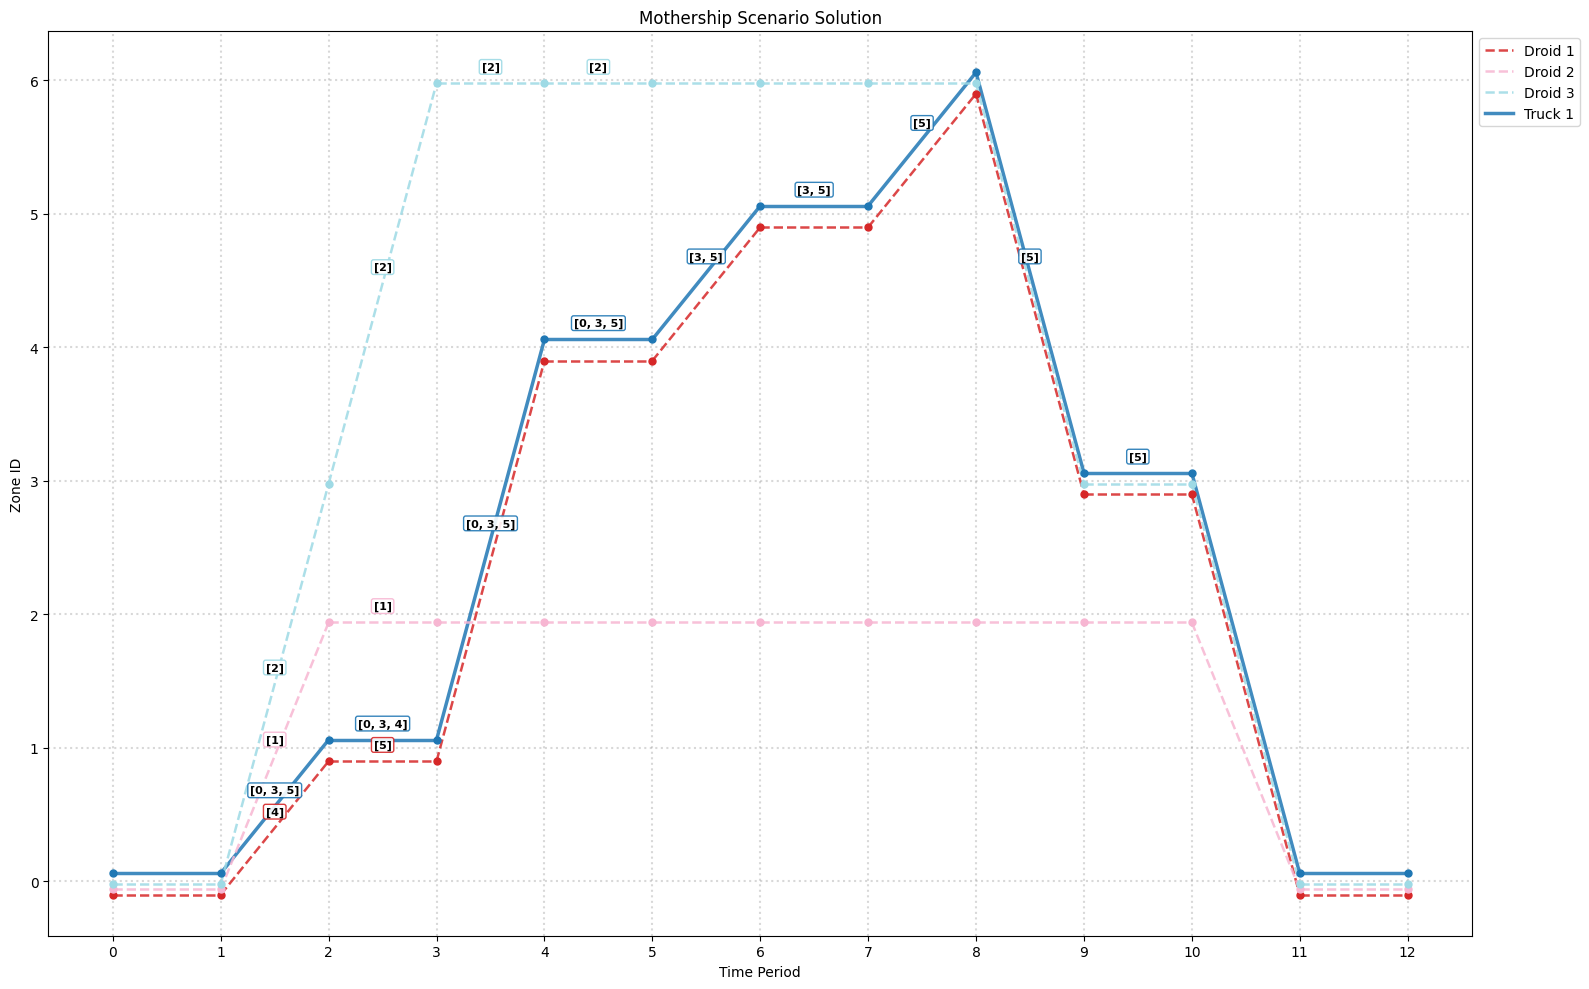

In [37]:
# TODO: Create visualization of Scenario 1 solution for small instance
# Suggestions:
# - Network plot showing truck routes and droid routes
# - Gantt chart showing vehicle schedules over time
# - Service completion timeline

Base_case_small_graph = visualize_time_space_solution(model_small, G_small)


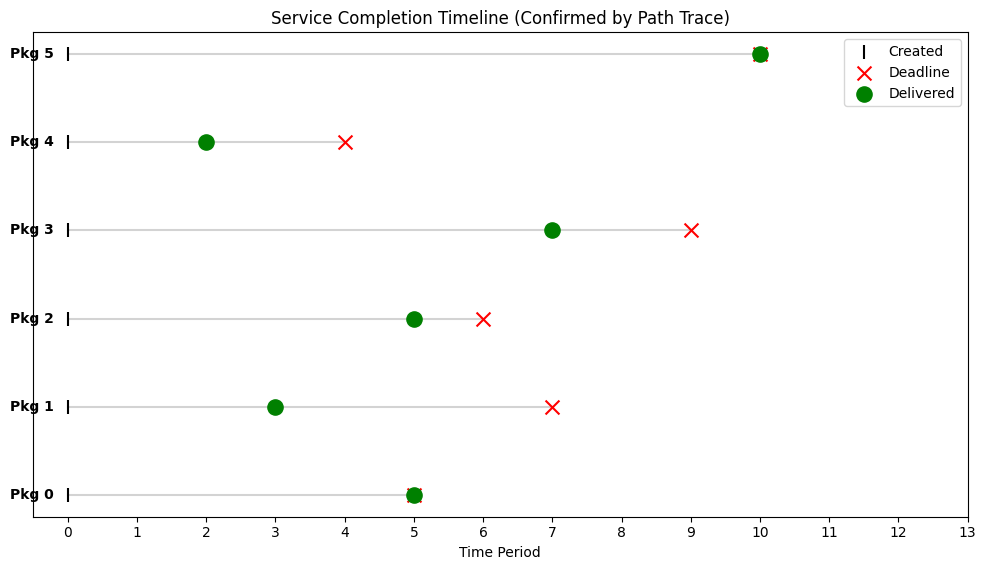

In [11]:
Base_case_small_service_time = plot_service_timeline(model=model_small, deliveries=deliveries_S, depot=depot_S, time_periods=T_S)

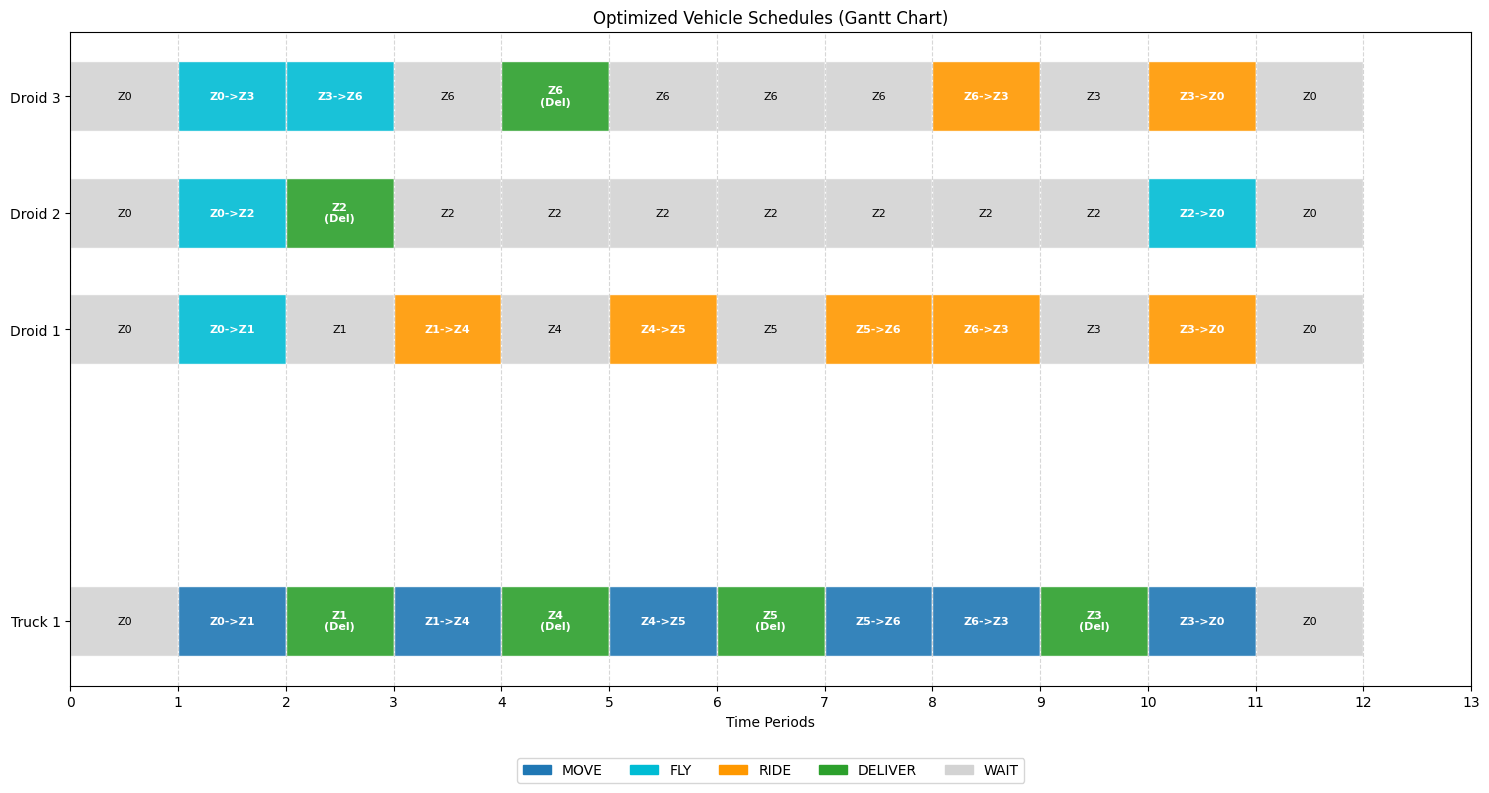

In [12]:
Base_case_small_gantt_chart = plot_gantt_chart(model=model_small, depot=depot_S, time_periods=T_S)

## 1.5 Results - Large Instance

In [ ]:
# Load large instance

zones_L, adjacency_L, T_L, depot_L, deliveries_L, pickups_L, params_L = load_instance('instance_student_large.json')
T_L=T_L+1
G_large = build_time_space_multigraph(zones_L, adjacency_L, T_L, depot=0)

model_large = solve_scenario_energy_tracking(zones_L, adjacency_L, T_L, depot_L, deliveries_L, pickups_L, params_L, G_large)


# TODO: Display results
print(f"Objective Value: {model_large.ObjVal}")
print(f"Solve Time: {model_large.Runtime:.2f}s")
# TODO: Add more result analysis


Generating x variables with pruning...
Set parameter TimeLimit to value 2000
Set parameter Method to value 2
Set parameter Presolve to value 2
Gurobi Optimizer version 12.0.0 build v12.0.0rc1 (win64 - Windows 10.0 (19045.2))

CPU model: AMD Ryzen 5 5600H with Radeon Graphics, instruction set [SSE2|AVX|AVX2]
Thread count: 6 physical cores, 12 logical processors, using up to 12 threads

Non-default parameters:
TimeLimit  2000
Method  2
Presolve  2
Seed  42

Optimize a model with 31298 rows, 54424 columns and 234703 nonzeros
Model fingerprint: 0x29dd9ae1
Variable types: 0 continuous, 54424 integer (19431 binary)
Coefficient statistics:
  Matrix range     [1e+00, 2e+01]
  Objective range  [5e-01, 5e+01]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 3e+01]
Presolve removed 15530 rows and 13510 columns
Presolve time: 1.55s
Presolved: 15768 rows, 40914 columns, 149697 nonzeros
Variable types: 0 continuous, 40914 integer (14305 binary)
Root relaxation presolve removed 23 rows an

In [ ]:
# 1. Update the time limit (this is the limit for the NEXT call)
model_large.Params.TimeLimit = 3600*2  

# 2. Adjust focus to find better IP solution, not focus on the LP value bound
# MIPFocus=1 tells Gurobi to prioritize finding NEW feasible solutions 
# rather than just trying to prove the current one is the best.
model_large.Params.MIPFocus = 1 
model_large.Params.Heuristics = 0.5 # Spend 50% of time on clever search shortcuts

# 3. Resume the search
model_large.optimize()

Set parameter TimeLimit to value 1600
Set parameter MIPFocus to value 1
Set parameter Heuristics to value 0.5
Gurobi Optimizer version 12.0.0 build v12.0.0rc1 (win64 - Windows 10.0 (19045.2))

CPU model: AMD Ryzen 5 5600H with Radeon Graphics, instruction set [SSE2|AVX|AVX2]
Thread count: 6 physical cores, 12 logical processors, using up to 12 threads

Non-default parameters:
TimeLimit  1600
Method  2
Heuristics  0.5
MIPFocus  1
Presolve  2
Seed  42

Optimize a model with 31298 rows, 54424 columns and 234703 nonzeros
Model fingerprint: 0x29dd9ae1
Variable types: 0 continuous, 54424 integer (19431 binary)
Coefficient statistics:
  Matrix range     [1e+00, 2e+01]
  Objective range  [5e-01, 5e+01]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 3e+01]
Presolved: 15768 rows, 40914 columns, 149697 nonzeros

Continuing optimization...

   436   308  119.20972   52 1299  145.00000   98.02833  32.4%  5973 2063s
H  437   308                     123.5000000   98.02833  20.6%  5959 2

## 1.6 Visualization - Large Instance


DETAILED TRUCK OPERATIONS REPORT

TRUCK #1
  --------------------------------------------------------------------------------------------------------------
  Time         | Zone  | Energy   | Activity                            | Payload              | Notes
  --------------------------------------------------------------------------------------------------------------
  0 -> 1       | 0     | -        | DELIVERING [] (Truck)               | -                    | 
  1 -> 2       | 0     | -        | Driving -> Z1                       | [0, 2, 4]            | Carrying 3 Droid(s)
  2 -> 3       | 1     | -        | Driving -> Z0                       | -                    | 
  3 -> 4       | 0     | -        | Driving -> Z2                       | [1, 3, 8, 10]        | Carrying 1 Droid(s)
  4 -> 5       | 2     | -        | Driving -> Z8                       | [1, 3, 8, 10]        | Carrying 2 Droid(s)
  5 -> 6       | 8     | -        | Driving -> Z9                       | [1, 3,

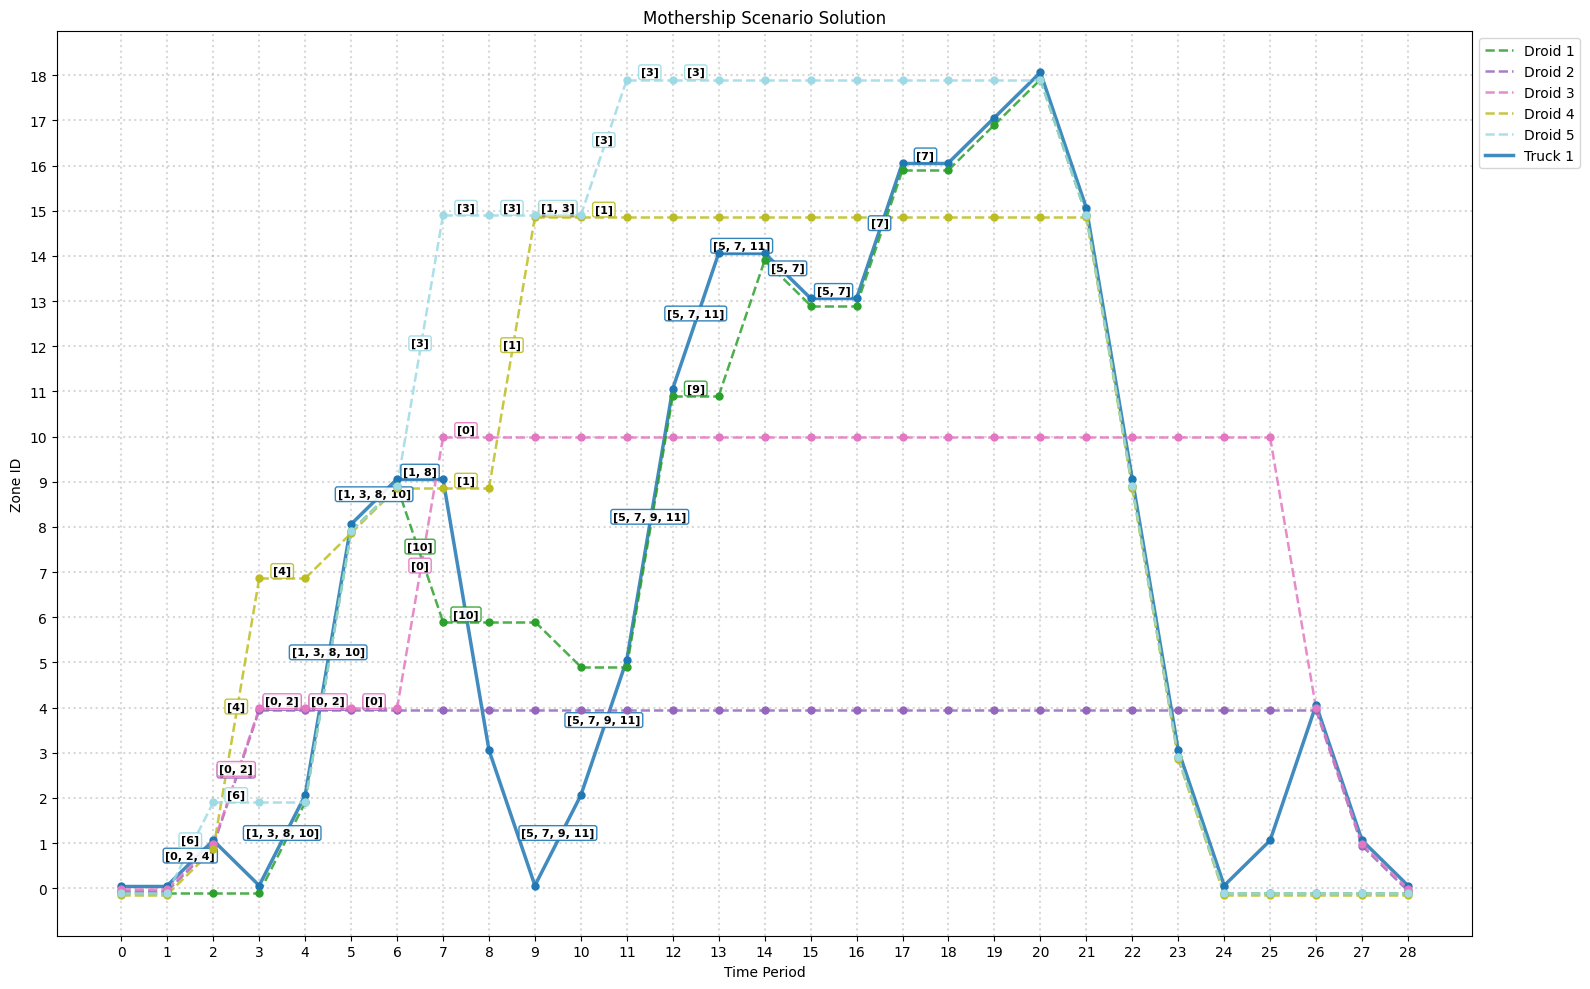

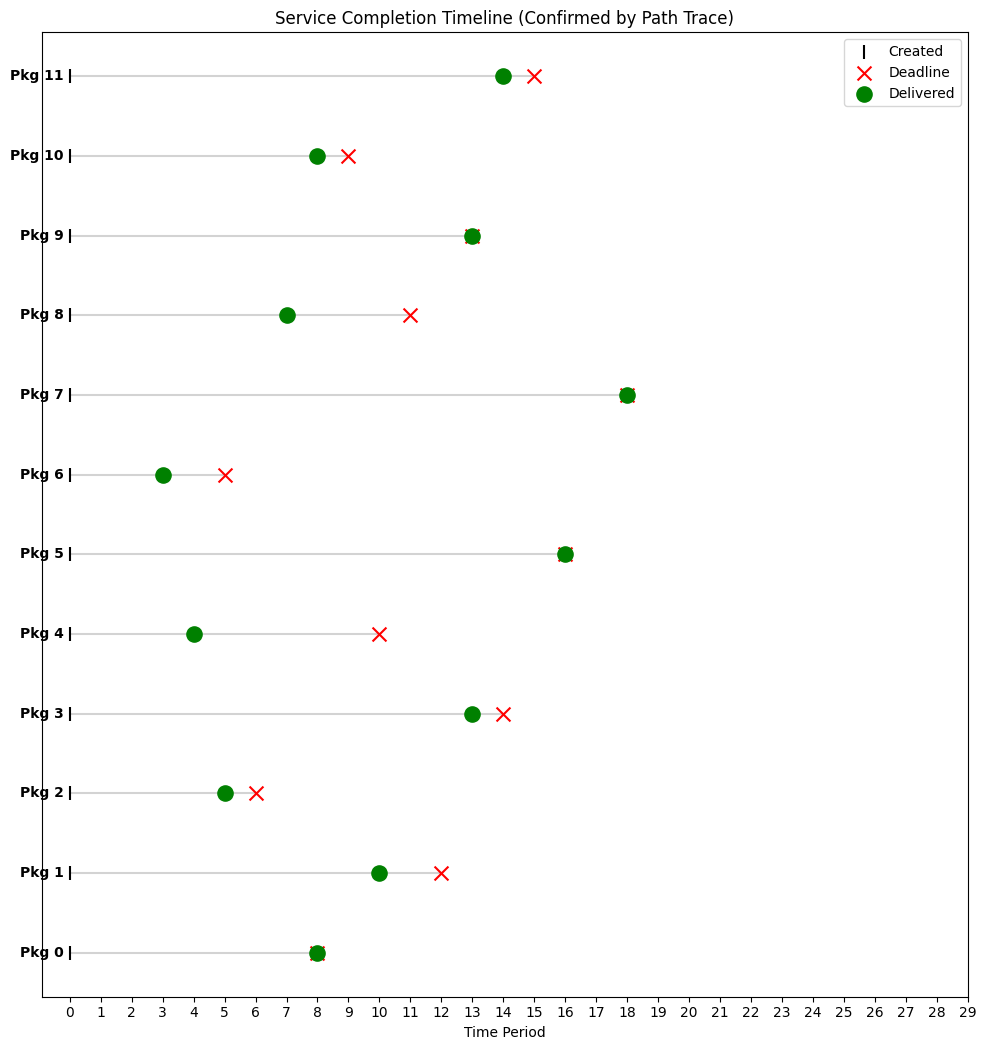

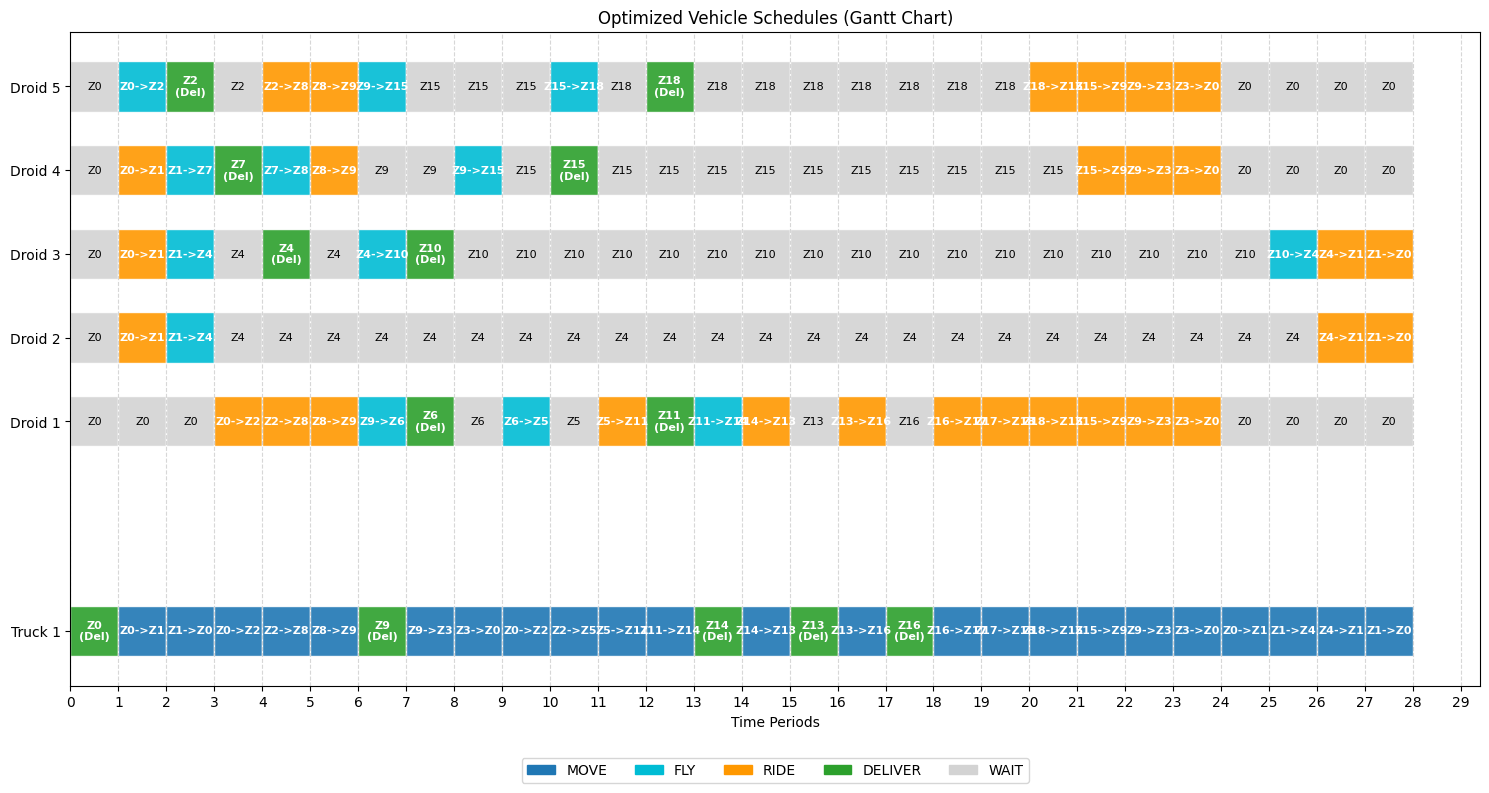

In [ ]:

try:
    print_detailed_fleet_status(model=model_large, deliveries=deliveries_L, depot=depot_L, time_periods=T_L)
    Base_case_large_graph = visualize_time_space_solution(model_large, G_large)
    Base_case_large_service_time = plot_service_timeline(model=model_large, deliveries=deliveries_L, depot=depot_L, time_periods=T_L)
    Base_case_large_gantt_chart = plot_gantt_chart(model=model_large, depot=depot_L, time_periods=T_L)
except:
    print("Solution Did not Produce Feasible Integer Results for Large Instance In the given time")

---

# Scenario 2: Routing with Recharging

**Objective:** Minimize total arc usage with recharging capability.

**Features:**
- All features from Scenario 1
- **New:** Droids can recharge energy by riding on trucks
- Energy resets when droid boards/alights from truck
- Track excursion energy separately
- No pickup requests

---

### Mathematical Formulation

#### Sets and Indices
* $\mathcal{Z}$: Set of zones (spatial nodes).
* $\mathcal{T} = \{0, \dots, T_{max}\}$: Set of time periods.
* $\mathcal{N}$: Set of time-space nodes, where $u = (z, t) \in \mathcal{N}$.
* $\mathcal{A}$: The complete set of directed arcs in the time-space graph, where flow moves from $t$ to $t+1$.
    * $\mathcal{A}_{Truck} \subseteq \mathcal{A}$: Arcs traversable by Trucks.
    * $\mathcal{A}_{Droid} \subseteq \mathcal{A}$: Arcs traversable by Droids (Flying or Riding).
    * $\mathcal{A}_{Del} \subseteq \mathcal{A}$: Arcs designated for delivery actions.
    * $\mathcal{A}_{Shelf} \subseteq \mathcal{A}$: Virtual arcs at the Depot for package storage.
* $\mathcal{K}$: Set of all parcels (deliveries + pickups).
* $\mathcal{F}$: Set of all fleet types $\{\text{Truck}, \text{Droid}, \text{Del\_Tr}, \text{Del\_Dr}, \text{Depot\_Shelf}\}$.
* $\mathcal{E} = \{0, \dots, R\}$: Set of discrete energy levels for droids.
* $Pred(n)$: Set of Predecessor nodes (incoming arcs to $n$).
* $Succ(n)$: Set of Successor nodes (outgoing arcs from $n$).


#### Parameters
* $C_{fix}^{truck}$: Fixed cost for using a truck.
* $C_{move}^{truck}$: Cost per arc for a truck moving between different zones.
* $C_{wait}^{truck}$: Cost per arc for a truck waiting in the same zone.
* $C_{energy}^{droid}$: Cost per unit of energy consumed by a droid.
* $E_{move}, E_{del}$: Energy consumption for moving and delivering.
* $R$: Maximum energy capacity of a droid.

#### Decision Variables
* $x_{ij}^{k,f} \in \{0, 1\}$: Binary variable. 1 if parcel $k$ traverses arc $(i,j)$ using fleet $f$.
* $y_{ij}^{f} \in \mathbb{Z}_{\geq 0}$: Integer variable. Number of vehicles of fleet type $f$ traversing arc $(i,j)$.
* $z_{ij, e}^{fly} \in \mathbb{Z}_{\geq 0}$: Number of droids flying (moving under own power) on arc $(i,j)$ arriving with energy level $e$ (Waiting is included).
* $z_{ij, e}^{del} \in \mathbb{Z}_{\geq 0}$: Number of droids performing a delivery action on arc $(i,j)$ ending with energy level $e$.
* $z_{ij, e}^{ride} \in \mathbb{Z}_{\geq 0}$: Number of droids rding a truck on arc $(i,j)$ ending with energy level $e$.

#### Objective Function
Minimize the total cost, comprising variable truck costs, droid energy costs, and fixed truck costs:

$$
\begin{aligned}
\text{Minimize } Z = \quad & \sum_{(i,j) \in \mathcal{A}} \sum_{f \in \mathcal{F}_{truck}} y_{ij}^f \cdot C_{ij}^{truck} \quad && \text{(Truck Variable Cost)} \\
+ & \sum_{(i,j) \in \mathcal{A}} \sum_{e \in \mathcal{E}} C_{energy}^{droid} \left( z_{ij,e}^{fly} \cdot E_{move} + z_{ij,e}^{del} \cdot E_{del} \right) \quad && \text{(Droid Energy Cost)} \\
+ & \sum_{j \in \mathcal{N}} y_{(depot, 0), j}^{Truck} \cdot C_{fix}^{truck} \quad && \text{(Truck Fixed Cost)}
\end{aligned}
$$

Where the truck arc cost $C_{ij}^{truck}$ is defined as:
$$
C_{ij}^{truck} = 
\begin{cases} 
C_{move}^{truck} & \text{if } i_{zone} \neq j_{zone} \\
C_{wait}^{truck} & \text{if } i_{zone} = j_{zone}
\end{cases}
$$

### Constraints

#### 1. Flow Conservation
This ensures the parcel moves through the network continuously.
* **Source:** The parcel is generated at the **Depot** at $t=0$ (Net flow = 1).
* **Intermediate:** Flow entering a node must equal flow leaving it (Net flow = 0).
* **Sink (Implicit):** If a parcel takes a **Delivery Arc**, it leaves the current node but is **not** added to the inflow of the next node (effectively exiting the network).

$$
\sum_{(u, v) \in \mathcal{A}} \sum_{f \in \mathcal{F}} x_{u, v}^{k,f} - \sum_{(w, u) \in \mathcal{A}} \sum_{f \notin \mathcal{F}_{del}} x_{w, u}^{k,f} = 
\begin{cases} 
1 & \text{if } u = (\text{Depot}, 0) \\
0 & \text{otherwise}
\end{cases}
\quad \forall u \in \mathcal{N}, \forall k \in \mathcal{K}
$$

> **Note:** The second term (Inflow) explicitly **excludes** delivery fleets ($f \notin \mathcal{F}_{del}$).

#### 2. Force Service (Deadline Satisfaction)
This constraint ensures that for every parcel $k$, exactly one "Delivery" action occurs at the target zone $z_{target}$ on or before the due time $T_{due}$.

$$
\sum_{t=1}^{T_{due}} \sum_{f \in \{\text{Del\_Dr}, \text{Del\_Tr}\}} x_{(z_{target}, t-1), (z_{target}, t)}^{k,f} = 1 \quad \forall k \in \mathcal{K}
$$

### Why Delivery Timing is exactly after the package enters a "delivery" vehicle

**1. Delivery is a Movement, Not a Status**
The variable $x_{t, t+1}^{del}$ represents the specific action of moving from the network into the delivery state. It is not a checkmark; it is a flow variable.

**2. The Chain of Custody**
For a delivery to occur at a later time $t+k$, the variable $x_{t+k, t+k+1}^{del}$ must be set to 1.
However, flow constraints dictate that a variable can only be 1 if there is **input flow** at node $t+k$ (i.e., the package is present).

**3. The Impossibility of Delay**
If the package exits the network at time $t$ (via $x_{t, t+1}^{del}=1$):
* **Flow Termination:** The package is removed from the system. The flow at all subsequent nodes ($t+1, t+2, \dots$) becomes 0.
* **Broken Chain:** Since flow at $t+k$ is 0, the variable $x_{t+k, t+k+1}^{del}$ is forced to 0.

**Conclusion:**
You cannot deliver what you do not have. Once the package exits, it is gone. Therefore, the "Force Service" credit ($\sum x = 1$) is always awarded at the exact instant the exit occurs.


### 3 Asset Balance & Global Fleet Limits

These constraints manage the available fleet size at the depot ($t=0$) and ensure vehicles are conserved (flow in = flow out) throughout the timeline.

#### 3.1. Global Truck Limit (at $t=0$)
The total number of trucks (both moving and delivering types) leaving the depot at time 0 cannot exceed the available fleet size $N_{truck}$.

$$
\sum_{(v) \in \text{neighbors}(\text{Depot},0)} \sum_{f \in \{\text{Truck}, \text{Del\_Tr}\}} y_{(\text{Depot},0), v}^{f} \leq N_{truck}
$$

#### 3.2. Global Droid Limit & Initial Energy (at $t=0$)
The total number of droids (flying, riding, or delivering) leaving the depot at time 0 cannot exceed $N_{droid}$. Furthermore, all droids leaving the depot must start with full energy capacity ($e=R$). Later FFC for droids done via the Energy level constraint.

**Limit Constraint:**
$$
\sum_{(v) \in \text{neighbors}(\text{Depot},0)} \sum_{e=0}^{R} \left( z_{(\text{Depot},0), v, e}^{fly} + z_{(\text{Depot},0), v, e}^{ride} + z_{(\text{Depot},0), v, e}^{del} \right) \leq N_{droid}
$$

**Full Energy Enforcement. Drouds with lower energy are not allowed at t=0:**
$$
z_{(\text{Depot},0), v, e}^{\{fly, ride, del\}} = 0 \quad \forall e < R
$$

#### 3.3. Truck Asset Balance (Flow Conservation)
For all intermediate time-space nodes ($0 < t < T_{max}$), the number of trucks arriving must equal the number of trucks departing.

$$
\sum_{(u, n) \in \mathcal{A}} \sum_{f \in \{\text{Truck}, \text{Del\_Tr}\}} y_{u, n}^{f} = \sum_{(n, v) \in \mathcal{A}} \sum_{f \in \{\text{Truck}, \text{Del\_Tr}\}} y_{n, v}^{f} \quad \forall n = (z, t) \text{ where } 0 < t < T_{max}
$$

### 4. Capacity Constraints

We ensure that the number of parcels assigned to a specific fleet type $f$ on arc $(u,v)$ does not exceed the capacity of the active vehicles of that type.

#### Case 4.1: Flying Droids ($f = \text{"Droid"}$)
For droids moving autonomously(flying or waiting), the capacity is provided by the sum of all flying droids across valid energy levels. Riding does not provide capcity on the arc for droids. Those packages get reassinged to the truck

$$
\sum_{k \in \mathcal{K}} x_{u, v}^{k, \text{Droid}} \leq Q_{\text{Droid}} \cdot \left( \sum_{e=0}^{R} z_{u, v, e}^{fly} \right) \quad \forall (u, v) \in \mathcal{A}
$$

#### Case 4.2: Trucks, Delivery Fleets, and Shelf ($f \neq \text{"Droid"}$)
For all other fleet types (Trucks, Delivery actions, and the Virtual Shelf), the capacity is linked to the generic flow variable $y$.

$$
\sum_{k \in \mathcal{K}} x_{u, v}^{k, f} \leq Q_{f} \cdot y_{u, v}^{f} \quad \forall (u, v) \in \mathcal{A}, \forall f \in \{\text{Truck}, \text{Del\_Tr}, \text{Del\_Dr}, \text{Shelf}\}
$$

**Where:**
* $Q_f$: The capacity parameter (`cap_per_fleet`) for fleet $f$.

### 5. Coupling & Mothership Constraints

These constraints ensure consistency between the detailed energy states ($z$) and the aggregate fleet flows ($y$), and enforce the physical limits of trucks carrying droids.

#### 5.1. Mothership Constraint (Capacity)
If droids are riding, they must be carried by a truck. The total number of riding droids cannot exceed the specific droid-carrying capacity of the trucks traversing that arc.
*Note: Both standard "Trucks" and "Delivery Trucks" can carry droids.*

$$
\sum_{e=0}^{R} z_{u, v, e}^{ride} \leq C_{truck}^{droid} \cdot \left( y_{u, v}^{\text{Truck}} + y_{u, v}^{\text{Del\_Tr}} \right) \quad \forall (u, v) \in \mathcal{A}_{\text{Droid}}
$$

#### 5.2. Droid Delivery Coupling
For arcs representing a delivery action, the aggregate delivery flow ($y^{\text{Del\_Dr}}$) must equal the sum of droids performing the delivery across valid energy levels. This still exists from previous itterations, where I used it. Currently everything is done via the "z"-variable, but I haven't changed the code, so I keep it for completeleness

$$
\sum_{e=0}^{R} z_{u, v, e}^{del} = y_{u, v}^{\text{Del\_Dr}} \quad \forall (u, v) \in \mathcal{A}_{\text{Del\_Dr}}
$$

**Where:**
* $C_{truck}^{droid}$: Parameter `Cap_T_Droid` (Max droids a single truck can carry).
* $\mathcal{A}_{\text{Droid}}$: Set of arcs where droid movement is allowed.
* $\mathcal{A}_{\text{Del\_Dr}}$: Set of arcs where droid delivery is allowed.

### 6. Energy Balance (Recharge on Ride)

This constraint ensures flow conservation for droids at every energy level $e$. It uses a **Backtracking Logic**: standing at the arrival node $n$, it pulls flow from all valid predecessors $p$.

**Constraint Logic:**
$$
\underbrace{ \sum_{p} z_{p, n, (e + C_{fly})}^{fly} }_{\text{Inflow: Flying}} 
+ \underbrace{ \sum_{p} z_{p, n, (e + C_{del})}^{del} }_{\text{Inflow: Delivery}} 
+ \underbrace{ \delta_{e,R} \cdot \left( \sum_{p} \sum_{k=0}^{R} z_{p, n, k}^{ride} \right) }_{\text{Inflow: Recharging Riders}} 
\quad = \quad
\underbrace{ \sum_{v} \left( z_{n, v, e}^{fly} + z_{n, v, e}^{ride} + z_{n, v, e}^{del} \right) }_{\text{Total Outflow}}
$$

**Where:**
* $\delta_{e,R}$:. It acts as a switch ($1$ if $e=R$, else $0$). This ensures riders only "re-appear" at the Full Energy level.
* **Backtracking Logic:** The constraint looks backwards. To arrive at energy $e$, a droid must have come from a higher energy level $(e+Cost)$ via flying, **OR** (if $e=R$) it could have come from *any* energy level via a truck ride.
* **Linearity (Energy State Routing):** The recharge process is modeled strictly as **flow routing** through a multi-layered graph, rather than as a non-linear algebraic calculation.
    * **Visualizing Energy Levels:** Imagine the network as having a "vertical" dimension, where different layers represent discrete **Energy States** (e.g., from $E_{0}$ to $E_{max}$).
    * **Movement Between Levels:** A "Ride" or "Recharge" arc acts like an elevator; it does not just move the vehicle horizontally in space and time, but specifically directs the flow to the **"Full Energy" node** (level $E_{max}$) at the destination.
    * **Mathematical Implication:** Because the change in energy state is encoded in the graph's structure (the arc's destination) rather than a formula, we avoid complex non-linear constraints. The solver simply sums the flows arriving at the "Full" level.



### 7. Strong Linking & Valid Inequalities (Cuts)

This constraint ensures that a parcel $k$ cannot be assigned to a truck fleet on arc $(u,v)$ unless a truck is actually traversing that arc.
*It links the binary decision $x$ to the integer decision $y$.*

$$
x_{u, v}^{k, f} \leq \sum_{f' \in \{\text{Truck}, \text{Del\_Tr}\}} y_{u, v}^{f'} \quad \forall (u,v) \in \mathcal{A}, \forall k \in \mathcal{K}, \forall f \in \{\text{Truck}, \text{Del\_Tr}\}
$$


## 2.2 Implementation

Implement Scenario 2 model in the cell below.

In [13]:
# TODO: Implement Scenario 2 model


def solve_scenario_energy_recharge(zones, adjacency, time_periods, depot, deliveries, pick_ups, params, G):
    """
    Solves Scenario 1 with:
    - Fixed Droid Energy Range (R).
    - Mothership logic.
    - STATIONARY VIRTUAL VEHICLE: 'Depot_Shelf' allows packages to stay at depot.
    """

    # --- 1. Parameters ---
    R = params['energy_capacity']
    Cap_T_Droid = params['truck_droid_capacity']
    E_cost_move = 1
    E_cost_deliver = 1
    E_cost_wait = 0 
    
    # Capacity of virtual vehicle equals total possible parcels
    total_potential_parcels = len(deliveries) + len(pick_ups)
    
    cap_per_fleet = {
        "Truck": params['truck_parcel_capacity'],
        "Deliver_Truck": params['truck_parcel_capacity'],
        "Droid": params['droid_parcel_capacity'],
        "Deliver_Droid": params['droid_parcel_capacity'],
        "Depot_Shelf": total_potential_parcels # Virtual Vehicle Capacity
    }
    
    fleet_limits = {"Truck": params['num_trucks'], "Droid": params['num_droids']}
    
    # --- 2. Graph Pre-processing ---
    arcs_config = {} 
    for u, v, data in G.edges(data=True):
        if (u, v) not in arcs_config: arcs_config[(u, v)] = set()
        a_type = data.get('arc_type')
        
        if a_type == "Truck":
            arcs_config[(u, v)].add("Truck")
        elif a_type == "Droid":
            arcs_config[(u, v)].add("Droid")
        elif a_type == "Deliver": 
            arcs_config[(u, v)].add("Deliver_Droid")
            arcs_config[(u, v)].add("Deliver_Truck")

    # --- NEW: Add Virtual Vehicle Arcs (Waiting at Depot only) ---
    for t in range(time_periods - 1):
        u_depot = (int(depot), t)
        v_depot = (int(depot), t + 1)
        if (u_depot, v_depot) not in arcs_config: 
            arcs_config[(u_depot, v_depot)] = set()
        arcs_config[(u_depot, v_depot)].add("Depot_Shelf")

    unique_arcs = list(arcs_config.keys())
    
    model = gp.Model("Scenario_1_Virtual_Vehicle")

    # --- 3. Decision Variables ---
    spatial_graph = nx.DiGraph()
    for (u, v) in arcs_config.keys():
        spatial_graph.add_edge(u[0], v[0], weight=1 if u[0] != v[0] else 0)
        
    try:
        min_time_dist = dict(nx.all_pairs_dijkstra_path_length(spatial_graph))
    except:
        min_time_dist = {}

    print("Generating x variables with pruning...")
    x = {}
    skipped_vars = 0
    
    # Package release time is 1, but they can exist on the shelf at t=0
    GLOBAL_START_TIME = 1 

    for d in deliveries:
        k, target_zone, deadline = d['id'], d['zone'], d['due_time']
        start_zone = int(depot)
        
        for (u, v), allowed in arcs_config.items():
            cur_z, cur_t = u
            next_z, next_t = v
            
            # Pruning Check: If it's the shelf, it can exist at T=0
            if "Depot_Shelf" not in allowed and cur_t < GLOBAL_START_TIME:
                skipped_vars += 1
                continue

            # --- PRUNING CHECK 1: DEADLINE ---
            time_remaining = deadline - next_t
            req_time = min_time_dist.get(next_z, {}).get(target_zone, 9999) 
            if req_time > time_remaining:
                skipped_vars += 1
                continue 
            
            # --- PRUNING CHECK 2: START ---
            dist_from_start = min_time_dist.get(start_zone, {}).get(cur_z, 9999)
            time_elapsed = cur_t - 0 # Use 0 because of the shelf
            if dist_from_start > time_elapsed:
                skipped_vars += 1
                continue 
            
            for f in allowed:
                x[k, u, v, f] = model.addVar(vtype=GRB.BINARY, name=f"x_{k}_{u}_{v}_{f}")

    # y: Fleet Flow
    y = {}
    for (u, v), allowed in arcs_config.items():
        for f in allowed:
            y[f, u, v] = model.addVar(vtype=GRB.INTEGER, lb=0.0, name=f"y_{f}_{u}_{v}")
            # --- FORCE VIRTUAL VEHICLE FLOW ---
            if f == "Depot_Shelf":
                model.addConstr(y[f, u, v] == 1, name=f"Shelf_Active_{u[1]}")
            
    # z: Energy State (Droids Only)
    z_fly, z_ride, z_deliver = {}, {}, {}
    for (u, v), allowed in arcs_config.items():
        if "Droid" in allowed:
            # Important: Droids can wait at depot or move
            dist_cost = E_cost_wait if u[0] == v[0] else E_cost_move
            for e in range(R + 1):
                # Only create z_fly if the droid has enough energy to traverse the arc
                if e >= dist_cost: 
                    z_fly[u, v, e] = model.addVar(vtype=GRB.INTEGER, lb=0, name=f"z_fly_{u}_{v}_{e}")
                
                # z_ride costs 0 energy, so it can always exist for any energy level e
                z_ride[u, v, e] = model.addVar(vtype=GRB.INTEGER, lb=0, name=f"z_ride_{u}_{v}_{e}")
        
        if "Deliver_Droid" in allowed:
            for e in range(R + 1):
                if e >= E_cost_deliver: 
                    z_deliver[u, v, e] = model.addVar(vtype=GRB.INTEGER, lb=0, name=f"z_del_{u}_{v}_{e}")

    model.update()

    # --- 4. Objective Function ---
    cost_truck_fixed = float(params.get('truck_fixed_cost', 0))
    cost_truck_move = float(params.get('truck_movement_cost', 0))
    cost_truck_wait = float(params.get('truck_waiting_cost', 0))
    cost_droid_energy = float(params.get('droid_energy_cost', 0))

    obj_truck_var = gp.quicksum(y[f, u, v] * (cost_truck_move if u[0] != v[0] else cost_truck_wait) 
                               for (f, u, v) in y if "Truck" in f)
    
    obj_droid_var = gp.quicksum(cost_droid_energy * z_fly[u, v, e] * E_cost_move for (u, v, e) in z_fly if u[0] != v[0]) + \
                    gp.quicksum(cost_droid_energy * z_deliver[u, v, e] * E_cost_deliver for (u, v, e) in z_deliver)

    start_arcs_truck = [y[f, u, v] for (f, u, v) in y if "Truck" in f and u == (int(depot), 0)]
    obj_truck_fixed = gp.quicksum(cost_truck_fixed * v for v in start_arcs_truck)

    model.setObjective(obj_truck_var + obj_droid_var + obj_truck_fixed, GRB.MINIMIZE)

    # --- 6. Constraints ---

    # 1. Flow Conservation (Origin is Depot at Time 0)
    for d in deliveries:
        k, dest_zone = d['id'], d['zone']
        origin = (int(depot), 0) # Now starting from T=0
        for node in G.nodes():
            f_in = gp.quicksum(x[k, u, v, f] for (u, v) in unique_arcs if v == node for f in arcs_config[u, v] 
                               if (k, u, v, f) in x and (("Deliver" not in f) or (dest_zone != u[0])))
            f_out = gp.quicksum(x[k, u, v, f] for (u, v) in unique_arcs if u == node for f in arcs_config[u, v] if (k, u, v, f) in x)
            
            if node == origin:
                model.addConstr(f_out - f_in == 1, name=f"Origin_{k}")
            else:
                model.addConstr(f_out - f_in == 0, name=f"Cons_{k}_{node}")

    # --- 6.2 Asset Balance & Global Fleet Limits ---
    for node in G.nodes():
        node_z, node_t = node
        
        # 1. TRUCK FLEET LIMIT
        if node_z == depot and node_t == 0:
            truck_types = ["Truck", "Deliver_Truck"]
            t_start = [y[f, u, v] for (u, v) in unique_arcs if u == node for f in truck_types if (f, u, v) in y]
            if t_start:
                model.addConstr(gp.quicksum(t_start) <= fleet_limits["Truck"], name="Global_Truck_Limit")
        
        # 2. DROID FLEET LIMIT (STRICT: Includes Deliveries and forces Energy = R)
        if node_z == depot and node_t == 0:
            d_start = []
            # Count every droid leaving (Depot, 0)
            d_start += [z_fly[u, v, e] for (u, v, e) in z_fly if u == node]
            d_start += [z_ride[u, v, e] for (u, v, e) in z_ride if u == node]
            d_start += [z_deliver[u, v, e] for (u, v, e) in z_deliver if u == node]
            
            if d_start:
                model.addConstr(gp.quicksum(d_start) <= fleet_limits["Droid"], name="Global_Droid_Limit")
                
            # OPTIONAL: Force droids to start with Full Energy (R)
            # This prevents them from starting at energy 4 if R=5.
            d_low_energy = [z_fly[u,v,e] for (u,v,e) in z_fly if u==node and e < R] + \
                           [z_ride[u,v,e] for (u,v,e) in z_ride if u==node and e < R] + \
                           [z_deliver[u,v,e] for (u,v,e) in z_deliver if u==node and e < R]
            for var in d_low_energy:
                model.addConstr(var == 0, name=f"Force_Full_Energy_{var.VarName}")

        # 3. TRUCK ASSET BALANCE (0 < t < T-1)
        if node_t > 0 and node_t < time_periods - 1:
            truck_types = ["Truck", "Deliver_Truck"]
            t_in  = [y[f, u, v] for (u, v) in unique_arcs if v == node for f in truck_types if (f, u, v) in y]
            t_out = [y[f, u, v] for (u, v) in unique_arcs if u == node for f in truck_types if (f, u, v) in y]
            if t_in or t_out:
                model.addConstr(gp.quicksum(t_out) == gp.quicksum(t_in), name=f"Truck_Flow_Balance_{node}")

        # 3. TRUCK ASSET BALANCE (Flow Conservation)
        # Balancing trucks for all intermediate time steps (0 < t < T-1)
        if node_t > 0 and node_t < time_periods - 1:
            truck_types = ["Truck", "Deliver_Truck"]
            t_in  = [y[f, u, v] for (u, v) in unique_arcs if v == node for f in truck_types if (f, u, v) in y]
            t_out = [y[f, u, v] for (u, v) in unique_arcs if u == node for f in truck_types if (f, u, v) in y]
            if t_in or t_out:
                model.addConstr(gp.quicksum(t_out) == gp.quicksum(t_in), name=f"Truck_Flow_Balance_{node}")

    # 3. Capacity
    for (u, v), allowed in arcs_config.items():
        for f in allowed:
            cap = cap_per_fleet[f]
            pkgs = gp.quicksum(x[d['id'], u, v, f] for d in deliveries if (d['id'], u, v, f) in x)
            if f == "Droid":
                active = gp.quicksum(z_fly[u, v, e] for e in range(R+1) if (u, v, e) in z_fly)
                model.addConstr(pkgs <= cap * active, name=f"Cap_{u}_{v}_{f}")
            else:
                model.addConstr(pkgs <= cap * y[f, u, v], name=f"Cap_{u}_{v}_{f}")

    # 4. Force Service
    for d in deliveries:
        k, z_tgt, t_due = d['id'], d['zone'], d['due_time']
        valid_v = [x[k, (z_tgt, t-1), (z_tgt, t), f] for t in range(1, t_due + 1) 
                   for f in ["Deliver_Droid", "Deliver_Truck"] if (k, (z_tgt, t-1), (z_tgt, t), f) in x]
        if valid_v: model.addConstr(gp.quicksum(valid_v) == 1, name=f"MustDel_{k}")

    # 5. Coupling & 6. Mothership
    for (u, v), allowed in arcs_config.items():
        if "Droid" in allowed:
            # Safely sum only existing keys
            fly_sum = gp.quicksum(z_fly[u, v, e] for e in range(R + 1) if (u, v, e) in z_fly)
            ride_sum = gp.quicksum(z_ride[u, v, e] for e in range(R + 1) if (u, v, e) in z_ride)
            
            model.addConstr(fly_sum + ride_sum == y["Droid", u, v], name=f"Droid_Coupling_{u}_{v}")
            
            # Mothership logic: riders must be <= capacity of actual trucks on this arc
            t_flow = gp.quicksum(y[f, u, v] for f in ["Truck", "Deliver_Truck"] if (f, u, v) in y)
            model.addConstr(ride_sum <= Cap_T_Droid * t_flow, name=f"Mothership_{u}_{v}")

        if "Deliver_Droid" in allowed:
            del_sum = gp.quicksum(z_deliver[u, v, e] for e in range(R + 1) if (u, v, e) in z_deliver)
            model.addConstr(del_sum == y["Deliver_Droid", u, v], name=f"DelDroid_Coupling_{u}_{v}")

    # --- 7. Energy Balance (Recharge on Ride - Robust) ---
    for node in G.nodes():
        node_z, node_t = node
        
        # Skip absolute start and end
        if node_t == 0 or node_t == time_periods - 1:
            continue
            
        # 1. Collect Inflows by Source Type
        # A. From Field (Flying/Delivering) -> Maintains energy level 'e' (minus cost)
        # B. From Truck (Riding) -> ALWAYS arrives at Energy R (Full Charge)
        
        inflow_from_truck = []
        # Check for droids arriving via truck from previous time step
        for p in G.predecessors(node):
            if (p, node) not in arcs_config: continue
            if "Droid" in arcs_config[(p, node)]:
                # Sum over ALL possible energy levels they had when they boarded
                for e_prev in range(R + 1):
                    if (p, node, e_prev) in z_ride:
                        inflow_from_truck.append(z_ride[p, node, e_prev])

        for e in range(R + 1):
            t_in = []
            
            # --- Field Inflow ---
            for p in G.predecessors(node):
                if (p, node) not in arcs_config: continue
                al = arcs_config[(p, node)]
                
                # Case A: Flying/Waiting (e_in = e_out + cost)
                cost_move = E_cost_wait if p[0] == node[0] else E_cost_move
                if "Droid" in al and (e + cost_move) <= R:
                    if (p, node, e + cost_move) in z_fly:
                        t_in.append(z_fly[p, node, e + cost_move])
                
                # Case B: Delivering (e_in = e_out + cost)
                if "Deliver_Droid" in al and (e + E_cost_deliver) <= R:
                    if (p, node, e + E_cost_deliver) in z_deliver:
                        t_in.append(z_deliver[p, node, e + E_cost_deliver])

            # --- Truck Inflow (Recharge Logic) ---
            # If we are at the FULL ENERGY level (e == R), we add the truck arrivals here.
            if e == R:
                t_in.extend(inflow_from_truck)

            # --- Outflow ---
            t_out = []
            for n in G.neighbors(node):
                if (node, n, e) in z_fly: t_out.append(z_fly[node, n, e])
                if (node, n, e) in z_deliver: t_out.append(z_deliver[node, n, e])
                
                # IMPORTANT: Droids leaving via TRUCK (Ride)
                # They leave from the CURRENT energy level 'e' 
                # (and will appear at 'R' at the next node due to the logic above)
                if (node, n, e) in z_ride: t_out.append(z_ride[node, n, e])

            # --- Constraint ---
            if t_in or t_out:
                model.addConstr(gp.quicksum(t_in) == gp.quicksum(t_out), name=f"EnergyBal_{node}_E{e}")

    # --- 8. Strong Linking & Cuts ---
    for (u, v), allowed in arcs_config.items():
        t_vars = [y[f, u, v] for f in ["Truck", "Deliver_Truck"] if (f, u, v) in y]
        if t_vars:
            total_t = gp.quicksum(t_vars)
            for d in deliveries:
                for f in ["Truck", "Deliver_Truck"]:
                    if (d['id'], u, v, f) in x: model.addConstr(x[d['id'], u, v, f] <= total_t)

    """
    # Global Work Cut
    total_km = sum(min_time_dist.get(int(depot), {}).get(d['zone'], 0) for d in deliveries)
    t_cap_prov = gp.quicksum(cap_per_fleet["Truck"] * y[f,u,v] for (f,u,v) in y if "Truck" in f and u[0]!=v[0])
    d_cap_prov = gp.quicksum(cap_per_fleet["Droid"] * z_fly[u,v,e] for (u,v,e) in z_fly if u[0]!=v[0])
    model.addConstr(t_cap_prov + d_cap_prov >= total_km, name="Global_Work_Cut")

    # Destination Inflow Cuts
    pkg_zones = {}
    for d in deliveries: pkg_zones[d['zone']] = pkg_zones.get(d['zone'], 0) + 1
    for z_dest, count in pkg_zones.items():
        in_cap = gp.quicksum(cap_per_fleet["Truck"]*y[f,u,v] for (f,u,v) in y if "Truck" in f and v[0]==z_dest and u[0]!=z_dest) + \
                 gp.quicksum(cap_per_fleet["Droid"]*z_fly[u,v,e] for (u,v,e) in z_fly if v[0]==z_dest and u[0]!=z_dest) + \
                 gp.quicksum(cap_per_fleet["Deliver_Droid"]*y["Deliver_Droid",u,v] for (u,v),al in arcs_config.items() if v[0]==z_dest and u[0]!=z_dest and "Deliver_Droid" in al)
        model.addConstr(in_cap >= count, name=f"Inflow_Cut_{z_dest}")
    """

    time=  3600*3   # 60 minutes
    model.Params.TimeLimit = time
    model.Params.Method = 2
    model.Params.Presolve = 2
    model.optimize()
    return model

## 2.3 Results - Small Instance

In [14]:
model_small_recharge = solve_scenario_energy_recharge(zones_S, adjacency_S, T_S, depot_S, deliveries_S, pickups_S, params_S, G_small)

# TODO: Display results
print(f"Objective Value: {model_small_recharge.ObjVal}")
print(f"Solve Time: {model_small_recharge.Runtime:.2f}s")
# TODO: Add analysis of excursions, recharging events, etc.

Generating x variables with pruning...
Set parameter TimeLimit to value 10800
Set parameter Method to value 2
Set parameter Presolve to value 2
Gurobi Optimizer version 12.0.0 build v12.0.0rc1 (win64 - Windows 10.0 (19045.2))

CPU model: AMD Ryzen 5 5600H with Radeon Graphics, instruction set [SSE2|AVX|AVX2]
Thread count: 6 physical cores, 12 logical processors, using up to 12 threads

Non-default parameters:
TimeLimit  10800
Method  2
Presolve  2
Seed  42

Optimize a model with 3250 rows, 5161 columns and 20370 nonzeros
Model fingerprint: 0x92994aaf
Variable types: 0 continuous, 5161 integer (1718 binary)
Coefficient statistics:
  Matrix range     [1e+00, 9e+00]
  Objective range  [5e-01, 5e+01]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 3e+00]
Presolve removed 1694 rows and 1680 columns
Presolve time: 0.28s
Presolved: 1556 rows, 3481 columns, 11240 nonzeros
Variable types: 0 continuous, 3481 integer (964 binary)
Root relaxation presolve removed 6 rows and 0 columns


## 2.4 Visualization - Small Instance

In [60]:
# TODO: Create visualization showing excursions and recharging events
print_detailed_fleet_status(model_small_recharge, deliveries_S, depot_S, T_S)


DETAILED TRUCK OPERATIONS REPORT

TRUCK #1
  --------------------------------------------------------------------------------------------------------------
  Time         | Zone  | Energy   | Activity                            | Payload              | Notes
  --------------------------------------------------------------------------------------------------------------
  0 -> 1       | 0     | -        | DELIVERING [] (Truck)               | -                    | 
  1 -> 2       | 0     | -        | Driving -> Z1                       | [0, 3, 4]            | 
  2 -> 3       | 1     | -        | DELIVERING [4] (Truck)              | [0, 3, 4]            | 
  3 -> 4       | 1     | -        | Driving -> Z4                       | [0, 3]               | 
  4 -> 5       | 4     | -        | DELIVERING [0] (Truck)              | [0, 3]               | 
  5 -> 6       | 4     | -        | Driving -> Z5                       | [3]                  | 
  6 -> 7       | 5     | -        | DEL

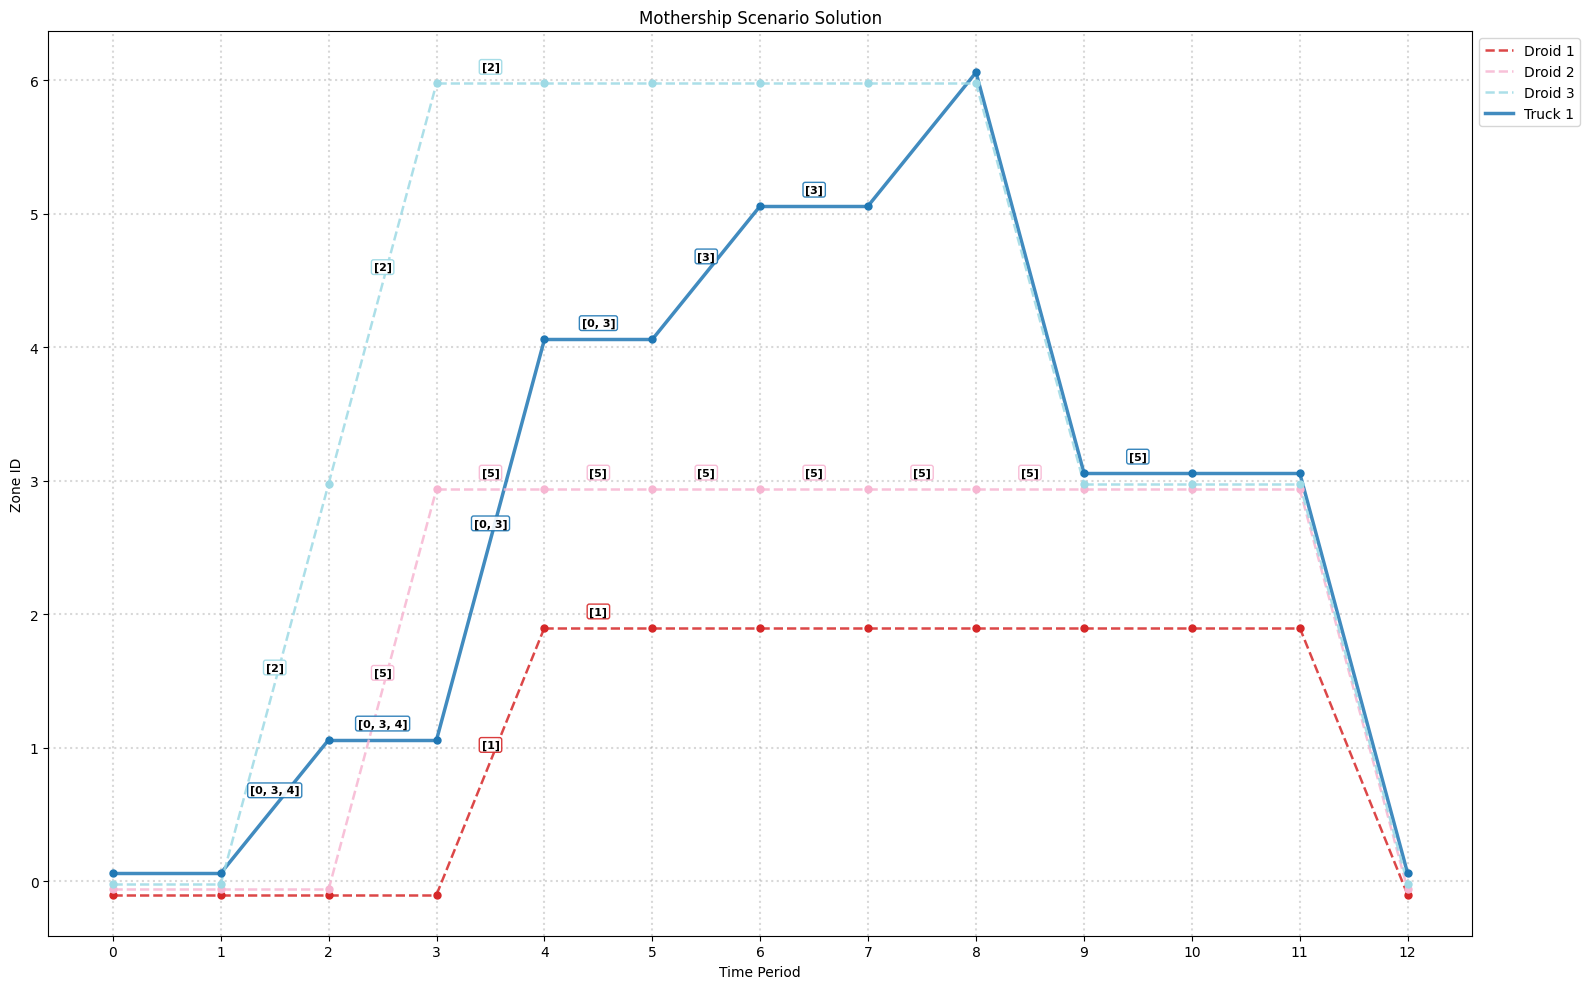

In [15]:
Recharge_case_small_graph = visualize_time_space_solution(model_small_recharge, G_small)

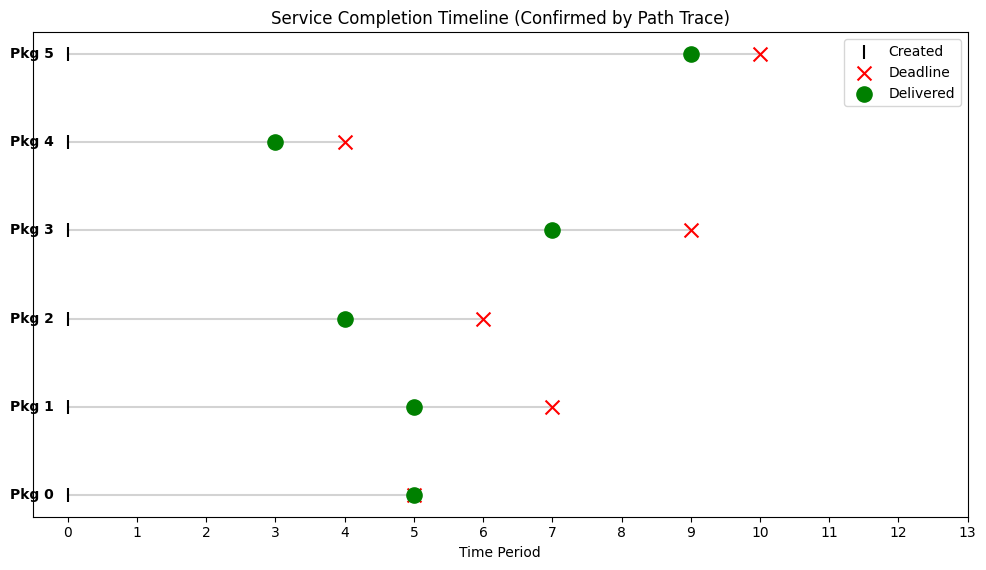

In [16]:
Recharge_case_small_service_time = plot_service_timeline(model=model_small_recharge, deliveries=deliveries_S, depot=depot_S, time_periods=T_S)

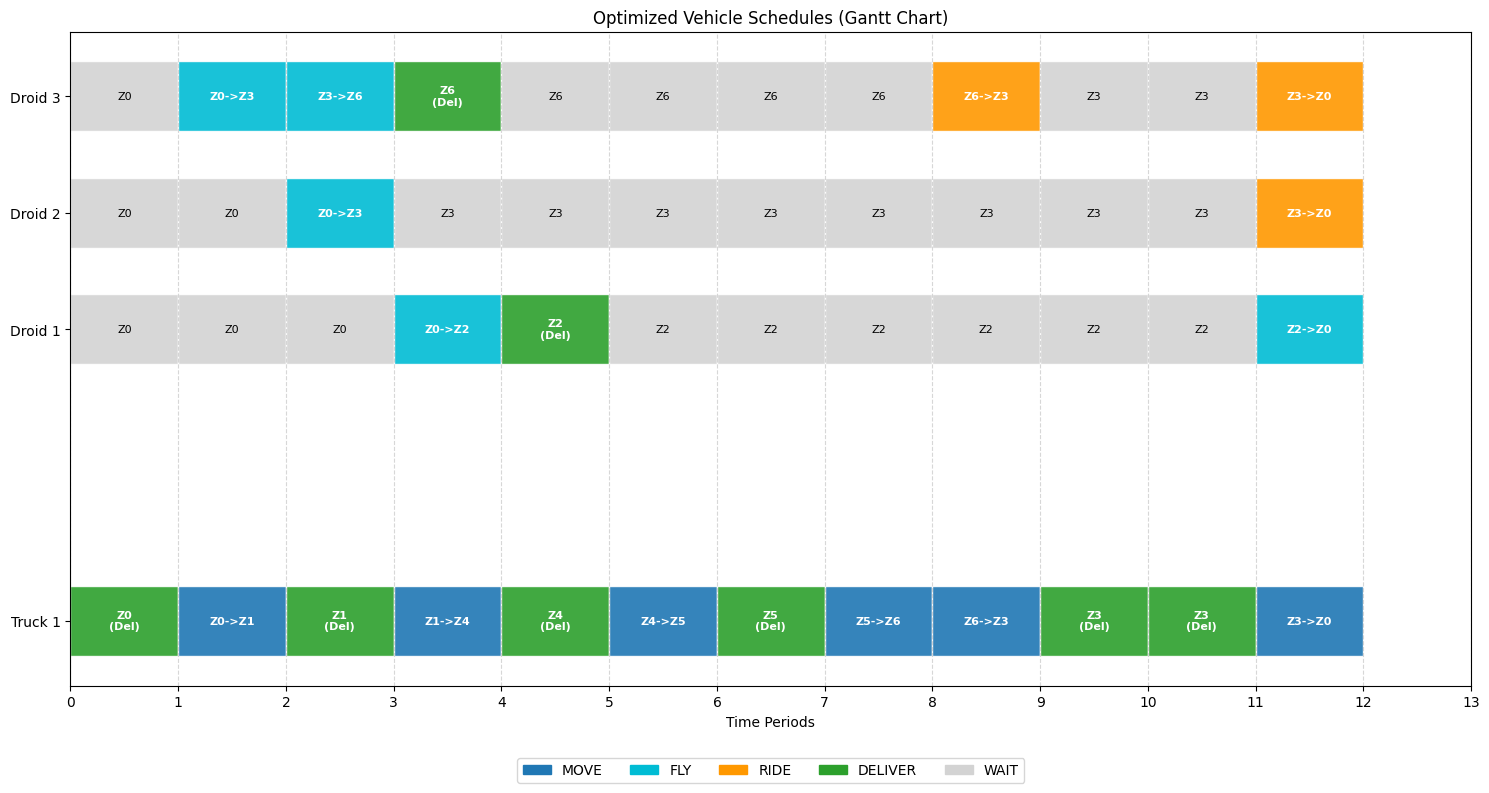

In [17]:
Recharge_case_small_gantt_chart = plot_gantt_chart(model=model_small_recharge, depot=depot_S, time_periods=T_S)

## 2.5 Results - Large Instance

In [ ]:
# Load large instance

model_large_rechare = solve_scenario_energy_recharge(zones_L, adjacency_L, T_L, depot_L, deliveries_L, pickups_L, params_L, G_large)

# TODO: Display results
print(f"Objective Value: {model_large_rechare.ObjVal}")
print(f"Solve Time: {model_large_rechare.Runtime:.2f}s")


Generating x variables with pruning...
Set parameter TimeLimit to value 2000
Set parameter Method to value 2
Set parameter Presolve to value 2
Gurobi Optimizer version 12.0.0 build v12.0.0rc1 (win64 - Windows 10.0 (19045.2))

CPU model: AMD Ryzen 5 5600H with Radeon Graphics, instruction set [SSE2|AVX|AVX2]
Thread count: 6 physical cores, 12 logical processors, using up to 12 threads

Non-default parameters:
TimeLimit  2000
Method  2
Presolve  2
Seed  42

Optimize a model with 31298 rows, 54424 columns and 234703 nonzeros
Model fingerprint: 0x3757f4d0
Variable types: 0 continuous, 54424 integer (19431 binary)
Coefficient statistics:
  Matrix range     [1e+00, 2e+01]
  Objective range  [5e-01, 5e+01]
  Bounds range     [1e+00, 1e+00]
  RHS range        [1e+00, 3e+01]
Presolve removed 15095 rows and 11408 columns
Presolve time: 1.43s
Presolved: 16203 rows, 43016 columns, 156643 nonzeros
Variable types: 0 continuous, 43016 integer (14305 binary)
Root relaxation presolve removed 12 rows an

In [ ]:
# 1. Update the time limit (this is the limit for the NEXT call)
model_large_rechare.Params.TimeLimit = 3600*2  

# 2. Adjust focus to search for better IP solution.
# MIPFocus=1 tells Gurobi to prioritize finding NEW feasible solutions 
# rather than just trying to prove the current one is the best.
model_large_rechare.Params.MIPFocus = 1 
model_large_rechare.Params.Heuristics = 0.5 # Spend 50% of time on clever search shortcuts

# 3. Resume the search
model_large_rechare.optimize()

## 2.6 Visualization - Large Instance

In [19]:
try:
    print_detailed_fleet_status(model=model_large_rechare,deliveries=deliveries_L,depot=depot_L, time_periods=T_L)
    Recharge_case_large_graph = visualize_time_space_solution(model_large_rechare, G_large)
    Recharge_case_large_service_time = plot_service_timeline(model=model_large_rechare, deliveries=deliveries_L, depot=depot_L, time_periods=T_L)
    Recharge_case_large_gantt_chart = plot_gantt_chart(model=model_large_rechare, depot=depot_L, time_periods=T_L)
except:
    print("Solution Did not Produce Feasible Integer Results for Large Instance In the given time")

Solution Did not Produce Feasible Integer Results for Large Instance In the given time


---

# Scenario 3: Complete Model with Pickups and Transfers

**Objective:** Minimize total arc usage with full parcel flow tracking.

**Features:**
- All features from Scenario 2
- **New:** Pickup requests with release times
- **New:** Parcel flow tracking (continuous variables)
- **New:** Parcel transfers between vehicles
- Vehicle capacity constraints

---

## 3.1 Mathematical Formulation

### Mathematical Formulation

#### Sets and Indices
* $\mathcal{Z}$: Set of zones (spatial nodes).
* $\mathcal{T} = \{0, \dots, T_{max}\}$: Set of time periods.
* $\mathcal{N}$: Set of time-space nodes, where $u = (z, t) \in \mathcal{N}$.
* $\mathcal{A}$: The complete set of directed arcs in the time-space graph.
    * $\mathcal{A}_{Truck} \subseteq \mathcal{A}$: Arcs traversable by Trucks.
    * $\mathcal{A}_{Droid} \subseteq \mathcal{A}$: Arcs traversable by Droids (Flying or Riding).
    * $\mathcal{A}_{Del} \subseteq \mathcal{A}$: Arcs designated for delivery actions.
    * $\mathcal{A}_{Inv} \subseteq \mathcal{A}$: Inventory arcs for holding items at a zone $(t \to t+1)$ (for pick-ups).
    * $\mathcal{A}_{Shelf} \subseteq \mathcal{A}$: Virtual arcs at the Depot for package storage.
* $\mathcal{K} = \mathcal{K}_{del} \cup \mathcal{K}_{pick}$: Set of all parcels, disjointly split into Deliveries and Pickups.
* $\mathcal{F}$: Set of all fleet types, defined as $\{\text{Truck}, \text{Droid}, \text{Del\_Tr}, \text{Pick\_Tr}, \text{Del\_Dr}, \text{Pick\_Dr}, \text{Shelf}\}$.
* $\mathcal{E} = \{0, \dots, R\}$: Set of discrete energy levels for droids.

#### Parameters
* **Capacities & Limits:**
    * $Q_{parcel}^{f}$: Parcel carrying capacity for fleet type $f$.
    * $Q_{mother}$: Capacity of a Truck to carry Droids (Mothership capacity).
    * $N_{truck}, N_{droid}$: Maximum number of vehicles available.
* **Costs & Energy:**
    * $C_{fix}^{f}, C_{var}^{f}$: Fixed and variable costs for fleet $f$.
    * $E_{move}$: Energy consumption for a droid moving or waiting ($E_{wait} \approx 0$).
    * $E_{del}$: Energy consumption for performing a delivery.
    * $E_{pick}$: Energy consumption for performing a pickup.
    * $R$: Maximum energy capacity of a droid.
* **Time Windows:**
    * $T_{start}$: Global start time for operations.
    * $r_k$: Release time for parcel $k$ (Time $k$ becomes available).
    * $d_k$: Due time (deadline) for parcel $k$.

#### Decision Variables
* **Flow of Parcels:**
    * $x_{ij}^{k,f} \in \{0, 1\}$: Binary variable. 1 if parcel $k$ traverses arc $(i,j)$ using fleet type $f$ (or Inventory/Shelf).

* **Fleet Movement & Management:**
    * $y_{ij}^{f} \in \mathbb{Z}_{\geq 0}$: Integer variable. Number of vehicles of fleet type $f$ traversing arc $(i,j)$.
        * Note: For $f=\text{Shelf}$, this is fixed to 1 to represent the open depot storage.

* **Droid Energy States:**
    * $z_{ij, e}^{fly} \in \mathbb{Z}_{\geq 0}$: Number of droids moving under own power (or waiting) on arc $(i,j)$, arriving with energy level $e$.
    * $z_{ij, e}^{ride} \in \mathbb{Z}_{\geq 0}$: Number of droids riding on a truck on arc $(i,j)$, arriving with energy level $e$.
    * $z_{ij, e}^{del} \in \mathbb{Z}_{\geq 0}$: Number of droids performing a **delivery** on arc $(i,j)$, ending with energy level $e$.
    * $z_{ij, e}^{pick} \in \mathbb{Z}_{\geq 0}$: Number of droids performing a **pickup** on arc $(i,j)$, ending with energy level $e$.

#### Objective Function
Minimize the total cost, comprising variable truck costs (movement and waiting), droid energy costs (flying, delivering, and picking up), and fixed truck costs.

$$
\begin{aligned}
\text{Minimize } Z = \quad & \sum_{(i,j) \in \mathcal{A}} \sum_{f \in \mathcal{F}_{truck}} y_{ij}^f \cdot C_{ij}^{truck} \quad && \text{(Truck Variable Cost)} \\
+ & \sum_{(i,j) \in \mathcal{A}} \sum_{e \in \mathcal{E}} C_{energy}^{droid} \left[ \mathbb{I}_{(i_{zone} \neq j_{zone})} \cdot z_{ij,e}^{fly} \cdot E_{move} + z_{ij,e}^{del} \cdot E_{del} + z_{ij,e}^{pick} \cdot E_{pick} \right] \quad && \text{(Droid Energy Cost)} \\
+ & \sum_{j \in \mathcal{N}} \sum_{f \in \mathcal{F}_{truck}} y_{(depot, 0), j}^{f} \cdot C_{fix}^{truck} \quad && \text{(Truck Fixed Cost)}
\end{aligned}
$$

Where:
* $\mathcal{F}_{truck} = \{\text{Truck, Del\_Tr, Pick\_Tr}\}$
* The truck arc cost $C_{ij}^{truck}$ is defined as:
    $$
    C_{ij}^{truck} = 
    \begin{cases} 
    C_{move}^{truck} & \text{if } i_{zone} \neq j_{zone} \\
    C_{wait}^{truck} & \text{if } i_{zone} = j_{zone}
    \end{cases}
    $$
* $\mathbb{I}_{(i_{zone} \neq j_{zone})}$ is an indicator function that is 1 if the droid is moving between zones (flying) and 0 if it is waiting (consistent with $E_{wait}=0$).

### Constraints

#### 1. Commodity Flow Conservation
These constraints ensure the physical continuity of parcel movement. We distinguish between deliveries (which leave the system upon service) and pickups (which enter the system and travel to the depot).

**Case A: Deliveries ($k \in \mathcal{K}_{del}$)**
* **Source:** Generated at Depot at $T_{start}$ ($+1$).
* **Sink (Implicit):** Upon taking a "Delivery" arc, the flow leaves the network (excluded from next node's inflow).

$$
\sum_{(u, v) \in \mathcal{A}} \sum_{f \in \mathcal{F}} x_{u, v}^{k,f} - \sum_{(w, u) \in \mathcal{A}} \sum_{f \notin \mathcal{F}_{del}} x_{w, u}^{k,f} = 
\begin{cases} 
1 & \text{if } u = (\text{Depot}, T_{start}) \\
0 & \text{otherwise}
\end{cases}
\quad \forall u \in \mathcal{N}, \forall k \in \mathcal{K}_{del}
$$

**Case B: Pickups ($k \in \mathcal{K}_{pick}$)**
* **Source:** Generated at the Customer Zone at Release Time $t_{rel}$ ($+1$).
* **Sink:** Absorbed at the Depot at the final time $T_{max}$ ($-1$).
* **Continuity:** Flow is conserved strictly throughout the path.

$$
\sum_{(u, v) \in \mathcal{A}} \sum_{f \in \mathcal{F}} x_{u, v}^{k,f} - \sum_{(w, u) \in \mathcal{A}} \sum_{f \in \mathcal{F}} x_{w, u}^{k,f} = 
\begin{cases} 
1 & \text{if } u = (z_{k}^{src}, t_{k}^{rel}) \\
-1 & \text{if } u = (\text{Depot}, T_{max}) \\
0 & \text{otherwise}
\end{cases}
\quad \forall u \in \mathcal{N}, \forall k \in \mathcal{K}_{pick}
$$

As an assumption, we set that all pick-up packages to be delivered at the Depot at the last timestep.

#### 2. Force Service
This ensures that every request is successfully served (loaded or delivered) exactly once.

* **Deliveries:** Must traverse a delivery arc (by Truck or Droid) at the target zone by the deadline.
* **Pickups:** Must traverse a pickup arc (by Truck or Droid) at the source zone starting from the release time.

$$
\begin{aligned}
& \sum_{t=1}^{T_{due}} \sum_{f \in \mathcal{F}_{del}} x_{(z_{target}, t-1), (z_{target}, t)}^{k,f} = 1 \quad && \forall k \in \mathcal{K}_{del} \\
& \sum_{t=t_{rel}}^{T_{max}} \sum_{f \in \mathcal{F}_{pick}} x_{(z_{src}, t), (z_{src}, t+1)}^{k,f} = 1 \quad && \forall k \in \mathcal{K}_{pick}
\end{aligned}
$$

Where:
* $\mathcal{F}_{del} = \{\text{Del\_Tr, Del\_Dr}\}$
* $\mathcal{F}_{pick} = \{\text{Pick\_Tr, Pick\_Dr}\}$

### 3 Asset Balance & Global Fleet Limits

These constraints manage the available fleet size at the depot ($t=0$) and ensure vehicles are conserved (flow in = flow out) throughout the timeline.

#### 3.1. Global Truck Limit (at $t=0$)
The total number of trucks (standard, delivery, and pickup) leaving the depot at time 0 cannot exceed the available fleet size $N_{truck}$.

$$
\sum_{v \in \text{neighbors}(\text{Depot},0)} \sum_{f \in \mathcal{F}_{truck}} y_{(\text{Depot},0), v}^{f} \leq N_{truck}
$$
Where $\mathcal{F}_{truck} = \{\text{Truck, Del\_Tr, Pick\_Tr}\}$.

#### 3.2. Global Droid Limit & Initial Energy (at $t=0$)
The total number of droids (flying, riding, delivering, or picking up) leaving the depot at time 0 cannot exceed $N_{droid}$. Furthermore, all droids leaving the depot must start with full energy capacity ($e=R$).

**Limit Constraint:**
$$
\sum_{v \in \text{neighbors}(\text{Depot},0)} \sum_{e=0}^{R} \left( z_{(\text{Depot},0), v, e}^{fly} + z_{(\text{Depot},0), v, e}^{ride} + z_{(\text{Depot},0), v, e}^{del} + z_{(\text{Depot},0), v, e}^{pick} \right) \leq N_{droid}
$$

**Full Energy Enforcement:**
All droids deploying from the depot must initiate operations with maximum charge. Let $\mathcal{M} = \{\text{fly, ride, del, pick}\}$ be the set of droid operating modes. We enforce:

$$
z_{(\text{Depot}, 0), v, e}^{\mu} = 0 \quad \forall v \in \text{Succ}(\text{Depot}, 0), \quad \forall e < R, \quad \forall \mu \in \mathcal{M}
$$

#### 3.3. Truck Asset Balance (Flow Conservation)
For all intermediate time-space nodes ($0 < t < T_{max}$), the number of trucks arriving must equal the number of trucks departing. This maintains the physical continuity of the truck fleet.

$$
\sum_{(u, n) \in \mathcal{A}} \sum_{f \in \mathcal{F}_{truck}} y_{u, n}^{f} = \sum_{(n, v) \in \mathcal{A}} \sum_{f \in \mathcal{F}_{truck}} y_{n, v}^{f} \quad \forall n = (z, t) \text{ where } 0 < t < T_{max}
$$

### 4. Capacity Constraints

We ensure that the total number of parcels (both deliveries and pickups) assigned to a specific fleet type $f$ on arc $(u,v)$ does not exceed the capacity provided by the active vehicles of that type.

#### Case 4.1: Flying Droids ($f = \text{Droid}$)
For droids moving autonomously (flying or waiting) on standard transit arcs, the capacity is provided by the total count of flying droids across all valid energy levels.
*Note: Droids "riding" on trucks do not provide capacity for parcels on the arc itself.*

$$
\sum_{k \in \mathcal{K}} x_{u, v}^{k, \text{Droid}} \leq Q_{\text{Droid}} \cdot \left( \sum_{e=0}^{R} z_{u, v, e}^{fly} \right) \quad \forall (u, v) \in \mathcal{A}
$$

#### Case 4.2: General Fleets ($f \neq \text{Droid}$)
For all other fleet types—including Trucks, Service Trucks (Deliver/Pickup), and the Virtual Shelf — the capacity is determined by the generic vehicle count variable $y_{u,v}^f$.

$$
\sum_{k \in \mathcal{K}} x_{u, v}^{k, f} \leq Q_{f} \cdot y_{u, v}^{f} \quad \forall (u, v) \in \mathcal{A}, \quad \forall f \in \mathcal{F}_{gen}
$$

**Where:**
* $\mathcal{K} = \mathcal{K}_{del} \cup \mathcal{K}_{pick}$ (All commodities).
* $\mathcal{F}_{gen} = \{\text{Truck, Del\_Tr, Pick\_Tr, Del\_Dr, Pick\_Dr, Shelf}\}$.
* $Q_f$ is the fleet capacity parameter (`cap_per_fleet`).

### 5. Coupling & Mothership Constraints

These constraints link the detailed droid energy states ($z$) to the aggregate fleet flows ($y$) and enforce physical carrying limits.

#### 5.1. Mothership Constraint (Capacity)
If droids are "riding," they must be physically carried by a truck. The total number of riding droids (across all energy levels) on an arc cannot exceed the carrying capacity of the trucks traversing that same arc.
*Note: All truck types (Standard, Delivery, and Pickup) are capable of carrying droids.*

$$
\sum_{e=0}^{R} z_{u, v, e}^{ride} \leq C_{truck}^{droid} \cdot \left( y_{u, v}^{\text{Truck}} + y_{u, v}^{\text{Del\_Tr}} + y_{u, v}^{\text{Pick\_Tr}} \right) \quad \forall (u, v) \in \mathcal{A}_{\text{Droid}}
$$

#### 5.2. Droid Delivery Coupling
For arcs representing a delivery action, the aggregate delivery flow ($y^{\text{Del\_Dr}}$) must correspond to the sum of droids actually performing the delivery action.

$$
\sum_{e=0}^{R} z_{u, v, e}^{del} = y_{u, v}^{\text{Del\_Dr}} \quad \forall (u, v) \in \mathcal{A}_{\text{Del\_Dr}}
$$

---

### 6. Inventory Restrictions & Precedence

These constraints enforce strict logical rules about where parcels can wait and ensure that items cannot move through the network before they have been physically picked up.

#### 6.1. Inventory Restrictions
To prevent unrealistic "floating" or "dropping" of parcels, items are only allowed to use **Inventory Arcs** (wait) at their specific valid locations:
* **Deliveries:** Can only wait at the **Depot Shelf**.
* **Pickups:** Can only wait at their **Source Zone** (before pickup).
* **Intermediate Zones:** No waiting allowed (Drop-offs banned).

$$
x_{(z, t), (z, t+1)}^{k, \text{Inventory}} = 0 \quad \text{if } z \notin \text{AllowedLocations}(k)
$$

#### 6.2. Pickup Precedence (Anti-Teleportation)
For pickup requests, a parcel cannot travel on a **Transit Arc** (Truck/Droid movement) unless the **Pickup Service** has already been completed. This prevents the model from moving a "ghost" package before the vehicle actually picks it up.

$$
\sum_{f \in \mathcal{F}_{transit}} x_{(z, t), (v, t+1)}^{k, f} \leq \sum_{\tau=0}^{t} \sum_{f \in \mathcal{F}_{pick}} \sum_{w} x_{(w, \tau-1), (z, \tau)}^{k, f}
$$

**Where:**
* $\mathcal{F}_{transit}$: Fleet types used for moving parcels (Trucks, Droids, Riding).
* $\mathcal{F}_{pick}$: Fleet types performing the pickup action.
* The RHS represents the "Inventory of Picked-up Items" available to move.

### 7. Energy Balance (Recharge on Ride)

This constraint ensures flow conservation for droids at every specific energy level $e$. It uses a **Backtracking Logic**: to be at node $n$ with energy $e$, a droid must have arrived from a predecessor $p$ starting with higher energy $e + Cost$.

**Constraint Logic:**
$$
\begin{aligned}
& \underbrace{ \sum_{p} z_{p, n, (e + Cost_{fly})}^{fly} }_{\text{Inflow: Flying/Waiting}} 
+ \underbrace{ \sum_{p} z_{p, n, (e + E_{del})}^{del} }_{\text{Inflow: Delivery}} 
+ \underbrace{ \sum_{p} z_{p, n, (e + E_{pick})}^{pick} }_{\text{Inflow: Pickup}} \\
+ & \underbrace{ \delta_{e,R} \cdot \left( \sum_{p} \sum_{k=0}^{R} z_{p, n, k}^{ride} \right) }_{\text{Inflow: Recharging Riders}} 
\quad = \quad
\underbrace{ \sum_{v} \left( z_{n, v, e}^{fly} + z_{n, v, e}^{ride} + z_{n, v, e}^{del} + z_{n, v, e}^{pick} \right) }_{\text{Total Outflow}}
\end{aligned}
$$

**Where:**
* $\delta_{e,R}$: Indicator ($1$ if $e=R$, else $0$). Riders effectively "reset" to full energy upon arrival.
* $Cost_{fly}$: Dynamically $E_{move}$ if $p_{zone} \neq n_{zone}$ (flying), or $E_{wait}$ if $p_{zone} = n_{zone}$ (waiting).
* **State Logic:** The constraint sums all possible ways to arrive at state $(n, e)$—whether by flying/waiting (draining $E_{move}$), working (draining $E_{del}$ or $E_{pick}$), or riding (recharging to $R$).

### 8. Strong Linking (Depot Initialization Cuts)

To strengthen the linear relaxation of the model, we apply "Strong Linking" constraints specifically at the Depot ($t=0$). This ensures that a delivery parcel $k$ cannot be assigned to leave the depot on a specific truck arc unless there is at least one active truck (of any type) traversing that arc.

$$
x_{(\text{Depot}, 0), v}^{k, f} \leq \sum_{g \in \mathcal{F}_{truck}} y_{(\text{Depot}, 0), v}^{g} 
\quad 
\forall v \in \text{Succ}(\text{Depot}, 0), \quad \forall k \in \mathcal{K}_{del}, \quad \forall f \in \mathcal{F}_{truck}
$$

**Where:**
* $\mathcal{F}_{truck} = \{\text{Truck, Del\_Tr, Pick\_Tr}\}$.
* **Logic:** If the total number of trucks (RHS) on the arc is 0, the binary assignment variable for the parcel (LHS) is forced to 0. If trucks exist, the constraint allows the flow ($x \le N$, where $N \ge 1$, allows $x=1$).




## 3.2 Implementation

Implement Scenario 3 model in the cell below.

In [20]:
#Graph Rebuilding Function
def build_time_space_multigraph_pick_and_deliver(zones, adjacency, T, depot=0):
    """
    Builds a time-space network where every arc guarantees the vehicle 
    can still reach the depot by the final time step.
    Includes 'Truck', 'Droid', 'Deliver', and 'Pickup' arcs.
    Robust to Integer vs String keys in adjacency dict.
    """
    G = nx.MultiDiGraph()

    # --- Step 1: Compute shortest path to depot for each zone (BFS) ---
    # We must know how far every zone is from the depot to enforce the return constraint.
    shortest_to_depot = {}
    
    # Initialize all as infinite
    for z in zones:
        shortest_to_depot[z] = float('inf')

    # BFS from Depot
    queue = [(depot, 0)]
    visited = {depot}
    shortest_to_depot[depot] = 0
    
    while queue:
        curr, dist = queue.pop(0)
        
        # FIX 1: Robust Lookup
        # Try finding neighbors using Integer key OR String key
        neighbors = adjacency.get(curr) or adjacency.get(str(curr)) or []
        
        for neighbor in neighbors:
            # Ensure neighbor is treated as int if your zones are ints
            neighbor = int(neighbor)
            
            if neighbor not in visited:
                visited.add(neighbor)
                shortest_to_depot[neighbor] = dist + 1
                queue.append((neighbor, dist + 1))

    # --- Step 2: Add nodes for all time steps ---
    for t in range(T):
        for z in zones:
            G.add_node((z, t))

    # --- Step 3: Add feasible arcs ---
    # We iterate up to T-1 because an arc goes from t -> t+1.
    for t in range(T - 1):
        for z in zones:

            # Constraint: Only the depot is active at t=0 (Source)
            if t == 0 and z != depot:
                continue
            
            # Skip if this node itself is unreachable or too far to ever return
            if shortest_to_depot[z] == float('inf'):
                continue

            # Identify all possible moves: Neighbors (Move) + Self (Wait/Service)
            # Again, robust lookup for neighbors
            real_neighbors = adjacency.get(z) or adjacency.get(str(z)) or []
            # Ensure ints
            real_neighbors = [int(n) for n in real_neighbors]
            
            targets = real_neighbors + [z]

            for z2 in targets:
                # --- THE RETURN CONSTRAINT ---
                # logic: Current Time (t) + Move (1) + Time to get Home from Dest (dist) <= Max Time (T-1)
                
                if shortest_to_depot[z2] != float('inf') and (t + 1 + shortest_to_depot[z2] <= T - 1):
                    
                    # 1. Standard Transport Arcs (Move or Wait)
                    G.add_edge((z, t), (z2, t + 1), arc_type="Truck")
                    G.add_edge((z, t), (z2, t + 1), arc_type="Droid")
                    
                    # 2. Service Arcs (Only if staying in the same zone)
                    if z == z2:
                        # Deliver Arc: Drop off a package
                        G.add_edge((z, t), (z2, t + 1), arc_type="Deliver")
                        
                        # NEW: Pickup Arc
                        # Pick up a package (Costs 1 time step, same as deliver)
                        G.add_edge((z, t), (z2, t + 1), arc_type="Pickup")

    return G


In [ ]:

def get_optimized_schedules_3(model, depot, time_periods):
    """
    Decomposes flow with explicit action tagging (Deliver, Pickup, Move).
    Includes logic to detect Pickup actions for Scenario 3.
    """
    # --- 1. Data Structures ---
    # Structure: adj[fleet][u] = [ {'v': v, 'tag': 'DELIVER'/'PICKUP'/'STD'} ]
    adj = {'Truck': {}, 'Droid': {}} 
    droid_modes = {} # (u, v) -> "RIDE" / "FLY" / "DELIVER" / "PICKUP"
    
    def parse_tuple(s):
        s = s.replace('(', '').replace(')', '')
        return tuple(map(int, s.split(',')))

    def get_fleet_key(raw):
        if "Truck" in raw: return "Truck"
        if "Droid" in raw: return "Droid"
        return raw

    # --- 2. Scan Variables ---
    for var in model.getVars():
        if var.X <= 0.001: continue
        name = var.VarName
        
        # A) Fleet Flow (y) - The Backbone of the path
        if name.startswith("y_"):
            # Regex: y_Fleet_(z1,t1)_(z2,t2)
            m = re.search(r"y_([a-zA-Z_]+)_\((.+?)\)_\((.+?)\)", name)
            if m:
                fleet_raw = m.group(1) 
                u = parse_tuple(m.group(2))
                v = parse_tuple(m.group(3))
                count = int(round(var.X))
                
                fleet_key = get_fleet_key(fleet_raw)
                
                # DETERMINE TAG: Is this flow a Delivery or Pickup?
                tag = "STD"
                if "Deliver" in fleet_raw:
                    tag = "DELIVER"
                elif "Pickup" in fleet_raw:  # <--- ADDED PICKUP CHECK
                    tag = "PICKUP"

                if fleet_key not in adj: adj[fleet_key] = {}
                if u not in adj[fleet_key]: adj[fleet_key][u] = []
                
                for _ in range(count):
                    adj[fleet_key][u].append({'v': v, 'tag': tag})

        # B) Droid Mode (z) - Helper for Ride vs Fly vs Pickup details
        elif name.startswith("z_"):
            m = re.search(r"z_([a-z]+)_\((.+?)\)_\((.+?)\)_(\d+)", name)
            if m:
                mode_raw = m.group(1) 
                u = parse_tuple(m.group(2))
                v = parse_tuple(m.group(3))
                
                # "ride", "fly", "del", "pick"
                if "ride" in mode_raw: mode = "RIDE"
                elif "del" in mode_raw: mode = "DELIVER"
                elif "pick" in mode_raw: mode = "PICKUP" # <--- ADDED PICKUP CHECK
                else: mode = "FLY"
                
                # Priority logic
                if (u,v) not in droid_modes or mode == "RIDE":
                    droid_modes[(u, v)] = mode

    # --- 3. Deterministic Sorting ---
    for f in adj:
        for u in adj[f]:
            adj[f][u].sort(key=lambda item: (item['v'][1], item['v'][0]))

    # --- 4. Reconstruct Paths ---
    schedules = {'Truck': [], 'Droid': []}
    start_node = (int(depot), 0) 

    for fleet in ['Truck', 'Droid']:
        current_adj = adj.get(fleet, {})
        
        # Only start paths from the Source (Depot, Time 0)
        while start_node in current_adj and len(current_adj[start_node]) > 0:
            path = []
            curr = start_node
            
            while True:
                if curr not in current_adj or not current_adj[curr]:
                    break
                
                # POP the next step
                step_data = current_adj[curr].pop(0)
                nxt = step_data['v']
                tag = step_data['tag']
                
                action = "WAIT"
                
                # --- TRUCK LOGIC ---
                if fleet == 'Truck':
                    if tag == "DELIVER":
                        action = "DELIVER"
                    elif tag == "PICKUP": # <--- ADDED PICKUP ACTION
                        action = "PICKUP"
                    elif curr[0] != nxt[0]: 
                        action = "MOVE"
                    else:
                        action = "WAIT"
                
                # --- DROID LOGIC ---
                else:
                    if tag == "DELIVER":
                        action = "DELIVER"
                    elif tag == "PICKUP": # <--- ADDED PICKUP ACTION
                        action = "PICKUP"
                    else:
                        # Fallback to Z-var metadata
                        mode = droid_modes.get((curr, nxt), "FLY")
                        if mode == "RIDE": action = "RIDE"
                        elif mode == "DELIVER": action = "DELIVER"
                        elif mode == "PICKUP": action = "PICKUP" # <--- ADDED PICKUP MODE
                        elif curr[0] != nxt[0]: action = "FLY"
                        else: action = "WAIT"

                path.append({
                    'start_time': curr[1],
                    'end_time': nxt[1],
                    'start_zone': curr[0],
                    'end_zone': nxt[0],
                    'action': action
                })
                
                curr = nxt
                if curr[1] >= time_periods - 1: break
            
            schedules[fleet].append(path)
            
    return schedules

def plot_gantt_chart_3(model, depot, time_periods):
    """
    Plots the Gantt Chart with PICKUP support.
    """
    schedules = get_optimized_schedules_3(model, depot, time_periods)
    
    fig, ax = plt.subplots(figsize=(15, 8)) 
    
    # Visual Configuration
    colors = {
        'MOVE': '#1f77b4',    # Blue (Truck Drive)
        'FLY': '#00bcd4',     # Cyan (Droid Fly)
        'RIDE': '#ff9800',    # Orange (Droid Ride)
        'DELIVER': '#2ca02c', # Green (Delivery)
        'PICKUP': '#9467bd',  # Purple (Pickup) <--- ADDED COLOR
        'WAIT': '#d3d3d3'     # Grey (Wait)
    }
    
    y_pos = 0
    y_ticks = []
    y_labels = []
    
    # --- 1. Plot Trucks ---
    for i, path in enumerate(schedules['Truck']):
        y_pos += 10
        label = f"Truck {i+1}"
        y_ticks.append(y_pos)
        y_labels.append(label)
        
        for leg in path:
            start, end = leg['start_time'], leg['end_time']
            dur = end - start
            action = leg['action']
            
            col = colors.get(action, 'black')
            
            # Draw Bar
            ax.barh(y_pos, dur, left=start, height=6, 
                    color=col, edgecolor='white', alpha=0.9)
            
            # Label Logic
            mid = start + dur/2
            if action == "MOVE":
                txt = f"Z{leg['start_zone']}->Z{leg['end_zone']}"
            elif action == "DELIVER":
                txt = f"Z{leg['start_zone']}\n(Del)"
            elif action == "PICKUP": # <--- ADDED PICKUP LABEL
                txt = f"Z{leg['start_zone']}\n(Pick)"
            else:
                txt = f"Z{leg['start_zone']}"
            
            # Text Formatting
            font_weight = 'bold' if action in ['DELIVER', 'PICKUP', 'MOVE'] else 'normal'
            txt_color = 'white' if action != 'WAIT' else 'black'
            
            ax.text(mid, y_pos, txt, 
                    ha='center', va='center', color=txt_color, 
                    fontsize=8, fontweight=font_weight)

    # Separator
    y_pos += 15
    
    # --- 2. Plot Droids ---
    for i, path in enumerate(schedules['Droid']):
        y_pos += 10
        label = f"Droid {i+1}"
        y_ticks.append(y_pos)
        y_labels.append(label)
        
        for leg in path:
            start, end = leg['start_time'], leg['end_time']
            dur = end - start
            action = leg['action']
            
            col = colors.get(action, 'black')
            
            # Draw Bar
            ax.barh(y_pos, dur, left=start, height=6, 
                    color=col, edgecolor='white', alpha=0.9)
            
            # Label Logic
            mid = start + dur/2
            if action == "FLY" or action == "RIDE":
                txt = f"Z{leg['start_zone']}->Z{leg['end_zone']}"
            elif action == "DELIVER":
                txt = f"Z{leg['start_zone']}\n(Del)"
            elif action == "PICKUP": # <--- ADDED PICKUP LABEL
                txt = f"Z{leg['start_zone']}\n(Pick)"
            else:
                txt = f"Z{leg['start_zone']}"

            # Text Formatting
            font_weight = 'bold' if action in ['DELIVER', 'PICKUP', 'FLY', 'RIDE'] else 'normal'
            txt_color = 'black' if action in ['WAIT'] else 'white'
            
            ax.text(mid, y_pos, txt, 
                    ha='center', va='center', color=txt_color, 
                    fontsize=8, fontweight=font_weight)

    # --- 3. Formatting ---
    ax.set_yticks(y_ticks)
    ax.set_yticklabels(y_labels)
    ax.set_xticks(range(time_periods + 1)) 
    
    ax.set_xlabel("Time Periods")
    ax.set_title("Optimized Vehicle Schedules (Gantt Chart)")
    ax.grid(True, axis='x', linestyle='--', alpha=0.5)
    
    # Legend
    patches = [mpatches.Patch(color=c, label=l) for l, c in colors.items()]
    ax.legend(handles=patches, loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=6)
    
    plt.tight_layout()
    
    plt.tight_layout()
    fig = ax.get_figure()
    return fig
    #plt.show()

In [22]:
def plot_service_timeline_3(model, deliveries, pickups, depot, time_periods):
    """
    Plots the service timeline tracking both PICKUP and DELIVERY events.
    Uses 'pickups' input to correctly verify pickup locations.
    """
    
    # --- 1. Data Structures ---
    adj = {'Truck': {}, 'Droid': {}} 
    pkg_on_link = {} 

    def parse_tuple(s):
        s = s.replace('(', '').replace(')', '')
        return tuple(map(int, s.split(',')))

    def get_fleet_key(raw):
        if "Truck" in raw: return "Truck"
        if "Droid" in raw: return "Droid"
        return raw

    # --- 2. Scan Variables (Robust Parsing) ---
    print("Scanning variables...") # Debug print
    
    # Regex for Standard Gurobi Names: x[1,(0,0),(1,1),'Truck']
    # Handles brackets [], commas, and optional quotes around strings
    re_flow_gurobi = re.compile(r"y\[('?[\w]+'?),\((\d+,\d+)\),\((\d+,\d+)\)\]")
    re_cargo_gurobi = re.compile(r"x\[(\d+),\((\d+,\d+)\),\((\d+,\d+)\),'?([\w]+)'?\]")

    # Regex for Underscore Style (Your original): y_Truck_(0,0)_(1,1)
    re_flow_under = re.compile(r"y_([a-zA-Z_]+)_\((.+?)\)_\((.+?)\)")
    re_cargo_under = re.compile(r"x_(\d+)_\((.+?)\)_\((.+?)\)_([a-zA-Z_]+)")

    count_y = 0
    count_x = 0

    for var in model.getVars():
        if var.X <= 0.001: continue
        name = var.VarName

        # --- A) Network Flow (y) ---
        if name.startswith("y"):
            # Try Gurobi style first
            m = re_flow_gurobi.search(name)
            if not m:
                # Try Underscore style
                m = re_flow_under.search(name)
            
            if m:
                count_y += 1
                fleet_raw = m.group(1).replace("'", "") # Remove quotes if present
                u_str = m.group(2)
                v_str = m.group(3)
                
                u = tuple(map(int, u_str.replace('(', '').replace(')', '').split(',')))
                v = tuple(map(int, v_str.replace('(', '').replace(')', '').split(',')))
                
                count = int(round(var.X))
                fleet_key = get_fleet_key(fleet_raw)

                tag = "STD"
                if "Deliver" in fleet_raw: tag = "DELIVER"
                elif "Pickup" in fleet_raw: tag = "PICKUP"

                if fleet_key not in adj: adj[fleet_key] = {}
                if u not in adj[fleet_key]: adj[fleet_key][u] = []
                
                for _ in range(count):
                    adj[fleet_key][u].append({'v': v, 'tag': tag})
            else:
                # Debugging: Print names that failed to match if needed
                # print(f"Unmatched y-var: {name}") 
                pass

        # --- B) Cargo Flow (x) ---
        elif name.startswith("x"):
            # UPDATED REGEX: Added (?:del_)? to handle the prefix seen in your sample
            # Format: x_del_0_(0, 0)_(0, 1)_Truck
            re_cargo_fixed = re.search(r"x_(?:del_)?(\d+)_\((.+?)\)_\((.+?)\)_([a-zA-Z_]+)", name)
            
            if re_cargo_fixed:
                count_x += 1
                
                # Extract groups
                k = int(re_cargo_fixed.group(1))     # Package ID (e.g., 0)
                u_str = re_cargo_fixed.group(2)      # Origin tuple string
                v_str = re_cargo_fixed.group(3)      # Dest tuple string
                fleet_raw = re_cargo_fixed.group(4)  # Fleet name

                # Parse tuples
                u = tuple(map(int, u_str.replace('(', '').replace(')', '').split(',')))
                v = tuple(map(int, v_str.replace('(', '').replace(')', '').split(',')))
                
                fleet_key = get_fleet_key(fleet_raw)
                
                # Store in dictionary
                key = (u, v, fleet_key)
                if key not in pkg_on_link: pkg_on_link[key] = []
                pkg_on_link[key].append(k)
            else:
                # Fallback check if it uses Gurobi bracket style (just in case)
                m = re_cargo_gurobi.search(name)
                if m:
                    count_x += 1
                    k = int(m.group(1))
                    u = tuple(map(int, m.group(2).split(',')))
                    v = tuple(map(int, m.group(3).split(',')))
                    fleet_key = get_fleet_key(m.group(4).replace("'", ""))
                    
                    key = (u, v, fleet_key)
                    if key not in pkg_on_link: pkg_on_link[key] = []
                    pkg_on_link[key].append(k)

    # --- 3. Trace Paths to Record Times ---
    actual_delivery_times = {} 
    actual_pickup_times = {}
    
    del_lookup = {d['id']: d for d in deliveries}
    
    # Create lookup for pickup locations
    # Assuming 'pickups' is a list of dicts like deliveries, or we match by ID
    pick_lookup = {p['id']: p for p in pickups}

    start_node = (int(depot), 0)

    for fleet_name in ["Truck", "Droid"]:
        current_adj = adj.get(fleet_name, {})
        
        # Traverse paths starting from Depot
        while start_node in current_adj and len(current_adj[start_node]) > 0:
            curr = start_node
            
            while True:
                if curr not in current_adj or not current_adj[curr]:
                    break
                
                step = current_adj[curr].pop(0)
                next_node = step['v']
                tag = step['tag']
                
                # Identify packages on this specific link
                flow_key = (curr, next_node, fleet_name)
                pkgs = pkg_on_link.get(flow_key, [])
                
                for p_id in pkgs:
                    # RECORD PICKUP
                    # 1. Explicit Tag
                    if tag == "PICKUP":
                        actual_pickup_times[p_id] = curr[1]
                    # 2. Fallback: If we leave the pickup node carrying the package
                    elif p_id in pick_lookup and pick_lookup[p_id]['zone'] == curr[0]:
                        # Record pickup if not already recorded (or update to earliest)
                        if p_id not in actual_pickup_times:
                            actual_pickup_times[p_id] = curr[1]
                    
                    # RECORD DELIVERY
                    if tag == "DELIVER":
                        actual_delivery_times[p_id] = next_node[1]
                    elif del_lookup[p_id]['zone'] == next_node[0]:
                        actual_delivery_times[p_id] = next_node[1]

                curr = next_node
                if curr[1] >= time_periods - 1: break

    # --- 4. Plotting ---
    data = []
    for d in deliveries:
        k = d['id']
        data.append({
            'id': k,
            'created': 0, # Assuming 0 start
            'due': d['due_time'],
            'pickup': actual_pickup_times.get(k, None),
            'actual': actual_delivery_times.get(k, None)
        })

    data.sort(key=lambda x: x['id'])
    
    fig, ax = plt.subplots(figsize=(12, len(data) * 0.9 + 2))
    
    y_pos = 0
    for item in data:
        y_pos += 1
        created, due = item['created'], item['due']
        pickup, actual = item['pickup'], item['actual']
        
        # Background line
        ax.plot([created, due], [y_pos, y_pos], color='#e0e0e0', zorder=1, linewidth=2)
        
        # Created
        ax.scatter(created, y_pos, marker='|', s=100, color='black', label='Created' if y_pos==1 else "")
        
        # Pickup (Purple Square)
        if pickup is not None:
            ax.scatter(pickup, y_pos, marker='s', s=100, color='#9467bd', zorder=3, label='Picked Up' if y_pos==1 else "")
            # Connect Created -> Pickup
            ax.plot([created, pickup], [y_pos, y_pos], color='gray', linestyle=':', zorder=1)
            
            # Start the "Active" transport line from Pickup
            active_start = pickup
        else:
            active_start = created

        # Delivery (Circle)
        if actual is not None:
            col = 'green' if actual <= due else 'red'
            ax.scatter(actual, y_pos, marker='o', s=120, color=col, zorder=3, label='Delivered' if y_pos==1 else "")
            
            # Connect Pickup/Start -> Delivery
            ax.plot([active_start, actual], [y_pos, y_pos], color='#1f77b4', linewidth=2, zorder=2)

        # Deadline
        ax.scatter(due, y_pos, marker='x', s=100, color='red', label='Deadline' if y_pos==1 else "")
        
        ax.text(created - 0.5, y_pos, f"Pkg {item['id']}", va='center', ha='right', fontweight='bold')

    ax.set_yticks([])
    ax.set_xticks(range(time_periods + 1))
    ax.set_xlabel("Time Period")
    ax.set_title("Package Service Timeline (Pickup & Delivery)")
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.05), ncol=4)
    ax.grid(axis='x', linestyle='--', alpha=0.3)
    
    plt.tight_layout()
    plt.tight_layout()
    fig = ax.get_figure()
    return fig
    #plt.show()

In [24]:
def print_detailed_fleet_status_PDP(model, deliveries, pick_ups, depot, time_periods):
    """
    Parses the updated MILP solution to provide detailed status for Trucks and Droids.
    Handles:
    - Deliveries vs Pickups (x_del vs x_pick)
    - New Energy/Activity modes (z_pick, y_Pickup_...)
    - Energy Continuity Logic
    """
    
    # --- 1. Data Structures ---
    adj = {'Truck': {}, 'Droid': {}} 
    pkg_on_link = {} 
    droids_on_link = {} 
    droid_props = {}
    truck_actions = {} 

    # Lookup dicts for quick info access
    del_lookup = {d['id']: d for d in deliveries}
    pick_lookup = {p['id']: p for p in pick_ups}

    def parse_tuple(s):
        s = s.replace('(', '').replace(')', '')
        return tuple(map(int, s.split(',')))

    def get_fleet_key(raw):
        if "Truck" in raw: return "Truck"
        if "Droid" in raw: return "Droid"
        return raw

    # --- 2. Scan Variables ---
    for var in model.getVars():
        if var.X <= 0.001: continue
        name = var.VarName
        
        # A) Fleet Flow (y)
        # Patterns: y_Truck_..., y_Deliver_Truck_..., y_Pickup_Truck_...
        if name.startswith("y_"):
            m = re.search(r"y_([a-zA-Z_]+)_\((.+?)\)_\((.+?)\)", name)
            if m:
                fleet_raw = m.group(1) 
                u = parse_tuple(m.group(2))
                v = parse_tuple(m.group(3))
                count = int(round(var.X))
                
                fleet_key = get_fleet_key(fleet_raw)
                if fleet_key not in adj: adj[fleet_key] = {}
                if u not in adj[fleet_key]: adj[fleet_key][u] = []
                
                for _ in range(count):
                    adj[fleet_key][u].append(v)
                    
                    # Determine Action for Trucks based on Variable Name
                    if fleet_key == "Truck":
                        key = (u, v)
                        if key not in truck_actions: truck_actions[key] = []
                        
                        action = "MOVE"
                        if "Deliver" in fleet_raw: action = "DELIVER"
                        elif "Pickup" in fleet_raw: action = "PICKUP"
                        
                        truck_actions[key].append(action)

        # B) Package Flow (x) - Now split into x_del and x_pick
        elif name.startswith("x_"):
            # Try matching Delivery
            # Name format: x_del_{k}_{u}_{v}_{f}
            m_del = re.search(r"x_del_(\d+)_\((.+?)\)_\((.+?)\)_([a-zA-Z_]+)", name)
            m_pick = re.search(r"x_pick_(\d+)_\((.+?)\)_\((.+?)\)_([a-zA-Z_]+)", name)
            
            p_type = None
            m = None
            
            if m_del:
                m = m_del
                p_type = 'delivery'
            elif m_pick:
                m = m_pick
                p_type = 'pickup'
                
            if m:
                k = int(m.group(1))
                u = parse_tuple(m.group(2))
                v = parse_tuple(m.group(3))
                fleet_raw = m.group(4)
                fleet_key = get_fleet_key(fleet_raw)
                
                key = (u, v, fleet_key)
                if key not in pkg_on_link: pkg_on_link[key] = []
                # Store tuple (id, type)
                pkg_on_link[key].append((k, p_type))
        
        # C) Droid Z Variables
        # Patterns: z_fly_..., z_ride_..., z_del_..., z_pick_...
        elif name.startswith("z_"):
            m = re.search(r"z_([a-z]+)_\((.+?)\)_\((.+?)\)_(\d+)", name)
            if m:
                mode_raw = m.group(1) 
                u = parse_tuple(m.group(2))
                v = parse_tuple(m.group(3))
                e_level = int(m.group(4))
                count = int(round(var.X))
                
                mode_str = "UNKNOWN"
                if "ride" in mode_raw: mode_str = "RIDE"
                elif "fly" in mode_raw: mode_str = "FLY"
                elif "del" in mode_raw: mode_str = "DELIVER"
                elif "pick" in mode_raw: mode_str = "PICKUP"

                key = (u, v)
                if key not in droid_props: droid_props[key] = []
                for _ in range(count):
                    droid_props[key].append({'energy': e_level, 'mode': mode_str})

                if mode_str == "RIDE":
                    if key not in droids_on_link: droids_on_link[key] = 0
                    droids_on_link[key] += count

    # --- 3. Sort for Determinism ---
    for f in adj:
        for u in adj[f]:
            adj[f][u].sort(key=lambda x: (x[1], x[0]))

    # Sort Droid Props: Highest Energy First
    for key in droid_props:
        droid_props[key].sort(key=lambda x: x['energy'], reverse=True)

    # Sort Truck Actions: PICKUP/DELIVER (0) before MOVE (1)
    for key in truck_actions:
        truck_actions[key].sort(key=lambda x: 0 if x in ["DELIVER", "PICKUP"] else 1)

    # --- 4. Print Report ---

    for fleet_name in ["Truck", "Droid"]:
        print(f"\n{'='*120}")
        print(f"DETAILED {fleet_name.upper()} OPERATIONS REPORT")
        print(f"{'='*120}")
        
        current_adj = adj.get(fleet_name, {})
        start_node = (depot, 0)
        
        if start_node not in current_adj:
            print(f"No {fleet_name}s found starting at Depot (Time 0).")
            continue

        veh_id = 1
        
        while start_node in current_adj and len(current_adj[start_node]) > 0:
            path_info = [] 
            curr = start_node
            
            # Energy Continuity Tracking
            current_expected_energy = None 

            while curr in current_adj and len(current_adj[curr]) > 0:
                next_node = current_adj[curr].pop(0) 
                
                # 1. Get Cargo
                pkgs = []
                flow_key = (curr, next_node, fleet_name)
                if flow_key in pkg_on_link:
                    pkgs = pkg_on_link[flow_key][:] # Returns list of (id, type)
                
                # 2. Get Attributes & Determine Mode
                energy_val = "-"
                mode_val = "UNKNOWN"
                
                if fleet_name == "Droid":
                    props_key = (curr, next_node)
                    if props_key in droid_props and droid_props[props_key]:
                        # A) If we have an expected energy, search for it
                        found_idx = -1
                        if current_expected_energy is not None:
                            for i, p in enumerate(droid_props[props_key]):
                                if p['energy'] == current_expected_energy:
                                    found_idx = i
                                    break
                        
                        # B) If not found (or first step), default to index 0 (Highest)
                        if found_idx == -1:
                            found_idx = 0
                            
                        p = droid_props[props_key].pop(found_idx)
                        energy_val = p['energy']
                        mode_val = p['mode']
                        
                        # C) Calculate Next Expected Energy
                        cost = 0
                        if mode_val in ["DELIVER", "PICKUP"]:
                            cost = 1
                        elif mode_val == "FLY" and curr[0] != next_node[0]:
                            cost = 1 # Move Cost
                        
                        current_expected_energy = energy_val - cost
                        
                else:
                    # Truck Logic
                    t_key = (curr, next_node)
                    if t_key in truck_actions and truck_actions[t_key]:
                        mode_val = truck_actions[t_key].pop(0)
                
                # 3. Get Riders
                riders = 0
                if fleet_name == "Truck" and (curr, next_node) in droids_on_link:
                    if droids_on_link[(curr, next_node)] > 0:
                        riders = droids_on_link[(curr, next_node)]
                        droids_on_link[(curr, next_node)] -= riders
                
                path_info.append({
                    'u': curr, 'v': next_node, 
                    'pkgs': pkgs, 'riders': riders, 
                    'energy': energy_val, 'mode': mode_val
                })
                curr = next_node
                if curr[0] == depot and curr[1] == time_periods - 1: break
            
            # Print Leg
            print(f"\n{fleet_name.upper()} #{veh_id}")
            print(f"  {'-'*120}")
            print(f"  {'Time':<12} | {'Zone':<5} | {'Energy':<8} | {'Activity':<40} | {'Payload':<25} | {'Notes'}")
            print(f"  {'-'*120}")
            
            for step in path_info:
                u, v = step['u'], step['v']
                mode = step['mode']
                
                activity = ""
                
                # Payload Formatting
                # pkgs is list of (id, type)
                payload_str = ""
                if step['pkgs']:
                    payload_ids = [str(x[0]) for x in step['pkgs']]
                    payload_str = f"[{','.join(payload_ids)}]"
                else:
                    payload_str = "-"

                # --- ACTIVITY LOGIC ---
                if mode == "DELIVER":
                    # Filter for packages that are deliveries and destination matches v[0]
                    delivering = [p[0] for p in step['pkgs'] 
                                  if p[1] == 'delivery' and del_lookup[p[0]]['zone'] == v[0]]
                    activity = f"DELIVERING Pkg {delivering}"
                
                elif mode == "PICKUP":
                    # Filter for packages that are pickups and source matches u[0] (or v[0] logic dependent)
                    # Logic: Pickup happens on the arc.
                    picking_up = [p[0] for p in step['pkgs'] 
                                  if p[1] == 'pickup']
                    activity = f"PICKING UP Pkg {picking_up}"

                elif mode == "RIDE":
                    activity = f"Riding on Truck -> Z{v[0]}"
                
                elif mode == "FLY" or mode == "MOVE":
                    if u[0] == v[0]:
                        # Check if handoff (not implemented in this simplified view, assume wait)
                        activity = "Waiting / Handoff"
                    else:
                        base = "Flying" if fleet_name == "Droid" else "Driving"
                        activity = f"{base} -> Z{v[0]}"

                time_str = f"{u[1]} -> {v[1]}"
                e_str = str(step['energy']) if step['energy'] != "-" else "-"
                notes = f"Carrying {step['riders']} Droid(s)" if step['riders'] > 0 else ""
                
                print(f"  {time_str:<12} | {u[0]:<5} | {e_str:<8} | {activity:<40} | {payload_str:<25} | {notes}")
            
            veh_id += 1


In [25]:
def visualize_time_space_solution_PDP(model, G, all_tasks, title="Unified Service Solution"):
    
    """
    Visualizes PDP Solution with Ghost Package Fix.
    - Explicitly detects 'x_del' vs 'x_pick'.
    - 'Consumes' packages from links to prevent duplication across multiple trucks.
    """
    
    # --- 1. Helpers & Setup ---
    adj = {'Truck': {}, 'Droid': {}} 
    
    # Store packages as tuples: (ID, TYPE) -> e.g., (0, 'D') or (100, 'P')
    pkg_on_link = {} 

    def parse_tuple(s):
        s = s.replace('(', '').replace(')', '')
        return tuple(map(int, s.split(',')))

    def get_fleet_key(raw_name):
        raw_name = raw_name.strip()
        if "Truck" in raw_name: return "Truck"
        if "Droid" in raw_name: return "Droid"
        return raw_name

    # --- 2. Parse Gurobi Variables ---
    print("--- Parsing Solution ---")
    
    for var in model.getVars():
        if var.X <= 0.001: continue
        name = var.VarName
        
        # Parse Vehicles (y)
        if name.startswith("y_"):
            m = re.search(r"y_([a-zA-Z_]+)_\((.+?)\)_\((.+?)\)", name)
            if m:
                fleet_raw = m.group(1)
                u = parse_tuple(m.group(2))
                v = parse_tuple(m.group(3))
                count = int(round(var.X))
                
                fleet_key = get_fleet_key(fleet_raw)
                if fleet_key not in adj: adj[fleet_key] = {}
                if u not in adj[fleet_key]: adj[fleet_key][u] = []
                
                for _ in range(count):
                    adj[fleet_key][u].append(v)

        # Parse Packages (x)
        # UPDATED REGEX: Captures 'del' or 'pick' explicitly
        elif name.startswith("x_"):
            m = re.search(r"x_(del|pick)_(.+?)_\((.+?)\)_\((.+?)\)_([a-zA-Z_]+)", name)
            if m:
                type_str = m.group(1) # 'del' or 'pick'
                raw_k_id = m.group(2)
                u = parse_tuple(m.group(3))
                v = parse_tuple(m.group(4))
                fleet_raw = m.group(5)
                
                # Determine Label Prefix (D for Delivery, P for Pickup)
                p_label_type = "D" if type_str == "del" else "P"

                try:
                    k_id = int(raw_k_id)
                except ValueError:
                    k_id = raw_k_id

                fleet_key = get_fleet_key(fleet_raw)
                key = (u, v, fleet_key)
                
                if key not in pkg_on_link: pkg_on_link[key] = []
                # Store Tuple: (ID, LabelType)
                pkg_on_link[key].append((k_id, p_label_type))

    # --- 3. Reconstruct Routes ---
    for f in adj:
        for u in adj[f]:
            adj[f][u].sort(key=lambda x: (x[1], x[0]))

    routes = []
    
    # Determine Max Time
    all_times = sorted(list(set([n[1] for n in G.nodes()])))
    if not all_times: 
        print("No time periods found in Graph."); return
    max_time = all_times[-1]
    
    # [CRITICAL FIX] Deep copy to 'consume' packages and avoid duplication
    pending_packages = copy.deepcopy(pkg_on_link)

    # Assuming Depot is Zone 0
    depot_zone = 0 
    
    for fleet in ['Truck', 'Droid']:
        veh_id = 1
        current_adj = adj.get(fleet, {})
        start_node = (depot_zone, 0)
        
        while start_node in current_adj and len(current_adj[start_node]) > 0:
            path = []
            curr = start_node
            
            while curr in current_adj and len(current_adj[curr]) > 0:
                next_node = current_adj[curr].pop(0) 
                path.append((curr, next_node))
                curr = next_node
                if curr[0] == depot_zone and curr[1] == max_time: break
            
            # Map packages to segments with CONSUMPTION logic
            route_pkgs = {}
            for (u, v) in path:
                link_key = (u, v, fleet)
                
                # Only grab packages if they are still 'pending' for this specific link
                if link_key in pending_packages and len(pending_packages[link_key]) > 0:
                    
                    # Retrieve list of (ID, Type) tuples
                    assigned_data = pending_packages[link_key][:] 
                    
                    # [CRITICAL FIX] Remove from pending so other trucks don't draw them
                    del pending_packages[link_key] 
                    
                    # Format Label: "D:0" or "P:100"
                    labels = [f"{p_type}:{p_id}" for (p_id, p_type) in assigned_data]
                    route_pkgs[(u, v)] = labels
            
            routes.append({
                "fleet": fleet, "id": veh_id, "path": path, "pkg_segments": route_pkgs
            })
            veh_id += 1

    # --- 4. Plotting ---
    fig, ax = plt.subplots(figsize=(16, 10))
    all_zones = sorted(list(set([n[0] for n in G.nodes()])))
    
    for z in all_zones: ax.axhline(y=z, color='gray', linestyle=':', alpha=0.3)
    for t in all_times: ax.axvline(x=t, color='gray', linestyle=':', alpha=0.3)

    unique_vehs = [(r['fleet'], r['id']) for r in routes]
    if not unique_vehs:
        print("No routes to plot."); plt.close(); return

    colors = cm.tab20(np.linspace(0, 1, len(unique_vehs)))
    color_map = {veh: col for veh, col in zip(unique_vehs, colors)}

    for r in routes:
        fleet = r['fleet']
        vid = r['id']
        path = r['path']
        color = color_map[(fleet, vid)]
        
        base_offset = 0.08 if fleet == "Truck" else -0.08
        jitter = (vid % 4 - 1.5) * 0.04 
        dynamic_offset = base_offset + jitter
        
        linestyle = '-' if fleet == "Truck" else '--'
        linewidth = 2.5 if fleet == "Truck" else 1.8

        for (u, v) in path:
            x_vals = [u[1], v[1]]
            y_vals = [u[0] + dynamic_offset, v[0] + dynamic_offset]
            
            ax.plot(x_vals, y_vals, color=color, linestyle=linestyle, 
                    linewidth=linewidth, alpha=0.85,
                    label=f"{fleet} {vid}" if u[1]==0 else "")
            
            # Draw Labels (Packages)
            if (u, v) in r['pkg_segments']:
                mid_x = (u[1] + v[1]) / 2
                mid_y = (u[0] + v[0]) / 2 + dynamic_offset
                label_txt = str(r['pkg_segments'][(u, v)]).replace("'", "")
                
                box_color = 'white'
                if u[0] == v[0]: 
                    box_color = '#ffffcc' 
                
                # Highlight Pickups with Red Border
                edge_color = color
                if "P:" in label_txt: edge_color = '#cc0000'

                ax.text(mid_x, mid_y + 0.15, label_txt, 
                        fontsize=8, color='black', fontweight='bold', ha='center',
                        bbox=dict(facecolor=box_color, edgecolor=edge_color, boxstyle='round,pad=0.2', alpha=0.9),
                        zorder=10)

        if path:
            xs = [u[1] for u, v in path] + [path[-1][1][1]]
            ys = [u[0] + dynamic_offset for u, v in path] + [path[-1][1][0] + dynamic_offset]
            ax.scatter(xs, ys, color=color, s=25, zorder=3)

    ax.set_xlabel("Time Period")
    ax.set_ylabel("Zone ID")
    ax.set_title(title)
    ax.set_xticks(all_times)
    ax.set_yticks(all_zones)
    
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    sorted_labels = sorted(by_label.keys())
    ax.legend([by_label[l] for l in sorted_labels], sorted_labels, loc='upper left', bbox_to_anchor=(1, 1))

    plt.tight_layout()
    fig = ax.get_figure()
    return fig
    #plt.show()


In [26]:
def report_raw_pickup_status(model):
    """
    Dumps the raw 'x_pick' variables from the solver.
    Use this to verify if the 'Ghost Package' exists in the math, 
    or if it is just a drawing error.
    """
    print(f"\n{'='*80}")
    print(f"{'RAW SOLVER DATA: PICKUP VARIABLES (x_pick)':^80}")
    print(f"{'='*80}")
    
    # Store found movements to sort them by Time, then ID
    movements = []

    def parse_tuple(s):
        s = s.replace('(', '').replace(')', '')
        return tuple(map(int, s.split(',')))

    found_any = False
    
    for var in model.getVars():
        # strict tolerance to ignore floating point noise
        if var.X > 0.5: 
            name = var.VarName
            
            # We only care about Pickup Flow variables
            if name.startswith("x_pick_"):
                # Regex to capture: ID, SourceNode, DestNode, Fleet
                # Pattern: x_pick_{id}_{u}_{v}_{fleet}
                # Adjust regex to match your exact naming convention
                m = re.search(r"x_pick_(\d+)_\((.+?)\)_\((.+?)\)_([a-zA-Z_]+)", name)
                
                if m:
                    found_any = True
                    p_id = int(m.group(1))
                    u = parse_tuple(m.group(2)) # (Zone, Time)
                    v = parse_tuple(m.group(3)) # (Zone, Time)
                    fleet = m.group(4)
                    
                    movements.append({
                        'id': p_id,
                        'u': u,
                        'v': v,
                        'fleet': fleet,
                        'val': var.X
                    })

    if not found_any:
        print("No active Pickup variables (x_pick) found with value > 0.5.")
        return

    # Sort by Package ID -> Start Time -> Start Zone
    movements.sort(key=lambda x: (x['id'], x['u'][1], x['u'][0]))
    
    # --- PRINT THE REPORT ---
    current_id = -1
    for move in movements:
        if move['id'] != current_id:
            current_id = move['id']
            print(f"\n--- PACKAGE ID: {current_id} ---")
            print(f"{'Time':<10} | {'From (Zone, Time)':<20} | {'To (Zone, Time)':<20} | {'Fleet'}")
            print("-" * 75)
        
        # Highlight "Holding" moves vs "Moving" moves
        u, v = move['u'], move['v']
        
        # Check for duplication (Forking paths)
        # (This is just visual logic for the print, not a constraint check)
        is_move = "MOVE" if u[0] != v[0] else "WAIT"
        
        print(f"{u[1]:<10} | {str(u):<20} | {str(v):<20} | {move['fleet']} ({is_move})")


def report_raw_delivery_status(model):

    """
    Dumps the raw 'x_del' variables from the solver.
    Use this to verify delivery flows and check for disconnected paths or 'Ghost Packages'.
    """
    print(f"\n{'='*80}")
    print(f"{'RAW SOLVER DATA: DELIVERY VARIABLES (x_del)':^80}")
    print(f"{'='*80}")
    
    # Store found movements to sort them by Time, then ID
    movements = []

    def parse_tuple(s):
        s = s.replace('(', '').replace(')', '')
        return tuple(map(int, s.split(',')))

    found_any = False
    
    for var in model.getVars():
        # strict tolerance to ignore floating point noise
        if var.X > 0.5: 
            name = var.VarName
            
            # We only care about Delivery Flow variables
            if name.startswith("x_del_"):
                # Regex to capture: ID, SourceNode, DestNode, Fleet
                # Pattern: x_del_{id}_{u}_{v}_{fleet}
                # Matches format like: x_del_1_(1, 0)_(2, 1)_truck
                m = re.search(r"x_del_(\d+)_\((.+?)\)_\((.+?)\)_([a-zA-Z_]+)", name)
                
                if m:
                    found_any = True
                    p_id = int(m.group(1))
                    u = parse_tuple(m.group(2)) # (Zone, Time)
                    v = parse_tuple(m.group(3)) # (Zone, Time)
                    fleet = m.group(4)
                    
                    movements.append({
                        'id': p_id,
                        'u': u,
                        'v': v,
                        'fleet': fleet,
                        'val': var.X
                    })

    if not found_any:
        print("No active Delivery variables (x_del) found with value > 0.5.")
        return

    # Sort by Package ID -> Start Time -> Start Zone
    movements.sort(key=lambda x: (x['id'], x['u'][1], x['u'][0]))
    
    # --- PRINT THE REPORT ---
    current_id = -1
    for move in movements:
        if move['id'] != current_id:
            current_id = move['id']
            print(f"\n--- PACKAGE ID: {current_id} ---")
            print(f"{'Time':<10} | {'From (Zone, Time)':<20} | {'To (Zone, Time)':<20} | {'Fleet'}")
            print("-" * 75)
        
        # Highlight "Holding" moves vs "Moving" moves
        u, v = move['u'], move['v']
        
        # Visual logic for the print
        is_move = "MOVE" if u[0] != v[0] else "WAIT"
        
        print(f"{u[1]:<10} | {str(u):<20} | {str(v):<20} | {move['fleet']} ({is_move})")


In [27]:

def solve_scenario_energy_tracking_PDP(zones, adjacency, time_periods, depot, deliveries, pick_ups, params, G):
    """
    Solves PDP Scenario with:
    - Fixed Droid Energy Range (R).
    - Mothership logic.
    - START TIME ADJUSTMENT: Deliveries available from t=1.
    - DEPOT SHELF: Deliveries can wait at depot.
    - PICKUP PRECEDENCE: Prevents transit before pickup (Fixes teleportation).
    - STRICT ASSET BALANCE.
    """

    # --- 1. Parameters ---
    R = params['energy_capacity']
    Cap_T_Droid = params['truck_droid_capacity']
    
    # Virtual Capacity for Shelf (All items)
    total_potential_parcels = len(deliveries) + len(pick_ups) + 10

    # Energy Costs
    E_cost_move = 1
    E_cost_deliver = 1
    E_cost_wait = 0 
    E_cost_pickup = 1
    
    # Fleet Capacities
    cap_per_fleet = {
        "Truck": params['truck_parcel_capacity'],
        "Deliver_Truck": params['truck_parcel_capacity'],
        "Pickup_Truck": params['truck_parcel_capacity'], 
        "Droid": params['droid_parcel_capacity'],
        "Deliver_Droid": params['droid_parcel_capacity'],
        "Pickup_Droid": params['droid_parcel_capacity'],
        "Depot_Shelf": total_potential_parcels # Virtual Capacity
    }
    
    fleet_limits = {"Truck": params['num_trucks'], "Droid": params['num_droids']}
    
    # --- 2. Graph Pre-processing ---
    arcs_config = {} 
    
    for u, v, data in G.edges(data=True):
        if (u, v) not in arcs_config: arcs_config[(u, v)] = set()
        a_type = data.get('arc_type')
        
        if a_type == "Truck":
            arcs_config[(u, v)].add("Truck")
        elif a_type == "Droid":
            arcs_config[(u, v)].add("Droid")
        elif a_type == "Deliver": 
            arcs_config[(u, v)].add("Deliver_Droid")
            arcs_config[(u, v)].add("Deliver_Truck")
        elif a_type == "Pickup":
            arcs_config[(u, v)].add("Pickup_Droid")
            arcs_config[(u, v)].add("Pickup_Truck")
    
    # Add Inventory Arcs (Waiting at zone)
    for z in zones:
        for t in range(time_periods - 1):
            u_node = (z, t)
            v_node = (z, t+1)
            if (u_node, v_node) not in arcs_config: 
                arcs_config[(u_node, v_node)] = set()
            arcs_config[(u_node, v_node)].add("Inventory")

    # Add Virtual Vehicle Arcs (Waiting at Depot only)
    for t in range(time_periods - 1):
        u_depot = (int(depot), t)
        v_depot = (int(depot), t + 1)
        if (u_depot, v_depot) not in arcs_config: 
            arcs_config[(u_depot, v_depot)] = set()
        arcs_config[(u_depot, v_depot)].add("Depot_Shelf")

    unique_arcs = list(arcs_config.keys())
    
    model = gp.Model("Scenario_1_Robust_PDP")

    # --- 3. Decision Variables (Updated for Transit on Service Arcs) ---
    
    x = {}
    skipped_vars = 0
    GLOBAL_START_TIME = 1 

    # --- A. Generate Delivery Variables ---
    print("Generating Delivery Variables...")
    for d in deliveries:
        k = d['id']
        target_zone = d['zone']
        deadline    = d['due_time']
        
        for (u, v), allowed in arcs_config.items():
            cur_z, cur_t = u
            next_z, next_t = v
            
            # Pruning Logic
            is_shelf = "Depot_Shelf" in allowed
            
            # Start Check
            if not is_shelf and cur_t < GLOBAL_START_TIME:
                skipped_vars += 1
                continue

            # Deadline Check
            if next_t > deadline:
                skipped_vars += 1
                continue

            for f in allowed:
                if f == "Inventory":
                    x[k, 'inventory', u, v, 'Hold'] = model.addVar(vtype=GRB.BINARY, name=f"x_inv_{k}_{u}_{v}")
                elif f == "Depot_Shelf":
                    x[k, 'delivery', u, v, 'Depot_Shelf'] = model.addVar(vtype=GRB.BINARY, name=f"x_shelf_{k}_{u}_{v}")
                else:
                    # <--- CHANGED: removed 'elif "Pickup" not in f' check.
                    # This allows Delivery items to ride on "Pickup_Truck" arcs (transit).
                    x[k, 'delivery', u, v, f] = model.addVar(vtype=GRB.BINARY, name=f"x_del_{k}_{u}_{v}_{f}")

    # --- B. Generate Pickup Variables ---
    print("Generating Pickup Variables...")
    for p in pick_ups:
        k = p['id']
        release_time = p['release_time']
        
        for (u, v), allowed in arcs_config.items():
            cur_z, cur_t = u
            
            if cur_t < release_time:
                skipped_vars += 1
                continue

            for f in allowed:
                if f == "Inventory":
                    x[k, 'inventory', u, v, 'Hold'] = model.addVar(vtype=GRB.BINARY, name=f"x_inv_{k}_{u}_{v}")
                elif f == "Depot_Shelf":
                    x[k, 'pickup', u, v, 'Depot_Shelf'] = model.addVar(vtype=GRB.BINARY, name=f"x_shelf_pick_{k}_{u}_{v}")
                else:
                    # <--- CHANGED: removed 'elif "Deliver" not in f' check.
                    # This allows Pickup items to ride on "Deliver_Truck" arcs (transit).
                    x[k, 'pickup', u, v, f] = model.addVar(vtype=GRB.BINARY, name=f"x_pick_{k}_{u}_{v}_{f}")

    print(f"Skipped {skipped_vars} variables due to basic time windows.")

    # y: Fleet Flow
    y = {}
    for (u, v), allowed in arcs_config.items():
        for f in allowed:
            if f != "Inventory": 
                y[f, u, v] = model.addVar(vtype=GRB.INTEGER, lb=0.0, name=f"y_{f}_{u}_{v}")
                
                # FORCE SHELF ALWAYS OPEN
                if f == "Depot_Shelf":
                    model.addConstr(y[f, u, v] == 1, name=f"Shelf_Active_{u}")
            
    # z: Energy State (Droids Only)
    z_fly = {}      
    z_ride = {}     
    z_deliver = {}  
    z_pickup = {}   
    
    for (u, v), allowed in arcs_config.items():
        if "Droid" in allowed:
            dist_cost = E_cost_wait if u[0] == v[0] else E_cost_move
            for e in range(R + 1):
                if e >= dist_cost:
                    z_fly[u, v, e] = model.addVar(vtype=GRB.INTEGER, lb=0, name=f"z_fly_{u}_{v}_{e}")
                z_ride[u, v, e] = model.addVar(vtype=GRB.INTEGER, lb=0, name=f"z_ride_{u}_{v}_{e}")

        if "Deliver_Droid" in allowed:
            dist_cost = E_cost_deliver
            for e in range(R + 1):
                if e >= dist_cost:
                    z_deliver[u, v, e] = model.addVar(vtype=GRB.INTEGER, lb=0, name=f"z_del_{u}_{v}_{e}")
        
        if "Pickup_Droid" in allowed:
            dist_cost = E_cost_pickup
            for e in range(R + 1):
                if e >= dist_cost:
                    z_pickup[u, v, e] = model.addVar(vtype=GRB.INTEGER, lb=0, name=f"z_pick_{u}_{v}_{e}")

    model.update()

    # --- 4. Objective Function ---

    cost_truck_fixed  = float(params['truck_fixed_cost'])     
    cost_truck_move   = float(params['truck_movement_cost'])  
    cost_truck_wait   = float(params['truck_waiting_cost'])   
    cost_droid_energy = float(params['droid_energy_cost'])    

    obj_truck_var = 0
    obj_droid_var = 0
    obj_truck_fixed = 0

    # Truck Costs (Exclude Shelf)
    for (u, v), allowed in arcs_config.items():
        truck_flow = 0
        if "Truck" in allowed: truck_flow += y["Truck", u, v]
        if "Deliver_Truck" in allowed: truck_flow += y["Deliver_Truck", u, v]
        if "Pickup_Truck" in allowed: truck_flow += y["Pickup_Truck", u, v]

        if u[0] != v[0]:
            obj_truck_var += (cost_truck_move * truck_flow)
        else:
            obj_truck_var += (cost_truck_wait * truck_flow)

    # Droid Costs
    for (u, v), allowed in arcs_config.items():
        if "Droid" in allowed and u[0] != v[0]:
            total_flying_units = gp.quicksum(
                z_fly[u, v, e] * E_cost_move 
                for e in range(R + 1) if (u, v, e) in z_fly
            )
            obj_droid_var += (cost_droid_energy * total_flying_units)

        if "Deliver_Droid" in allowed:
            total_deliver_units = gp.quicksum(
                z_deliver[u, v, e] * E_cost_deliver 
                for e in range(R + 1) if (u, v, e) in z_deliver
            )
            obj_droid_var += (cost_droid_energy * total_deliver_units)

        if "Pickup_Droid" in allowed:
            total_pickup_units = gp.quicksum(
                z_pickup[u, v, e] * E_cost_deliver 
                for e in range(R + 1) if (u, v, e) in z_pickup
            )
            obj_droid_var += (cost_droid_energy * total_pickup_units)

    # Fixed Costs
    start_arcs_truck = []
    for (f, u, v), var in y.items():
        if "Truck" in f:  
            if u == (int(depot), 0): 
                start_arcs_truck.append(var)

    obj_truck_fixed = gp.quicksum(cost_truck_fixed * v for v in start_arcs_truck)

    model.setObjective(obj_truck_var + obj_droid_var + obj_truck_fixed, GRB.MINIMIZE)

    # --- 6. Constraints ---

    # 1. Commodity Flow Conservation
    all_commodities = deliveries + pick_ups
    
    for c in all_commodities:
        k = c['id']
        is_delivery = 'due_time' in c
        
        supply_map = {}
        
        if is_delivery:
            source_node = (int(depot), GLOBAL_START_TIME)
            supply_map[source_node] = 1.0
        else: # Pickup
            source_node = (c['zone'], c['release_time'])
            supply_map[source_node] = 1.0
            sink_node = (int(depot), time_periods - 1)
            supply_map[sink_node] = -1.0

        for node in G.nodes():
            rhs = supply_map.get(node, 0.0)
            
            # Sum Flow OUT
            terms_out = []
            if G.has_node(node):
                for nxt in G.neighbors(node): 
                    if (node, nxt) in arcs_config:
                        for f in arcs_config[node, nxt]:
                            if f == "Inventory": continue 
                            
                            if is_delivery:
                                if (k, 'delivery', node, nxt, f) in x:
                                    terms_out.append(x[k, 'delivery', node, nxt, f])
                            else:
                                if (k, 'pickup', node, nxt, f) in x:
                                    terms_out.append(x[k, 'pickup', node, nxt, f])
            
            # Inventory Out
            inv_next = (node[0], node[1] + 1)
            if (k, 'inventory', node, inv_next, 'Hold') in x:
                terms_out.append(x[k, 'inventory', node, inv_next, 'Hold'])

            # Sum Flow IN
            terms_in = []
            if G.has_node(node):
                for prev in G.predecessors(node):
                    if (prev, node) in arcs_config:
                        for f in arcs_config[prev, node]:
                            if f == "Inventory": continue
                            
                            if is_delivery:
                                if "Deliver" not in f and (k, 'delivery', prev, node, f) in x:
                                    terms_in.append(x[k, 'delivery', prev, node, f])
                            else:
                                if (k, 'pickup', prev, node, f) in x:
                                    terms_in.append(x[k, 'pickup', prev, node, f])

            # Inventory In
            inv_prev = (node[0], node[1] - 1)
            if (k, 'inventory', inv_prev, node, 'Hold') in x:
                terms_in.append(x[k, 'inventory', inv_prev, node, 'Hold'])

            if terms_out or terms_in or rhs != 0:
                model.addConstr(gp.quicksum(terms_out) - gp.quicksum(terms_in) == rhs, name=f"Bal_{k}_{node}")


    # --- 6.2 Asset Balance & Global Fleet Limits ---
    print("Applying Asset Balance & Fleet Limits...")

    truck_types = ["Truck", "Deliver_Truck", "Pickup_Truck"]

    for node in G.nodes():
        node_z, node_t = node
        
        # === 1. START NODE (Depot, t=0) ===
        if node_z == int(depot) and node_t == 0:
            
            # --- A. TRUCK FLEET LIMIT ---
            t_start = []
            for (u, v) in unique_arcs:
                if u == node:
                    allowed = arcs_config[u, v]
                    for f in truck_types:
                        if f in allowed and (f, u, v) in y:
                            t_start.append(y[f, u, v])
                            
            if t_start:
                model.addConstr(gp.quicksum(t_start) <= fleet_limits["Truck"], name="Global_Truck_Limit")

            # --- B. DROID FLEET LIMIT ---
            d_start = []
            d_low_energy = []
            
            for (u, v) in unique_arcs:
                if u == node:
                    allowed = arcs_config[u, v]
                    
                    if "Droid" in allowed:
                        for e in range(R + 1):
                            if (u, v, e) in z_fly: 
                                d_start.append(z_fly[u, v, e])
                                if e < R: d_low_energy.append(z_fly[u, v, e])
                            if (u, v, e) in z_ride:
                                d_start.append(z_ride[u, v, e])
                                if e < R: d_low_energy.append(z_ride[u, v, e])

                    if "Deliver_Droid" in allowed:
                        for e in range(R + 1):
                            if (u, v, e) in z_deliver:
                                d_start.append(z_deliver[u, v, e])
                                if e < R: d_low_energy.append(z_deliver[u, v, e])
                    
                    if "Pickup_Droid" in allowed:
                        for e in range(R + 1):
                            if (u, v, e) in z_pickup:
                                d_start.append(z_pickup[u, v, e])
                                if e < R: d_low_energy.append(z_pickup[u, v, e])
            
            if d_start:
                model.addConstr(gp.quicksum(d_start) <= fleet_limits["Droid"], name="Global_Droid_Limit")
                
            for var in d_low_energy:
                model.addConstr(var == 0, name=f"Force_Start_Full_{var.VarName}")

        # === 2. INTERMEDIATE NODES (Truck Flow Conservation) ===
        elif 0 < node_t < time_periods - 1:
            
            t_in = []
            t_out = []
            
            for prev in G.predecessors(node):
                if (prev, node) in arcs_config:
                    allowed = arcs_config[prev, node]
                    for f in truck_types:
                        if f in allowed and (f, prev, node) in y:
                            t_in.append(y[f, prev, node])
            
            for nxt in G.neighbors(node):
                if (node, nxt) in arcs_config:
                    allowed = arcs_config[node, nxt]
                    for f in truck_types:
                        if f in allowed and (f, node, nxt) in y:
                            t_out.append(y[f, node, nxt])
                            
            if t_in or t_out:
                model.addConstr(gp.quicksum(t_in) == gp.quicksum(t_out), name=f"Truck_Flow_Bal_{node}")

    # 3. Capacity
    cap_tasks = [(d['id'], 'delivery') for d in deliveries] + [(p['id'], 'pickup') for p in pick_ups]

    for (u, v), allowed in arcs_config.items():
        for f in allowed:
            if f in cap_per_fleet:
                cap = cap_per_fleet[f]
                
                current_load = gp.quicksum(
                    x[k, t_type, u, v, f] 
                    for (k, t_type) in cap_tasks 
                    if (k, t_type, u, v, f) in x
                )

                if f == "Droid":
                    active_droids = gp.quicksum(z_fly[u, v, e] for e in range(R+1) if (u, v, e) in z_fly)
                    model.addConstr(current_load <= cap * active_droids, name=f"Cap_Act_D_{u}_{v}")
                else:
                    model.addConstr(current_load <= cap * y[f, u, v], name=f"Cap_Gen_{u}_{v}_{f}")

    # 4. Force Service
    for d in deliveries:
        k, z_tgt, t_due = d['id'], d['zone'], d['due_time']
        valid_vars = []
        for t in range(GLOBAL_START_TIME, t_due + 1):
            u, v = (z_tgt, t-1), (z_tgt, t)
            if (u, v) in arcs_config:
                for f in ["Deliver_Truck", "Deliver_Droid"]:
                    if f in arcs_config[u, v] and (k, 'delivery', u, v, f) in x:
                        valid_vars.append(x[k, 'delivery', u, v, f])
        if valid_vars: model.addConstr(gp.quicksum(valid_vars) == 1, name=f"Must_Deliver_{k}")

    for p in pick_ups:
        k, z_src, t_rel = p['id'], p['zone'], p['release_time']
        valid_vars = []
        for t in range(t_rel, time_periods - 1):
            u, v = (z_src, t), (z_src, t+1)
            if (u, v) in arcs_config:
                for f in ["Pickup_Truck", "Pickup_Droid"]: 
                    if f in arcs_config[u, v] and (k, 'pickup', u, v, f) in x:
                        valid_vars.append(x[k, 'pickup', u, v, f])
        if valid_vars: model.addConstr(gp.quicksum(valid_vars) == 1, name=f"Must_Pickup_{k}")

    # 5. Coupling
    for (u, v), allowed in arcs_config.items():
        if "Droid" in allowed:
            terms = [z_fly[u, v, e] for e in range(R+1) if (u, v, e) in z_fly] + \
                    [z_ride[u, v, e] for e in range(R+1) if (u, v, e) in z_ride]
            model.addConstr(gp.quicksum(terms) == y["Droid", u, v])

        if "Deliver_Droid" in allowed:
            terms = [z_deliver[u, v, e] for e in range(R+1) if (u, v, e) in z_deliver]
            model.addConstr(gp.quicksum(terms) == y["Deliver_Droid", u, v])
            
        if "Pickup_Droid" in allowed:
            terms = [z_pickup[u, v, e] for e in range(R+1) if (u, v, e) in z_pickup]
            model.addConstr(gp.quicksum(terms) == y["Pickup_Droid", u, v])

    # 6. Mothership
    for (u, v), allowed in arcs_config.items():
        if "Droid" in allowed:
            riders = gp.quicksum(z_ride[u, v, e] for e in range(R+1) if (u, v, e) in z_ride)
            truck_vars = []
            if "Truck" in allowed: truck_vars.append(y["Truck", u, v])
            if "Deliver_Truck" in allowed: truck_vars.append(y["Deliver_Truck", u, v])
            if "Pickup_Truck" in allowed: truck_vars.append(y["Pickup_Truck", u, v])
            
            if truck_vars:
                model.addConstr(riders <= Cap_T_Droid * gp.quicksum(truck_vars), name=f"Ride_On_Truck_{u}_{v}")
            else:
                model.addConstr(riders == 0)
    
    # 6.5 Strict Chain of Custody
    print("Applying Strict Chain of Custody...")
    pkg_rules = {}
    for c in all_commodities:
        k = c['id']
        if 'due_time' in c: 
            pkg_rules[k] = {'src': int(depot), 'allowed': {int(depot)}}
        else: 
            pkg_rules[k] = {'src': int(c['zone']), 'allowed': {int(c['zone'])}}

    sorted_keys = sorted(x.keys(), key=lambda k: (k[0], k[2][1])) 

    for key in sorted_keys:
        k, var_type, u_node, v_node, fleet_name = key
        
        # Check Waiting Arcs (Inventory)
        # Exclude Depot_Shelf here so deliveries can wait at the shelf
        if u_node[0] == v_node[0] and str(fleet_name) in ['Inventory', 'Hold', 'Wait']:
            current_zone = int(u_node[0])
            current_time = int(u_node[1])
            
            if current_zone not in pkg_rules[k]['allowed']:
                model.addConstr(x[key] == 0, name=f"Ban_Drop_k{k}_z{current_zone}")
            
            elif current_zone == pkg_rules[k]['src']:
                prev_u = (current_zone, current_time - 1)
                prev_v = (current_zone, current_time)
                prev_key = (k, var_type, prev_u, prev_v, fleet_name)
                
                if prev_key in x:
                    model.addConstr(x[key] <= x[prev_key], name=f"Ratchet_k{k}_t{current_time}")

    # --- 6.6 Pickup Precedence (Fix for "Strange" Teleportation) ---
    print("Applying Pickup Precedence Constraints...")
    for p in pick_ups:
        k = p['id']
        
        # We must ensure that any Transit Flow (Truck/Droid moving) <= Cumulative Pickup Flow
        
        pickup_vars_by_end_time = {} 
        transit_vars_by_start_time = {} 

        for key, var in x.items():
            if key[0] != k or key[1] != 'pickup': continue
            
            u, v, f = key[2], key[3], key[4]
            is_service = "Pickup" in f # e.g. Pickup_Droid, Pickup_Truck
            is_inventory = f in ["Inventory", "Hold", "Depot_Shelf"]
            
            if is_service:
                end_t = v[1]
                if end_t not in pickup_vars_by_end_time: pickup_vars_by_end_time[end_t] = []
                pickup_vars_by_end_time[end_t].append(var)
            elif not is_inventory:
                # It is Transit (Truck, Droid, Ride, etc)
                start_t = u[1]
                if start_t not in transit_vars_by_start_time: transit_vars_by_start_time[start_t] = []
                transit_vars_by_start_time[start_t].append(var)
        
        # Create Constraints for each time step
        for t in range(time_periods):
            # Sum of Pickups completed by time t
            rhs_terms = []
            for pt in range(t + 1):
                if pt in pickup_vars_by_end_time:
                    rhs_terms.extend(pickup_vars_by_end_time[pt])
            
            # Sum of Transit arcs starting at time t
            lhs_terms = transit_vars_by_start_time.get(t, [])
            
            if lhs_terms:
                if rhs_terms:
                    model.addConstr(gp.quicksum(lhs_terms) <= gp.quicksum(rhs_terms), name=f"Prec_{k}_t{t}")
                else:
                    # If no pickup has happened yet, Transit must be 0
                    model.addConstr(gp.quicksum(lhs_terms) == 0, name=f"Prec_{k}_t{t}_Block")

    # --- 7. Energy Balance ---
    print("Applying Energy Balance constraints...")

    for node in G.nodes():
        node_z, node_t = node
        
        if node_t == 0 or node_t == time_periods - 1:
            continue
            
        # 1. Inflow from Trucks (Riders)
        inflow_from_truck = []
        for p in G.predecessors(node):
            if (p, node) not in arcs_config: continue
            if "Droid" in arcs_config[(p, node)]:
                for e_prev in range(R + 1):
                    if (p, node, e_prev) in z_ride:
                        inflow_from_truck.append(z_ride[p, node, e_prev])

        # 2. Balance Flow
        for e in range(R + 1): 
            terms_in = []
            terms_out = []
            
            # A. INFLOW
            for p in G.predecessors(node):
                if (p, node) not in arcs_config: continue
                al = arcs_config[(p, node)]
                
                if "Droid" in al:
                    cost_move = E_cost_wait if p[0] == node[0] else E_cost_move
                    if (e + cost_move) <= R:
                        if (p, node, e + cost_move) in z_fly:
                            terms_in.append(z_fly[p, node, e + cost_move])
                
                if "Deliver_Droid" in al:
                    if (e + E_cost_deliver) <= R:
                        if (p, node, e + E_cost_deliver) in z_deliver:
                            terms_in.append(z_deliver[p, node, e + E_cost_deliver])

                if "Pickup_Droid" in al:
                    if (e + E_cost_pickup) <= R:
                        if (p, node, e + E_cost_pickup) in z_pickup:
                            terms_in.append(z_pickup[p, node, e + E_cost_pickup])

            if e == R:
                terms_in.extend(inflow_from_truck)

            # B. OUTFLOW
            for n in G.neighbors(node):
                if (node, n) not in arcs_config: continue
                al = arcs_config[(node, n)]
                
                if "Droid" in al:
                    if (node, n, e) in z_fly: terms_out.append(z_fly[node, n, e])
                    if (node, n, e) in z_ride: terms_out.append(z_ride[node, n, e])
                
                if "Deliver_Droid" in al:
                    if (node, n, e) in z_deliver: terms_out.append(z_deliver[node, n, e])
                
                if "Pickup_Droid" in al:
                    if (node, n, e) in z_pickup: terms_out.append(z_pickup[node, n, e])

            if terms_in or terms_out:
                model.addConstr(gp.quicksum(terms_in) == gp.quicksum(terms_out), name=f"EBal_{node}_E{e}")

    # 8. Strong Linking (Depot Only)
    print("Applying Depot-Only Strong Linking...")
    start_node = (int(depot), 0)
    for (u, v), allowed in arcs_config.items():
        if u == start_node:
            truck_y_vars = []
            if "Truck" in allowed: truck_y_vars.append(y["Truck", u, v])
            if "Deliver_Truck" in allowed: truck_y_vars.append(y["Deliver_Truck", u, v])
            if "Pickup_Truck" in allowed: truck_y_vars.append(y["Pickup_Truck", u, v])
            
            if truck_y_vars:
                total_trucks = gp.quicksum(truck_y_vars)
                for d in deliveries:
                    k = d['id']
                    for f in ["Truck", "Deliver_Truck", "Pickup_Truck"]:
                        if (k, 'delivery', u, v, f) in x:
                            model.addConstr(x[k, 'delivery', u, v, f] <= total_trucks, name=f"Link_Start_{k}_{u}_{v}")
    
    """
    # --- 8. Cuts (Updated for PDP) ---
    print("Applying Valid Inequalities (Cuts)...")

    # A. Calculate Distances (Required for cuts)
    # We build a temporary spatial graph just to get distances
    spatial_graph = nx.DiGraph()
    for (u, v) in arcs_config.keys():
        spatial_graph.add_edge(u[0], v[0], weight=1 if u[0] != v[0] else 0)
    
    try:
        # Compute shortest paths (zone to zone)
        min_time_dist = dict(nx.all_pairs_dijkstra_path_length(spatial_graph))
    except:
        min_time_dist = {}
        print("Warning: Could not compute spatial distances. Cuts will be skipped.")

    if min_time_dist:
        # B. Global Work Cut (Capacity * Distance >= Demand * Distance)
        # 1. Delivery Work: Depot -> Zone
        del_work = sum(min_time_dist.get(int(depot), {}).get(d['zone'], 0) for d in deliveries)
        
        # 2. Pickup Work: Zone -> Depot (NEW)
        pick_work = sum(min_time_dist.get(p['zone'], {}).get(int(depot), 0) for p in pick_ups)
        
        total_work_needed = del_work + pick_work

        # Capacity Provided by moving vehicles
        t_cap_prov = gp.quicksum(cap_per_fleet["Truck"] * y[f,u,v] for (f,u,v) in y if "Truck" in f and u[0]!=v[0])
        # Note: z_fly includes move cost energy, so it represents distance roughly
        d_cap_prov = gp.quicksum(cap_per_fleet["Droid"] * z_fly[u,v,e] for (u,v,e) in z_fly if u[0]!=v[0])
        
        model.addConstr(t_cap_prov + d_cap_prov >= total_work_needed, name="Global_Work_Cut")

        # C. Zone Flow Cuts
        # Deliveries require Inflow Capacity. Pickups require Outflow Capacity.
        
        # Count demands per zone
        del_counts = {}
        pick_counts = {}
        
        for d in deliveries: del_counts[d['zone']] = del_counts.get(d['zone'], 0) + 1
        for p in pick_ups:   pick_counts[p['zone']] = pick_counts.get(p['zone'], 0) + 1
        
        all_active_zones = set(del_counts.keys()) | set(pick_counts.keys())

        for z_target in all_active_zones:
            # 1. Inflow Cut (For Deliveries)
            if z_target in del_counts:
                # Sum capacity entering z_target
                in_cap_truck = gp.quicksum(cap_per_fleet["Truck"] * y[f, u, v] 
                                           for (f, u, v) in y if "Truck" in f and v[0] == z_target and u[0] != z_target)
                in_cap_droid = gp.quicksum(cap_per_fleet["Droid"] * z_fly[u, v, e] 
                                           for (u, v, e) in z_fly if v[0] == z_target and u[0] != z_target)
                in_cap_del_droid = gp.quicksum(cap_per_fleet["Deliver_Droid"] * z_deliver[u, v, e] 
                                           for (u, v, e) in z_deliver if v[0] == z_target and u[0] != z_target)
                
                model.addConstr(in_cap_truck + in_cap_droid + in_cap_del_droid >= del_counts[z_target], 
                                name=f"Inflow_Cut_{z_target}")

            # 2. Outflow Cut (For Pickups) - NEW
            if z_target in pick_counts:
                # Sum capacity leaving z_target
                out_cap_truck = gp.quicksum(cap_per_fleet["Truck"] * y[f, u, v] 
                                            for (f, u, v) in y if "Truck" in f and u[0] == z_target and v[0] != z_target)
                out_cap_droid = gp.quicksum(cap_per_fleet["Droid"] * z_fly[u, v, e] 
                                            for (u, v, e) in z_fly if u[0] == z_target and v[0] != z_target)
                # Note: Pickup_Droid actions happen *at* the node, but the capacity must *leave* to carry it.
                
                model.addConstr(out_cap_truck + out_cap_droid >= pick_counts[z_target], 
                                name=f"Outflow_Cut_{z_target}")
    """
                                
    time=  3600*4 
    model.Params.TimeLimit = time
    model.Params.Cuts = 2
    model.Params.Symmetry = 2
    model.Params.Method = 2
    model.Params.Presolve = 2
    
    model.optimize()
    return model

## 3.3 Results - Small Instance

In [28]:
# Load small instance
zones_S, adjacency_S, T_S, depot_S, deliveries_S, pickups_S, params_S = load_instance('instance_student_small.json')
T_S=T_S+1
G_small_PDP = build_time_space_multigraph_pick_and_deliver(zones_S, adjacency_S, T_S, depot=0)
#visualize_time_space_multigraph(zones_S, adjacency_S, T_S)
model_small_case_3 = solve_scenario_energy_tracking_PDP(zones_S, adjacency_S, T_S, depot_S, deliveries_S, pickups_S, params_S,G_small_PDP)


# Place this right after model.optimize()
if model_small_case_3.status == GRB.INFEASIBLE:
    print("Model is infeasible. Computing IIS...")
    model_small_case_3.computeIIS()
    model_small_case_3.write("infeasible_model.ilp")
    print("IIS written to 'infeasible_model.ilp'. Open this file to see the conflict.")
    
    # Optional: Print the specific constraints causing the issue
    for c in model_small_case_3.getConstrs():
        if c.IISConstr:
            print(f"Conflict Constraint: {c.ConstrName}")

else:
    # TODO: Display results
    print(f"Objective Value: {model_small_case_3.ObjVal}")
    print(f"Solve Time: {model_small_case_3.Runtime:.2f}s")
    # TODO: Add analysis of transfers, parcel flows, etc.
    

Generating Delivery Variables...
Generating Pickup Variables...
Skipped 1047 variables due to basic time windows.
Applying Asset Balance & Fleet Limits...
Applying Strict Chain of Custody...
Applying Pickup Precedence Constraints...
Applying Energy Balance constraints...
Applying Depot-Only Strong Linking...
Set parameter TimeLimit to value 14400
Set parameter Cuts to value 2
Set parameter Symmetry to value 2
Set parameter Method to value 2
Set parameter Presolve to value 2
Gurobi Optimizer version 12.0.0 build v12.0.0rc1 (win64 - Windows 10.0 (19045.2))

CPU model: AMD Ryzen 5 5600H with Radeon Graphics, instruction set [SSE2|AVX|AVX2]
Thread count: 6 physical cores, 12 logical processors, using up to 12 threads

Non-default parameters:
TimeLimit  14400
Method  2
Symmetry  2
Cuts  2
Presolve  2
Seed  42

Optimize a model with 3086 rows, 8819 columns and 31123 nonzeros
Model fingerprint: 0xd1b5aa75
Variable types: 0 continuous, 8819 integer (4962 binary)
Coefficient statistics:
  Matri

## 3.4 Visualization - Small Instance

In [29]:
report_raw_pickup_status(model_small_case_3)


                   RAW SOLVER DATA: PICKUP VARIABLES (x_pick)                   

--- PACKAGE ID: 0 ---
Time       | From (Zone, Time)    | To (Zone, Time)      | Fleet
---------------------------------------------------------------------------
3          | (4, 3)               | (4, 4)               | Pickup_Truck (WAIT)
4          | (4, 4)               | (4, 5)               | Deliver_Truck (WAIT)
5          | (4, 5)               | (5, 6)               | Truck (MOVE)
6          | (5, 6)               | (5, 7)               | Pickup_Truck (WAIT)
7          | (5, 7)               | (6, 8)               | Truck (MOVE)
8          | (6, 8)               | (3, 9)               | Truck (MOVE)
9          | (3, 9)               | (3, 10)              | Deliver_Truck (WAIT)
10         | (3, 10)              | (0, 11)              | Droid (MOVE)

--- PACKAGE ID: 1 ---
Time       | From (Zone, Time)    | To (Zone, Time)      | Fleet
------------------------------------------------------------

In [30]:
report_raw_delivery_status(model_small_case_3)


                  RAW SOLVER DATA: DELIVERY VARIABLES (x_del)                   

--- PACKAGE ID: 0 ---
Time       | From (Zone, Time)    | To (Zone, Time)      | Fleet
---------------------------------------------------------------------------
1          | (0, 1)               | (1, 2)               | Truck (MOVE)
2          | (1, 2)               | (4, 3)               | Truck (MOVE)
3          | (4, 3)               | (4, 4)               | Pickup_Truck (WAIT)
4          | (4, 4)               | (4, 5)               | Deliver_Truck (WAIT)

--- PACKAGE ID: 1 ---
Time       | From (Zone, Time)    | To (Zone, Time)      | Fleet
---------------------------------------------------------------------------
1          | (0, 1)               | (2, 2)               | Droid (MOVE)
2          | (2, 2)               | (2, 3)               | Deliver_Droid (WAIT)

--- PACKAGE ID: 2 ---
Time       | From (Zone, Time)    | To (Zone, Time)      | Fleet
-----------------------------------------------

--- Parsing Solution ---


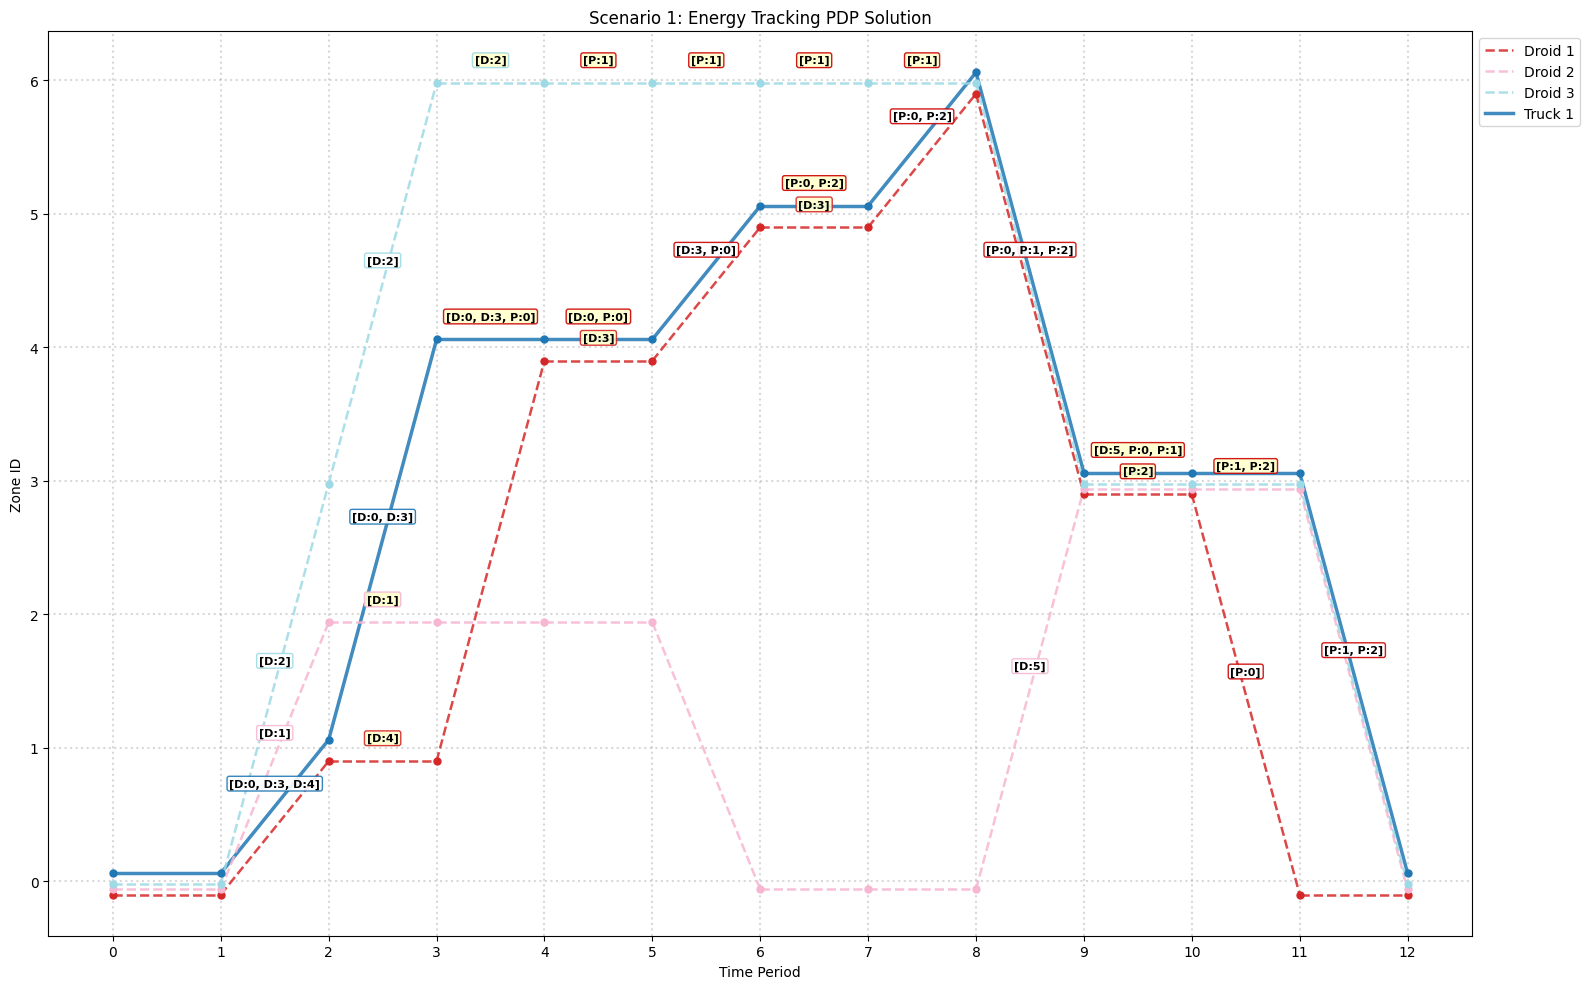

In [31]:
# TODO: Create visualization showing parcel flows and transfers
# 1. Recreate the processed task list (MUST match what went into the solver)
all_tasks_viz = []

# Add Deliveries
for d in deliveries_S:
    all_tasks_viz.append({
        'id': d['id'], 
        'type': 'delivery', 
        # We just need ID and Type for the visualizer map
    })

# Add Pickups (Remember to offset ID by 100 to match the Solver!)
for p in pickups_S:
    all_tasks_viz.append({
        'id': p['id'] + 100,  # <--- Critical: Match the solver's ID logic
        'type': 'pickup',
    })

# 2. Now call the visualizer with this new list
PDP_visualize_graph = visualize_time_space_solution_PDP(
    model_small_case_3, 
    G_small_PDP, 
    all_tasks_viz,  # <--- Use the processed list here
    title="Scenario 1: Energy Tracking PDP Solution"
)

In [32]:
print_detailed_fleet_status_PDP(
    model_small_case_3,  # Your solved model
    deliveries_S,        # The list of delivery dictionaries
    pickups_S,           # The list of pickup dictionaries (New argument!)
    depot_S,             # The depot node ID
    T_S                  # The number of time periods
)


DETAILED TRUCK OPERATIONS REPORT

TRUCK #1
  ------------------------------------------------------------------------------------------------------------------------
  Time         | Zone  | Energy   | Activity                                 | Payload                   | Notes
  ------------------------------------------------------------------------------------------------------------------------
  0 -> 1       | 0     | -        | Waiting / Handoff                        | -                         | 
  1 -> 2       | 0     | -        | Driving -> Z1                            | [0,3,4]                   | Carrying 1 Droid(s)
  2 -> 3       | 1     | -        | Driving -> Z4                            | [0,3]                     | 
  3 -> 4       | 4     | -        | PICKING UP Pkg [0]                       | [0,3,0]                   | 
  4 -> 5       | 4     | -        | DELIVERING Pkg [0]                       | [0,0]                     | 
  5 -> 6       | 4     | -        | Dr

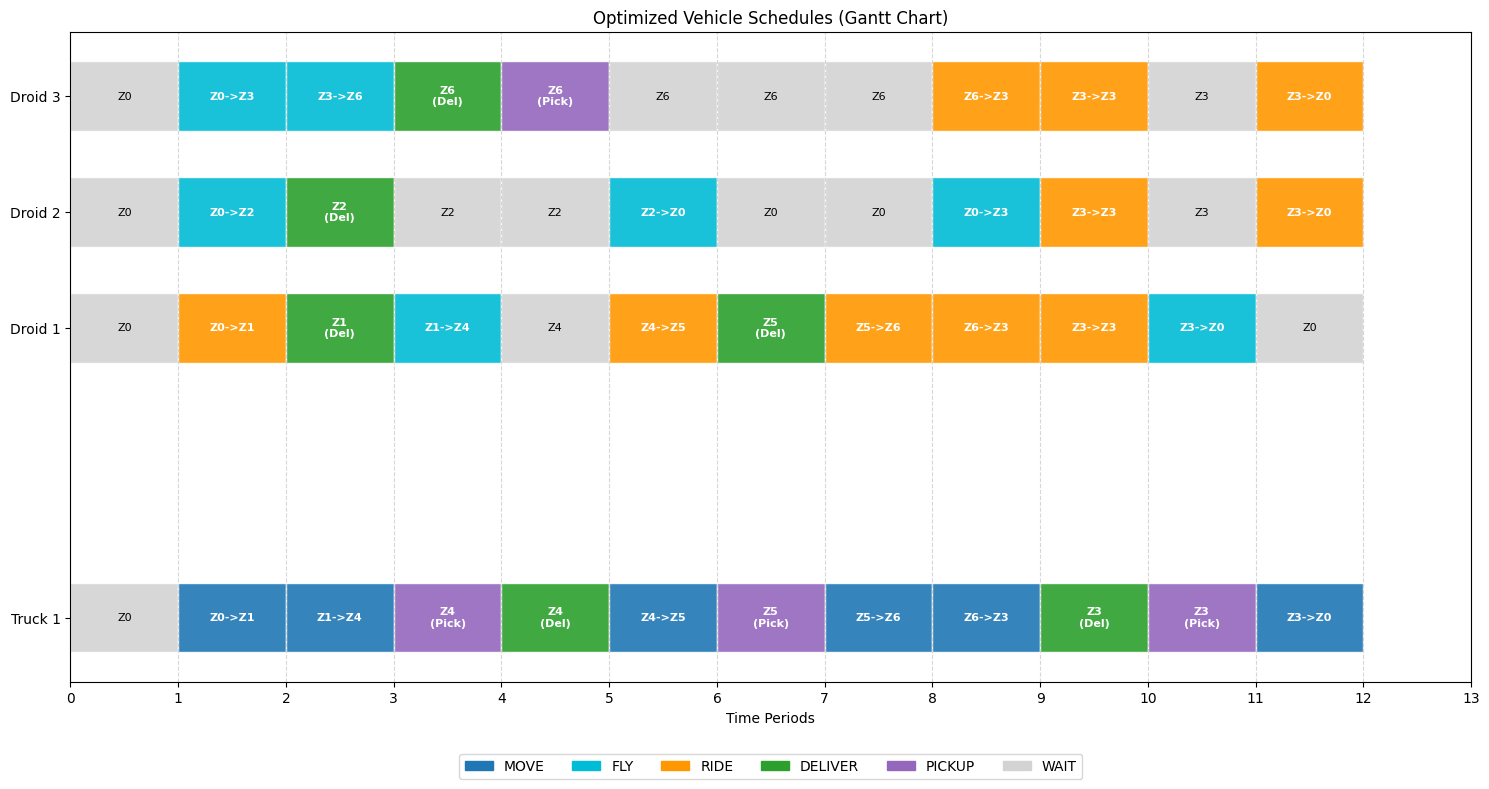

In [33]:
# 1. Plot the Gantt Chart (Tracks Truck/Droid moves, including 'Pickup' in Purple)
PDP_gantt_chart = plot_gantt_chart_3(
    model=model_small_case_3, 
    depot=depot_S, 
    time_periods=T_S
)

Scanning variables...


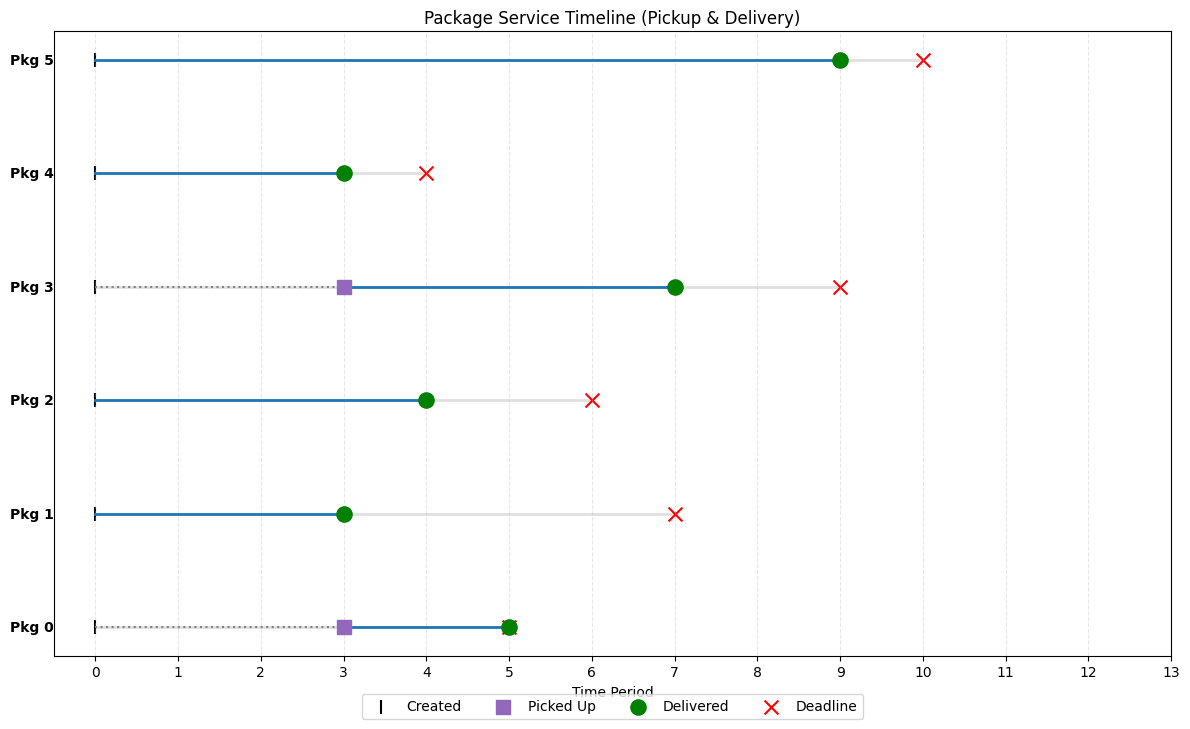

In [34]:
PDP_service_timeline = plot_service_timeline_3(
    model=model_small_case_3, 
    deliveries=deliveries_S, 
    pickups=pickups_S,   # <--- Added
    depot=depot_S, 
    time_periods=T_S
)

## 3.5 Results - Large Instance

In [19]:

# # Load small instance
# zones_L, adjacency_L, T_L, depot_L, deliveries_L, pickups_L, params_L = load_instance('instance_student_large.json')
# T_L=T_L+1
# G_large_PDP = build_time_space_multigraph_pick_and_deliver(zones_L, adjacency_L, T_L, depot=0)
# #visualize_time_space_multigraph(zones_S, adjacency_S, T_S)
# model_large_case_3 = solve_scenario_energy_tracking_PDP(zones_L, adjacency_L, T_L, depot_L, deliveries_L, pickups_L, params_L, G_large_PDP)

# # Place this right after model.optimize()
# if model_large_case_3.status == GRB.INFEASIBLE:
#     print("Model is infeasible. Computing IIS...")
#     model_large_case_3.computeIIS()
#     model_large_case_3.write("infeasible_model.ilp")
#     print("IIS written to 'infeasible_model.ilp'. Open this file to see the conflict.")
    
#     # Optional: Print the specific constraints causing the issue
#     for c in model_large_case_3.getConstrs():
#         if c.IISConstr:
#             print(f"Conflict Constraint: {c.ConstrName}")

# else:
#     # TODO: Display results
#     print(f"Objective Value: {model_large_case_3.ObjVal}")
#     print(f"Solve Time: {model_large_case_3.Runtime:.2f}s")
#     # TODO: Add analysis of transfers, parcel flows, etc.


In [20]:
# # --- Optimization Settings (Feasibility Focus) ---
# model_large_case_3.Params.TimeLimit = 1800  
    
# # MIPFocus = 1: Focus on finding feasible solutions quickly, rather than proving optimality.
# model_large_case_3.Params.MIPFocus = 1      
    
# # Heuristics: Spend more time guessing solutions. (0.05 is default, 0.5 is very aggressive)
# model_large_case_3.Params.Heuristics = 0.25  
    
# # RINS: A powerful heuristic that runs every N nodes.
# model_large_case_3.Params.RINS = 100        
    
# # NoRelHeurTime: "Nuclear Option". Spend the first 300 seconds ONLY running heuristics 
# # before even starting the root node. This often finds a solution when nothing else does.
# model_large_case_3.Params.NoRelHeurTime = 300 
    
# # Reduce aggression on Cuts/Presolve to prevent getting stuck at root
# model_large_case_3.Params.Cuts = -1      # Let Gurobi decide (Auto)
# model_large_case_3.Params.Presolve = -1  # Let Gurobi decide (Auto)

## 3.6 Visualization - Large Instance

In [ ]:
# # TODO: Create visualization showing parcel flows and transfers
# # 1. Recreate the processed task list (MUST match what went into the solver)
# all_tasks_viz = []

# # Add Deliveries
# for d in deliveries_L:
#     all_tasks_viz.append({
#         'id': d['id'], 
#         'type': 'delivery', 
#         # We just need ID and Type for the visualizer map
#     })

# # Add Pickups (Remember to offset ID by 100 to match the Solver!)
# for p in pickups_L:
#     all_tasks_viz.append({
#         'id': p['id'] + 100,  # <--- Critical: Match the solver's ID logic
#         'type': 'pickup',
#     })

# # 2. Now call the visualizer with this new list
# visualize_time_space_solution_PDP(
#     model_large_case_3, 
#     G_large_PDP, 
#     all_tasks_viz,  # <--- Use the processed list here
#     title="Scenario 1: Energy Tracking PDP Solution"
# )

In [ ]:
# print_detailed_fleet_status_PDP(
#     model_large_case_3,  # Your solved model
#     deliveries_L,        # The list of delivery dictionaries
#     pickups_L,           # The list of pickup dictionaries (New argument!)
#     depot_L,             # The depot node ID
#     T_L                  # The number of time periods
# )

---

# Comparison and Analysis

## 4.1 Summary Tables

Create summary tables comparing the three scenarios for both instances.

In [55]:
# TODO: Create comparison tables showing:
# - Objective values for each scenario
# - Solve times
# - Number of variables and constraints
# - Key solution characteristics (e.g., number of excursions, transfers)
# Do this for both small and large instances


# ============================
# Input data
# ============================

# Metric dictionaries for SMALL instances
results_small = {
    "Scenario 1": {
        "Objective": 73,
        "Time (s)": 9.38,
        "Gap (%)": 0,
        "Variables": 5161,
        "Constraints": 3257,
        "Excursions": 0,
        "Transfers": 1
    },
    "Scenario 2": {
        "Objective": 73,
        "Time (s)": 13.31,
        "Gap (%)": 0,
        "Variables": 5161,
        "Constraints": 3257,
        "Excursions": 0,
        "Transfers": 1
    },
    "Scenario 3": {
        "Objective": 83,
        "Time (s)": 12.60,
        "Gap (%)": 0,
        "Variables": 8819,
        "Constraints": 3096,
        "Excursions": 1,
        "Transfers": 3
    }
}

# Metric dictionaries for LARGE instances
results_large = {
    "Scenario 1": {
        "Objective": 145.0,
        "Time (s)": 2000.08,
        "Gap (%)": 32.07,
        "Variables": 54424,
        "Constraints": 31298,
        "Excursions": 7,
        "Transfers": 7
    },
    "Scenario 2": {
        "Objective": 116.5,
        "Time (s)": 2000.06,
        "Gap (%)": 14.59,
        "Variables": 54424,
        "Constraints": 31298,
        "Excursions": 4,
        "Transfers": 6
    },
    "Scenario 3": {
        "Objective": 0,      # Placeholder indicating no solution
        "Time (s)": 0,
        "Gap (%)": 0,
        "Variables": 0,
        "Constraints": 0,
        "Excursions": 0,
        "Transfers": 0
    }
}

# ============================
# Function to build summary table
# ============================

def build_detailed_comparison(result_dict):
    rows = []
    
    for model, metrics in result_dict.items():
        row = {"Model": model}
        
        # Check if this is the empty/placeholder scenario (e.g., Obj is 0)
        if metrics["Objective"] == 0 and metrics["Time (s)"] == 0:
            row["Objective"] = "-"
            row["Solve Time (s)"] = "-"
            row["Gap (%)"] = "-"
            row["Vars / Constrs"] = "-"
            row["Excursions"] = "-"
            row["Transfers"] = "-"
        else:
            row["Objective"] = f"{metrics['Objective']:.2f}"
            row["Solve Time (s)"] = f"{metrics['Time (s)']:.2f}"
            row["Gap (%)"] = f"{metrics['Gap (%)']:.2f}%"
            row["Vars / Constrs"] = f"{metrics['Variables']} / {metrics['Constraints']}"
            row["Excursions"] = metrics['Excursions']
            row["Transfers"] = metrics['Transfers']
        
        rows.append(row)

    return pd.DataFrame(rows)

# ============================
# Create and Display Tables
# ============================

# Helper to handle display in non-Jupyter environments
try:
    display
except NameError:
    def display(df): print(df.to_markdown(index=False))

comp_small = build_detailed_comparison(results_small)
print("\n Detailed Comparison: Small Dataset ")
display(comp_small)

comp_large = build_detailed_comparison(results_large)
print("\n Detailed Comparison: Large Dataset ")
display(comp_large)



 Detailed Comparison: Small Dataset 


,Model,Objective,Solve Time (s),Gap (%),Vars / Constrs,Excursions,Transfers
0,Scenario 1,73.00,9.38,0.00%,5161 / 3257,0,1
1,Scenario 2,73.00,13.31,0.00%,5161 / 3257,0,1
2,Scenario 3,83.00,12.60,0.00%,8819 / 3096,1,3



 Detailed Comparison: Large Dataset 


,Model,Objective,Solve Time (s),Gap (%),Vars / Constrs,Excursions,Transfers
0,Scenario 1,145.00,2000.08,32.07%,54424 / 31298,7,7
1,Scenario 2,116.50,2000.06,14.59%,54424 / 31298,4,6
2,Scenario 3,-,-,-,-,-,-


## 4.2 Comparative Visualization

Create visualizations comparing the three scenarios.


 Visual 1: Objective Comparison 


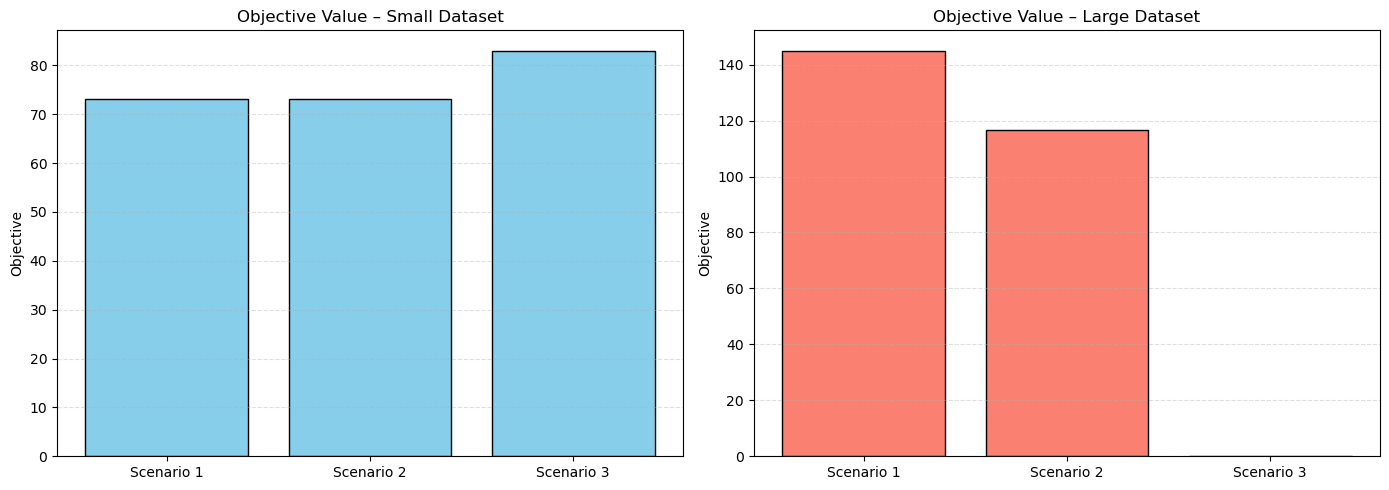


 Visual 2: Solve Time Comparison 


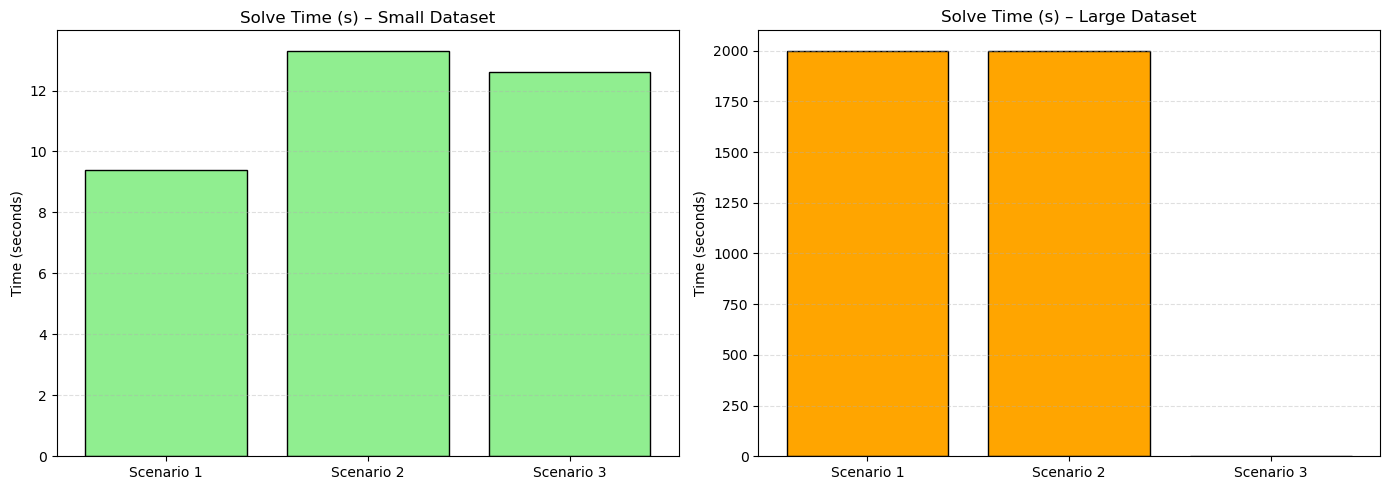

In [ ]:
# TODO: Create comparative visualizations
# Suggestions:
# - Bar charts comparing objectives, solve times
# - Side-by-side route comparisons
# - Analysis of scenario-specific features (excursions, transfers)

# ============================
# Input data (Updated with your latest results)
# ============================

results_small = {
    "Scenario 1": {"Objective": 73.0, "Time (s)": 9.38},
    "Scenario 2": {"Objective": 73.0, "Time (s)": 13.31},
    "Scenario 3": {"Objective": 83.0, "Time (s)": 12.60}
}

results_large = {
    "Scenario 1": {"Objective": 145.0, "Time (s)": 2000.08},
    "Scenario 2": {"Objective": 116.5, "Time (s)": 2000.06},
    "Scenario 3": {"Objective": 0, "Time (s)": 0} # 0 indicates no solution found
}

labels = list(results_small.keys())

# Extract Lists
small_objs = [v["Objective"] for v in results_small.values()]
large_objs = [v["Objective"] for v in results_large.values()]

small_times = [v["Time (s)"] for v in results_small.values()]
large_times = [v["Time (s)"] for v in results_large.values()]

# ============================
# Plot 1: Objective Values
# ============================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ---- Left: Small dataset ----
axes[0].bar(labels, small_objs, color='skyblue', edgecolor='black')
axes[0].set_title("Objective Value – Small Dataset")
axes[0].set_ylabel("Objective")
axes[0].grid(axis='y', linestyle='--', alpha=0.4)

# ---- Right: Large dataset ----
axes[1].bar(labels, large_objs, color='salmon', edgecolor='black')
axes[1].set_title("Objective Value – Large Dataset")
axes[1].set_ylabel("Objective")
axes[1].grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
print("\n\033[1m Visual 1: Objective Comparison \033[0m")
plt.show()

# ============================
# Plot 2: Solve Times
# ============================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ---- Left: Small dataset ----
axes[0].bar(labels, small_times, color='lightgreen', edgecolor='black')
axes[0].set_title("Solve Time (s) – Small Dataset")
axes[0].set_ylabel("Time (seconds)")
axes[0].grid(axis='y', linestyle='--', alpha=0.4)

# ---- Right: Large dataset ----
axes[1].bar(labels, large_times, color='orange', edgecolor='black')
axes[1].set_title("Solve Time (s) – Large Dataset")
axes[1].set_ylabel("Time (seconds)")
axes[1].grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
print("\n\033[1m Visual 2: Solve Time Comparison \033[0m")
plt.show()

In [57]:

def fig_to_base64(fig):
    if fig is None:
        return ""
    buf = io.BytesIO()
    # Save the figure to the buffer
    fig.savefig(buf, format='png', bbox_inches='tight')
    # Encode the buffer to base64
    return base64.b64encode(buf.getvalue()).decode('utf-8')

In [58]:
# Row 1: Graphs
b64_base_graph = fig_to_base64(Base_case_small_graph)
b64_recharge_graph = fig_to_base64(Recharge_case_small_graph)
b64_pdp_graph = fig_to_base64(PDP_visualize_graph)

# Row 2: Gantt Charts
b64_base_gantt = fig_to_base64(Base_case_small_gantt_chart)
b64_recharge_gantt = fig_to_base64(Recharge_case_small_gantt_chart)
b64_pdp_gantt = fig_to_base64(PDP_gantt_chart)

# Row 3: Service Timelines
b64_base_service = fig_to_base64(Base_case_small_service_time)
b64_recharge_service = fig_to_base64(Recharge_case_small_service_time)
b64_pdp_service = fig_to_base64(PDP_service_timeline)

Base Case,Recharge Case,PDP Case
Base Case: Space-Time Network,Recharge: Space-Time Network,PDP: Space-Time Network
Base Case Gantt,Recharge Gantt,PDP Gantt
Base Case Service,Recharge Service,PDP Service

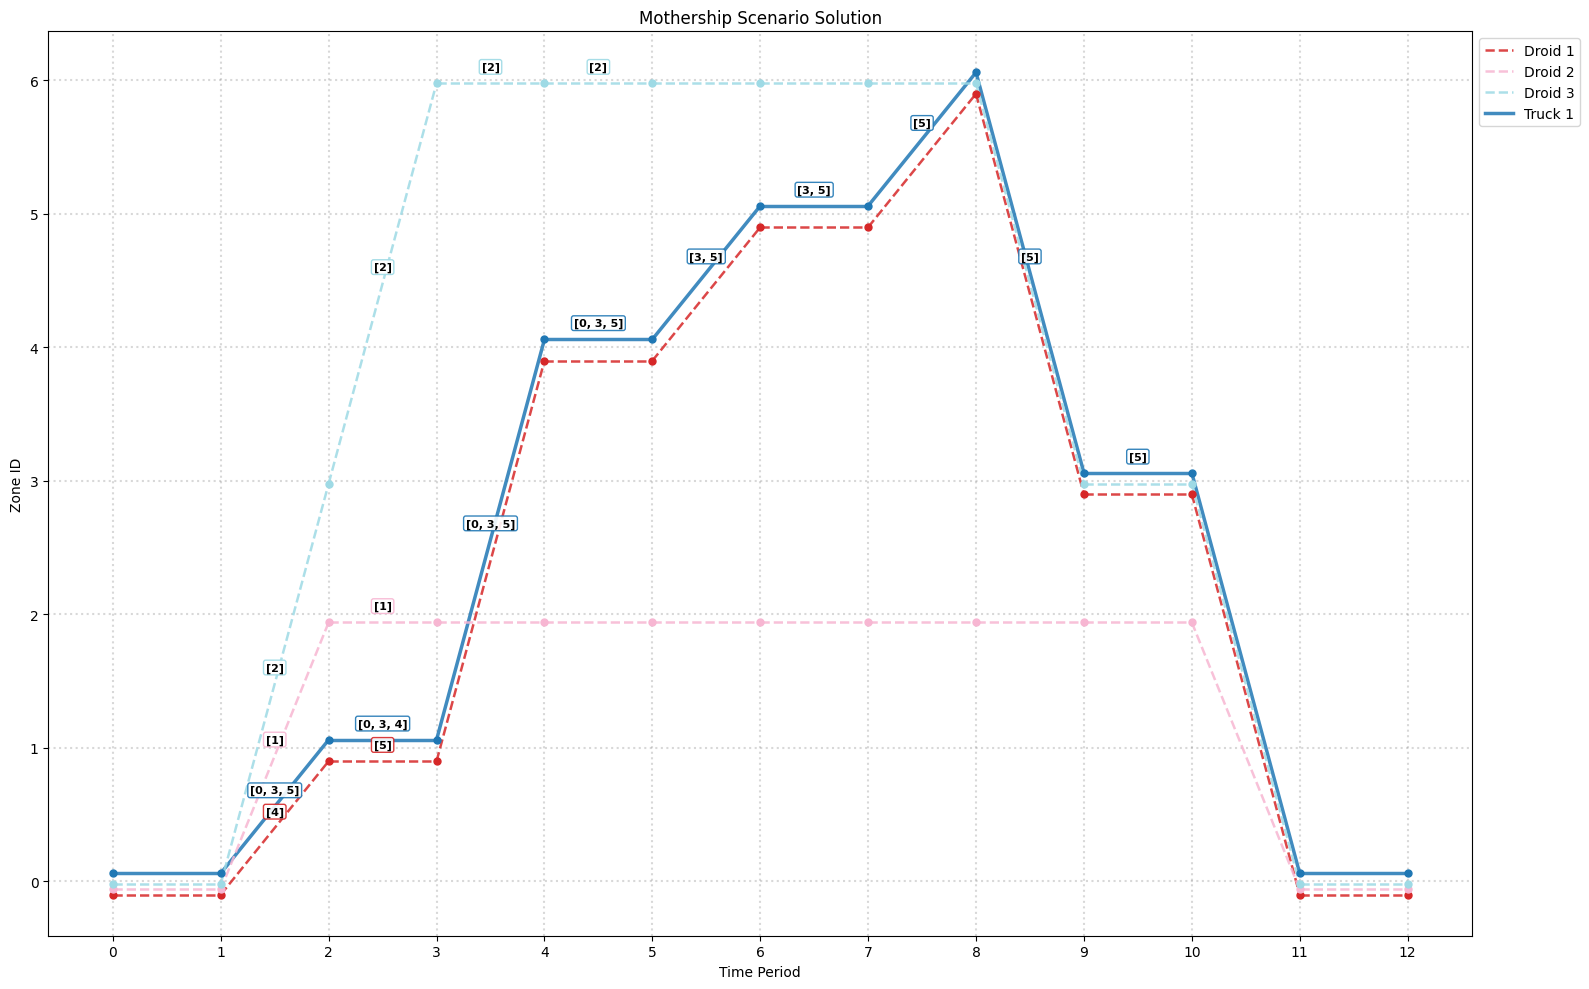
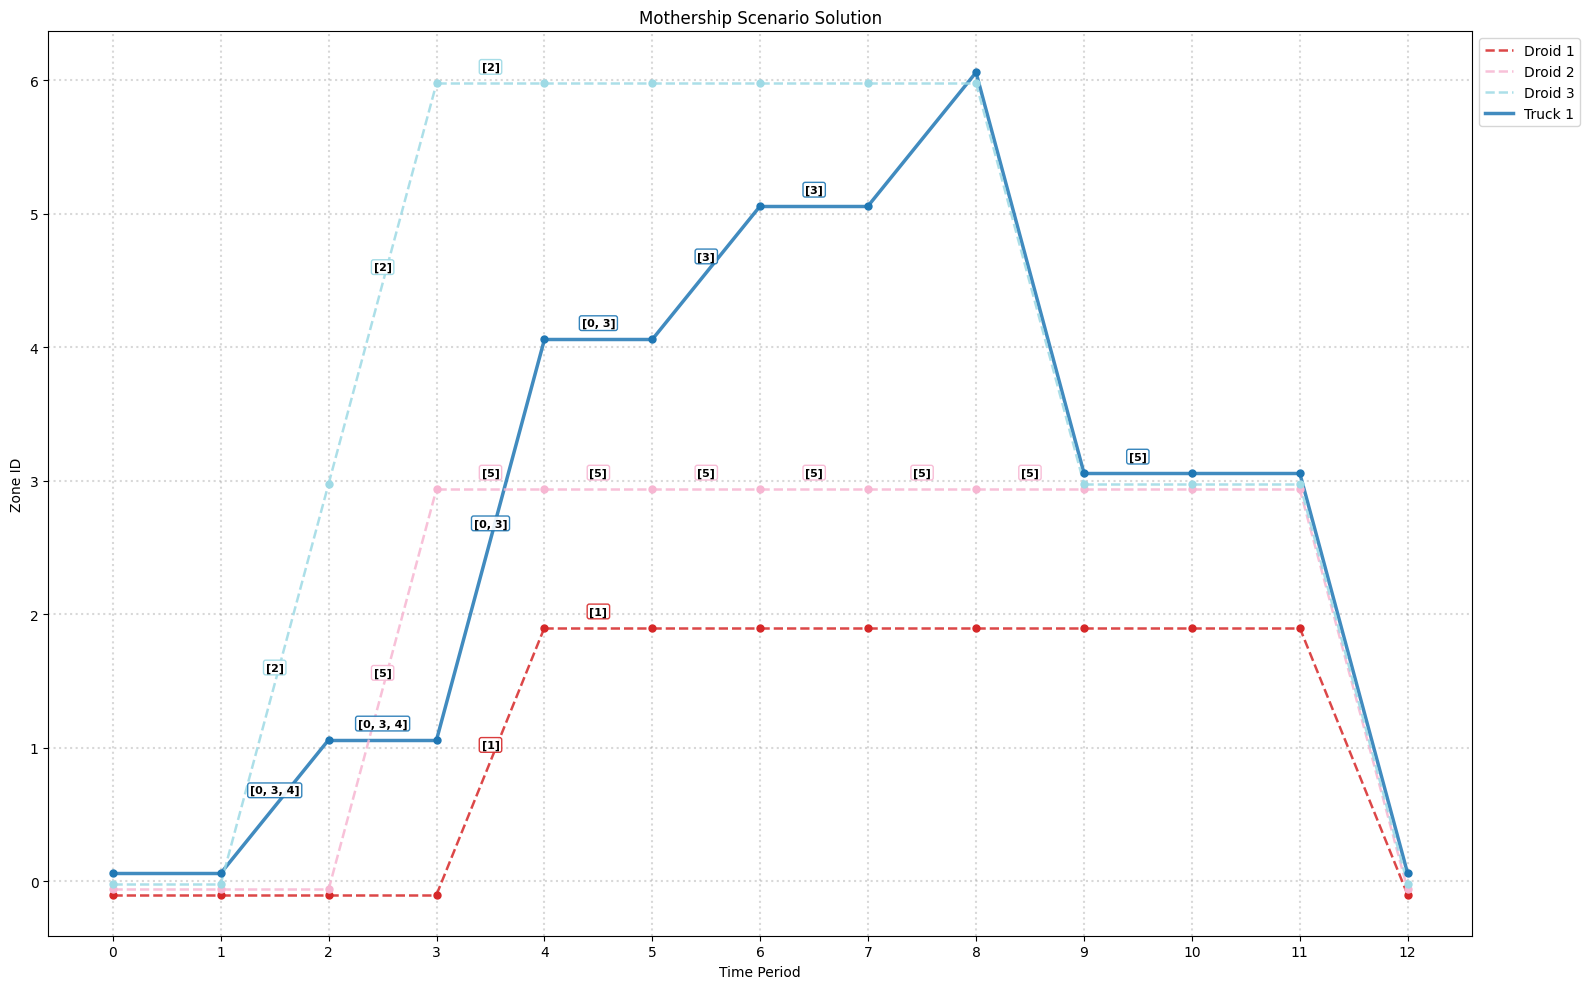
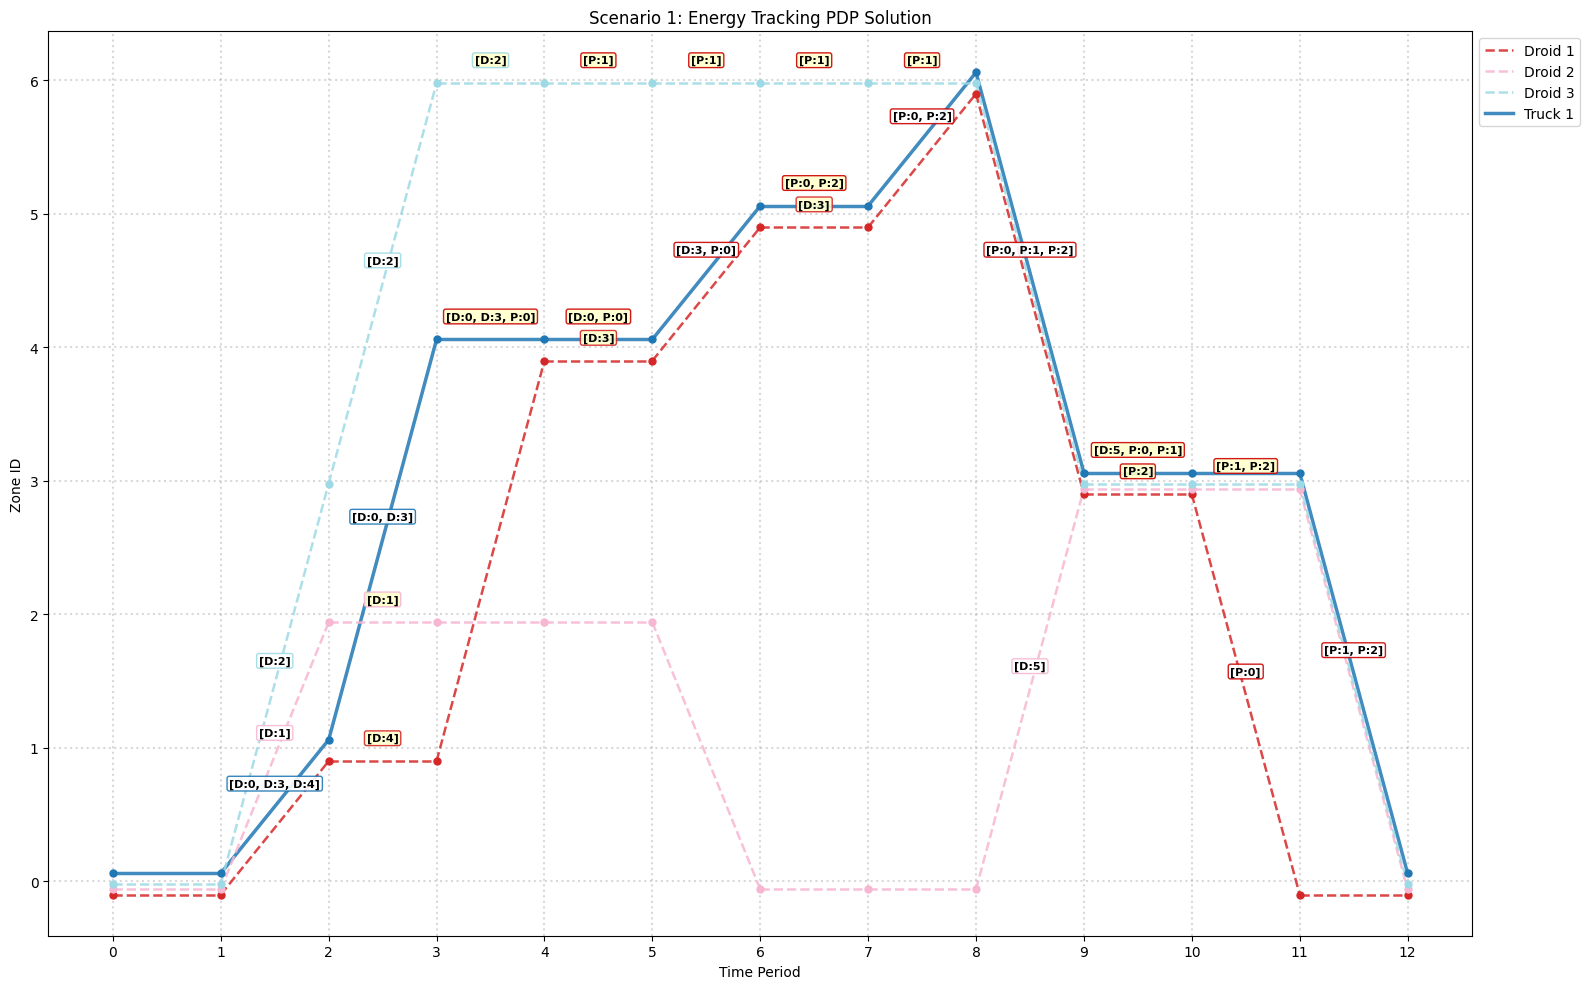
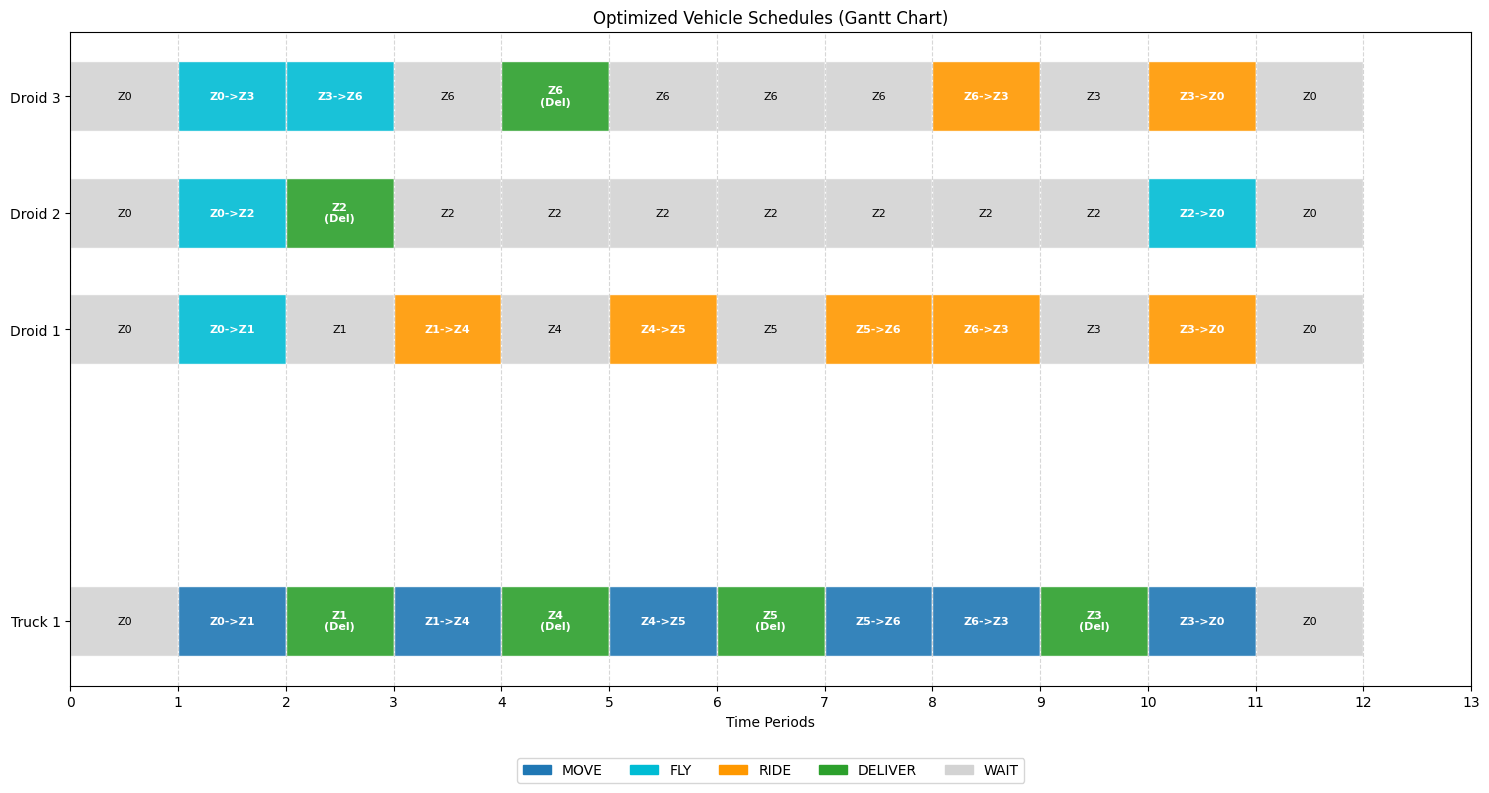
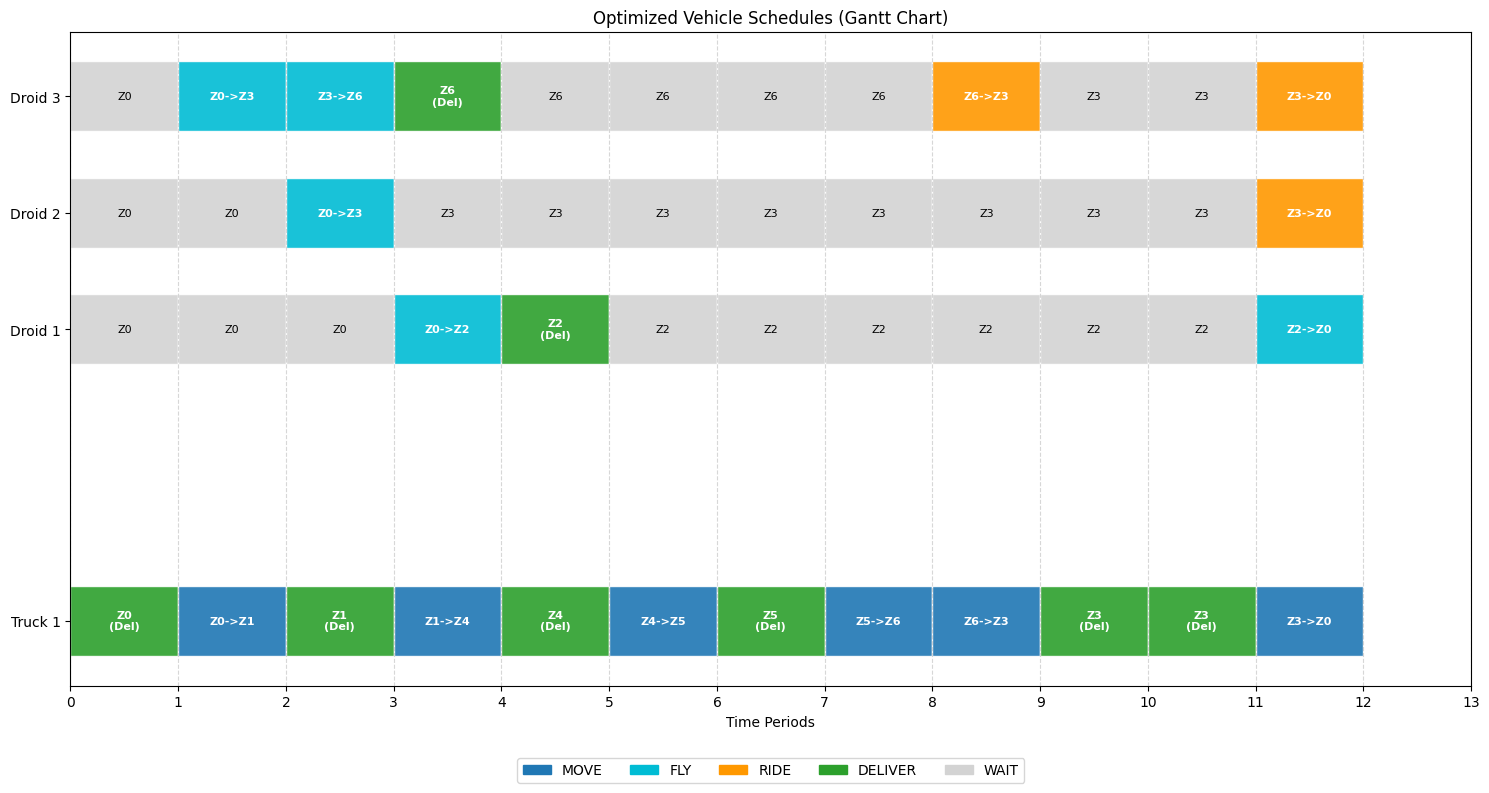
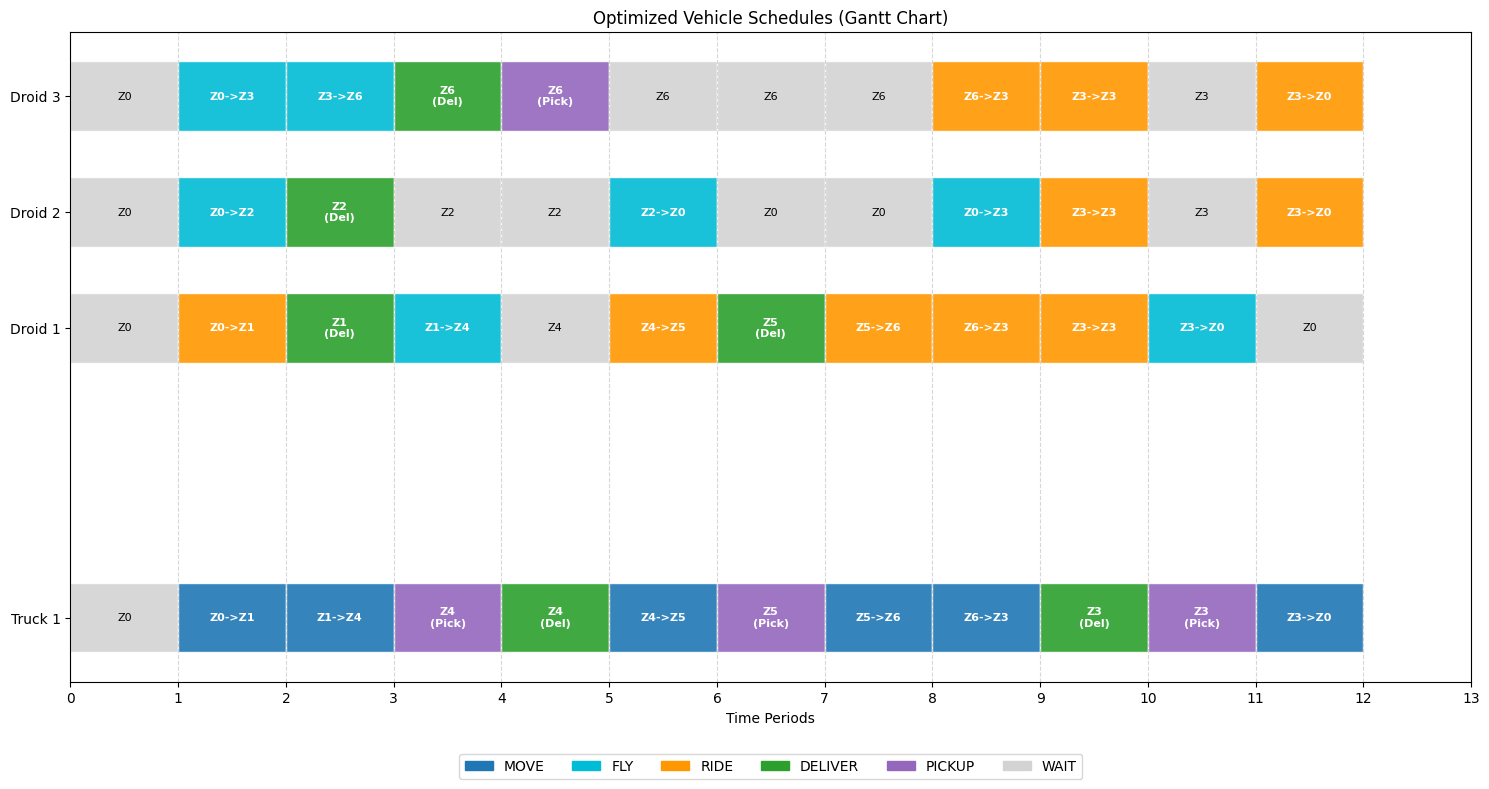
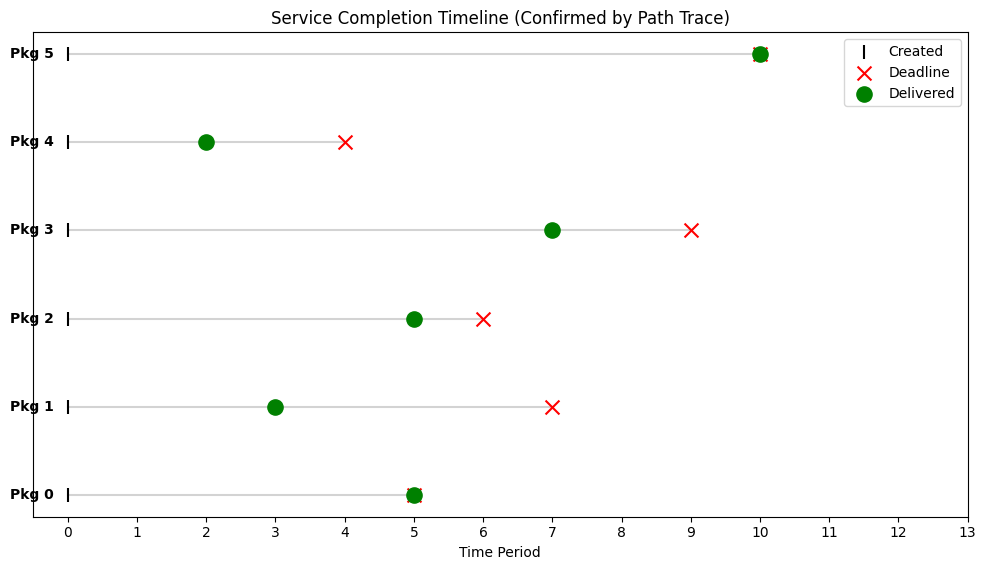
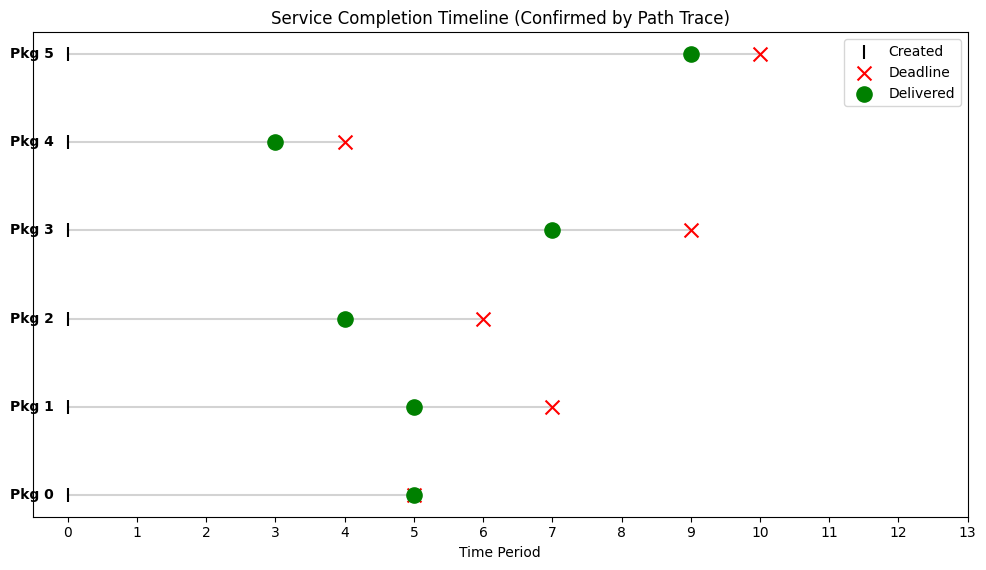
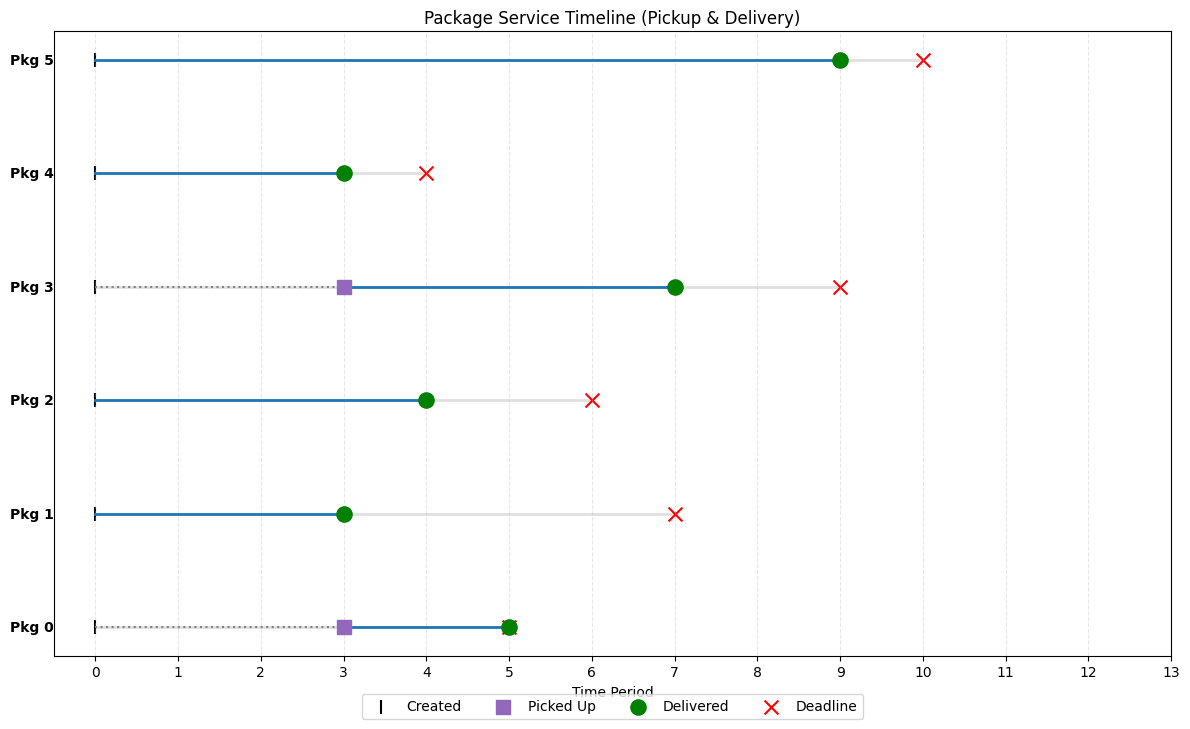

In [59]:
from IPython.display import HTML

# (Assuming you already have your b64 variables from the previous step)

html_layout = f"""
<div style="width: 100%; height: 800px; overflow: auto; border: 1px solid #ccc; padding: 10px;">
    <table style="border-collapse: separate; border-spacing: 15px; text-align: center; font-family: sans-serif; min-width: 2500px;">
        <thead>
            <tr style="background-color: #333; color: white; position: sticky; top: 0; z-index: 10;">
                <th style="padding: 10px; width: 800px;">Base Case</th>
                <th style="padding: 10px; width: 800px;">Recharge Case</th>
                <th style="padding: 10px; width: 800px;">PDP Case</th>
            </tr>
        </thead>
        <tbody>
            <tr>
                <td>
                    <div style="border: 1px solid #ddd; padding: 5px; background: white;">
                        <img src="data:image/png;base64,{b64_base_graph}" style="width: 100%;"><br>
                        <b>Base Case: Space-Time Network</b>
                    </div>
                </td>
                <td>
                    <div style="border: 1px solid #ddd; padding: 5px; background: white;">
                        <img src="data:image/png;base64,{b64_recharge_graph}" style="width: 100%;"><br>
                        <b>Recharge: Space-Time Network</b>
                    </div>
                </td>
                <td>
                    <div style="border: 1px solid #ddd; padding: 5px; background: white;">
                        <img src="data:image/png;base64,{b64_pdp_graph}" style="width: 100%;"><br>
                        <b>PDP: Space-Time Network</b>
                    </div>
                </td>
            </tr>
            <tr>
                <td><img src="data:image/png;base64,{b64_base_gantt}" style="width: 100%;"><br><b>Base Case Gantt</b></td>
                <td><img src="data:image/png;base64,{b64_recharge_gantt}" style="width: 100%;"><br><b>Recharge Gantt</b></td>
                <td><img src="data:image/png;base64,{b64_pdp_gantt}" style="width: 100%;"><br><b>PDP Gantt</b></td>
            </tr>
            <tr>
                <td><img src="data:image/png;base64,{b64_base_service}" style="width: 100%;"><br><b>Base Case Service</b></td>
                <td><img src="data:image/png;base64,{b64_recharge_service}" style="width: 100%;"><br><b>Recharge Service</b></td>
                <td><img src="data:image/png;base64,{b64_pdp_service}" style="width: 100%;"><br><b>PDP Service</b></td>
            </tr>
        </tbody>
    </table>
</div>
"""

HTML(html_layout)

In [60]:
def fig_to_base64_safe(fig):
    """Safely converts a figure to base64, returning a placeholder if it fails."""
    try:
        if fig is None:
            raise ValueError("Figure is None")
        
        buf = io.BytesIO()
        # Use bbox_inches='tight' to ensure labels aren't cut off in the large view
        fig.savefig(buf, format='png', bbox_inches='tight', dpi=100)
        buf.seek(0)
        return base64.b64encode(buf.getvalue()).decode('utf-8')
    except Exception:
        # Create a tiny grey placeholder image if the figure is missing
        placeholder_fig, ax = plt.subplots(figsize=(4, 2))
        ax.text(0.5, 0.5, "Data Not Available\n(Infeasible or Timed Out)", 
                ha='center', va='center', color='gray')
        ax.set_axis_off()
        buf = io.BytesIO()
        placeholder_fig.savefig(buf, format='png')
        plt.close(placeholder_fig)
        return base64.b64encode(buf.getvalue()).decode('utf-8')

try:
    # --- Convert Large Case Figures ---
    # Column 1: Base Case Large
    b64_L_base_graph   = fig_to_base64_safe(Base_case_large_graph)
    b64_L_base_gantt   = fig_to_base64_safe(Base_case_large_gantt_chart)
    b64_L_base_service = fig_to_base64_safe(Base_case_large_service_time)

    # Column 2: Recharge Case Large
    b64_L_rech_graph   = fig_to_base64_safe(Recharge_case_large_graph)
    b64_L_rech_gantt   = fig_to_base64_safe(Recharge_case_large_gantt_chart)
    b64_L_rech_service = fig_to_base64_safe(Recharge_case_large_service_time)

    # Note: If you have a PDP Large Case, add those here as well.
    
    # --- Generate the Scrollable HTML ---
    large_html = f"""
    <div style="width: 100%; height: 900px; overflow: auto; border: 2px solid #2c3e50; padding: 10px; background-color: #f9f9f9;">
        <table style="border-collapse: separate; border-spacing: 20px; text-align: center; font-family: 'Segoe UI', Tahoma, Geneva, Verdana, sans-serif; min-width: 1800px;">
            <thead>
                <tr style="background-color: #2c3e50; color: white; position: sticky; top: 0; z-index: 10;">
                    <th style="padding: 15px; width: 900px; font-size: 1.2em;">LARGE: Base Case</th>
                    <th style="padding: 15px; width: 900px; font-size: 1.2em;">LARGE: Recharge Case</th>
                </tr>
            </thead>
            <tbody>
                <tr>
                    <td><img src="data:image/png;base64,{b64_L_base_graph}" style="width: 100%; border: 1px solid #ddd; box-shadow: 2px 2px 5px rgba(0,0,0,0.1);"><br><b>Space-Time Network</b></td>
                    <td><img src="data:image/png;base64,{b64_L_rech_graph}" style="width: 100%; border: 1px solid #ddd; box-shadow: 2px 2px 5px rgba(0,0,0,0.1);"><br><b>Space-Time Network</b></td>
                </tr>
                <tr>
                    <td><img src="data:image/png;base64,{b64_L_base_gantt}" style="width: 100%;"><br><b>Gantt Chart (Large)</b></td>
                    <td><img src="data:image/png;base64,{b64_L_rech_gantt}" style="width: 100%;"><br><b>Gantt Chart (Large)</b></td>
                </tr>
                <tr>
                    <td><img src="data:image/png;base64,{b64_L_base_service}" style="width: 100%;"><br><b>Service Timeline (Large)</b></td>
                    <td><img src="data:image/png;base64,{b64_L_rech_service}" style="width: 100%;"><br><b>Service Timeline (Large)</b></td>
                </tr>
            </tbody>
        </table>
    </div>
    """
    display(HTML(large_html))

except Exception as e:
    print(f"Some of the big case figures could not be generated: {e}")
    print("Reason: the model may have timed out before producing Integer Feasible results.")



Some of the big case figures could not be generated: name 'Base_case_large_graph' is not defined
Reason: the model may have timed out before producing Integer Feasible results.


## Those were the results we obtained last time we ran it

<h3>Small Dataset</h3>
<div style="display: flex; gap: 10px; justify-content: center;">
    <figure style="text-align: center; width: 32%;">
        <img src="Scenario 1 _ Small Data _ Time Space Solution.png" width="100%">
        <figcaption><b>Scenario 1</b></figcaption>
    </figure>
    <figure style="text-align: center; width: 32%;">
        <img src="Scenario 2 _ Small Data _ Time Space Solution.png" width="100%">
        <figcaption><b>Scenario 2</b></figcaption>
    </figure>
    <figure style="text-align: center; width: 32%;">
        <img src="Scenario 3_Small Data_Time Space Solution New.png" width="100%">
        <figcaption><b>Scenario 3</b></figcaption>
    </figure>
</div>

<h3>Large Dataset</h3>
<div style="display: flex; gap: 10px; justify-content: center;">
    <figure style="text-align: center; width: 32%;">
        <img src="Scenario 1 _ Large Data _ Time Space Solution.png" width="100%">
        <figcaption><b>Scenario 1</b></figcaption>
    </figure>
    <figure style="text-align: center; width: 32%;">
        <img src="Scenario 2 _ Large Data _ Time Space Solution.png" width="100%">
        <figcaption><b>Scenario 2</b></figcaption>
    </figure>
</div>

<h3>Small Dataset</h3>
<div style="display: flex; gap: 10px; justify-content: center;">
    <figure style="text-align: center; width: 32%;">
        <img src="Service TIme _ Scenario 1 _ Small Data.png" width="100%">
        <figcaption><b>Scenario 1</b></figcaption>
    </figure>
    <figure style="text-align: center; width: 32%;">
        <img src="Service TIme _ Scenario 2 _ Small Data.png" width="100%">
        <figcaption><b>Scenario 2</b></figcaption>
    </figure>
    <figure style="text-align: center; width: 32%;">
        <img src="Service TIme _ Scenario 3 _ Small Data.png" width="100%">
        <figcaption><b>Scenario 3</b></figcaption>
    </figure>
</div>

<h3>Large Dataset</h3>
<div style="display: flex; gap: 10px; justify-content: center;">
    <figure style="text-align: center; width: 32%;">
        <img src="Service Time _ Scenario 1 _ Large Data.png" width="100%">
        <figcaption><b>Scenario 1</b></figcaption>
    </figure>
    <figure style="text-align: center; width: 32%;">
        <img src="Service TIme _ Scenario 2 _ Large Data.png" width="100%">
        <figcaption><b>Scenario 2</b></figcaption>
    </figure>
</div>

<h3>Small Dataset</h3>
<div style="display: flex; gap: 10px; justify-content: center;">
    <figure style="text-align: center; width: 32%;">
        <img src="Gantt Chart _ Scenario 1 _ Small Data.png" width="100%">
        <figcaption><b>Scenario 1</b></figcaption>
    </figure>
    <figure style="text-align: center; width: 32%;">
        <img src="Gantt Chart _ Scenario 2 _ Small Data.png" width="100%">
        <figcaption><b>Scenario 2</b></figcaption>
    </figure>
    <figure style="text-align: center; width: 32%;">
        <img src="Gantt Chart _ Scenario 3 _ Small Data.png" width="100%">
        <figcaption><b>Scenario 3</b></figcaption>
    </figure>
</div>

<h3>Large Dataset</h3>
<div style="display: flex; gap: 10px; justify-content: center;">
    <figure style="text-align: center; width: 32%;">
        <img src="Gantt Chart _ Scenario 1 _ Large Data.png" width="100%">
        <figcaption><b>Scenario 1</b></figcaption>
    </figure>
    <figure style="text-align: center; width: 32%;">
        <img src="Gantt Chart _ Scenario 2 _ Large Data.png" width="100%">
        <figcaption><b>Scenario 2</b></figcaption>
    </figure>
</div>

## 4.3 Discussion

Discuss the differences between the three scenarios. Address the following questions:

1. How does allowing recharging (Scenario 2) impact the solution compared to Scenario 1?
2. What is the benefit of parcel transfers in Scenario 3?
3. How do solve times differ between scenarios? Why?
4. What are the key trade-offs between model complexity and solution quality?

---

### **Your Discussion**

The comparison of the three scenarios highlights the fundamental tension in optimization modeling: gaining operational efficiency (better objective values) usually requires increasing mathematical complexity (longer solve times).

#### **1. Impact of Recharging (Scenario 2 vs Scenario 1)**

* **Improved Efficiency on Large Scales:** In the small dataset, recharging did not impact the solution (Objective remained **73.0**), likely because the limited range of the small map did not require extended droid endurance.
* **Significant Gains (with Caveats) on Large Data:** In the large dataset, Scenario 2 achieved a significantly better current objective (**116.5**) compared to Scenario 1 (**145.0**). This suggests that allowing droids to recharge extends their effective range, allowing them to service distant customers without frequent returns to the depot.
* **Optimality Warning:** It is critical to note that neither large instance solution is proven optimal. Scenario 1 ended with a **32.07% gap**, and Scenario 2 with a **14.59% gap**. This means the solver hit the 2000-second time limit before it could find the best possible solution or prove that the current one was the best. While Scenario 2 found a much better feasible solution (116.5), the large gap in Scenario 1 suggests its true optimal value could potentially be much lower than 145.0. (After running it for 2 hours, it reached a value of 117.5)

#### **2. What is the benefit of parcel transfers in Scenario 3?**

* **Decoupling Logistics:** Scenario 3 introduces the highest level of complexity, introducing both delivery and pick-up parcels. While inside the delivery case, the transfers were Truck-Droid, and Droids delivering it to the end Location, in the pick-up case, Droids were used for Pick-ups as well. Allowing Droids to them load off the package at a truck, allows them to then become again available for a new excursion, making the model much more flexible.
* **Service Capability vs. Solvability:** In the small dataset, Scenario 3 resulted in a higher objective value (**83.0 vs 73.0**). If the objective represents cost, this suggests the flexibility came at a price (more transfers = more time/energy). However, on the Large Dataset, this flexibility came at a fatal computational cost: the model was unable to find any feasible solution within the time limit (**Objective 0**). This illustrates that while transfers allow for complex routing "relay" strategies, they explode the problem size to a point where standard solvers struggle to find even a valid starting point for large instances, based on out formulation attempt. It has to be pointed out that the objective value difference (**83.0 vs 73.0**), when looked from total parcels being served, paints a different pickture. The Delivery cases had only 6 packages to deliver, making per parcel cost of roughly 12, while the Pick-up and Delivery case had in total 9 packages, making the per package cost roughly 9.2. Meaning, even though in absolute, the Delivery case were cheaper, increasing the number of parcels, lead to economies of scale.

#### **3. How do solve times differ between scenarios? Why?**

* **Small Instances:** All scenarios solved quickly (**5–20 seconds**). The problem size was small enough that the added complexity of energy (Scenario 2) or transfers (Scenario 3) had negligible impact on runtime.
* **Large Instances:** The difference was drastic. Scenario 1 and 2 both hit the 2000-second time limit, failing to converge to **0% gap**. 
    * **Reason:** The "Large" dataset increases the search space exponentially. Tracking the exact energy state of every droid (Scenario 2) or the location of every individual package independently of vehicles (Scenario 3) adds thousands of variables and constraints. The solver must explore a massive combinatorial tree, leading to the large optimality gaps observed.
* **Tactics for Improving Solvability:**
    * **Variable Pruning (Manual):** To reduce the model size, we implemented custom reachability logic for package variables ($x$). We skipped creating variables for paths that were physically impossible:
        * **Deadline Pruning:** Arcs were pruned if the time remaining ($deadline - current\_time$) was less than the minimum travel time required to reach the target zone. For example, if package [1] was due at time[5] at location [1], and it takes 3 time periods to get from location [6] to location [1], then it doesn't make sence for the package [1] to be part of the flow at location [6] at time[3] or time[4], as we cannot reach from [6] -> [1] before the due date is over.
        * **Origin Pruning:** Arcs were pruned if the time elapsed from the start was less than the minimum travel time required to reach the current node from the depot. At time[0], from location [0], we cannot reach the furthers points on the map by time[1], so those arcs are also not needed in the model.
    * **Presolve (Gurobi):** We utilized Gurobi’s internal **Presolve** engine, which performs its own logical reductions—removing redundant constraints and fixing variables—to tighten the model before the branch-and-bound algorithm begins.
    * **Specific cuts:** We Implemented a vary basic cut. If a package moves on an arc, assigned to a vehicle type, then that vehicle needs to be on the arc. Those are the last constraints for all model cases
    * **Result:** These combined tactics significantly reduced the "skipped variables" count, preventing the solver from wasting memory and time on clearly non-optimal or infeasible regions of the solution space.

#### **4. What are the key trade-offs between model complexity and solution quality?**

The core trade-off is between guaranteed optimality and operational flexibility:

> **Scenario 1 (Baseline):** The least complex model. It often finds a feasible solution fast, but because it is rigid (droids are cannot rechare on trucks or depot), it may miss out on more efficient routes, resulting in a higher operational cost (**145.0**).

> **Scenario 2 (Recharging):** A "Sweet Spot" for complexity. It allows for significantly better solutions (**116.5**) by removing range constraints. However, the trade-off is that it becomes harder to prove optimality, leaving us with a **~15% uncertainty (gap)** about whether a better plan exists.

> **Scenario 3 (Transfers):** High risk, high reward. Theoretically, it allows the most efficient routing by treating vehicles and packages as independent agents. Practically, the complexity is so high that for large datasets, it yields no solution at all within reasonable time limits. The trade-off here is clear: extreme flexibility can make the model unsolvable.

## Contribution Statement

| Activity | Brian Ignass (%) | Ivaylo Iliev (%) |
| :--- | :---: | :---: |
| **Data & Core Infrastructure** | | |
| Data preprocessing | % | 100% |
| Graph generation | % | 100% |
| **Base Model** | | |
| Mathematical Development | 50% | 50% |
| Implementation | % | 100% |
| Visualization (Graph, Gantt, Service) | % | 100% |
| Detailed statistics | % | 100% |
| **Recharge Model** | | |
| Mathematical Development | % | 100% |
| Implementation | % | 100% |
| Visualization (Graph, Gantt, Service) | % | 100% |
| Detailed statistics | % | 100% |
| **PDP Model (Scenario 3)** | | |
| Preprocessing | % | 100% |
| Mathematical Development | 20% | 80% |
| Implementation | % | 100% |
| Visualization (Graph, Gantt, Service) | 67% | 33% |
| Detailed statistics | % | 100% |
| Package Statistics | % | 100% |
| **Reporting & Analysis** | | |
| Discussion | 100% | % |
| Summary Tables | 100% | % |
| Comparative visualization | 90% | 10% |
| Discussion itself | 95% | 5% |
| **Total Average** | **26.1%** | **73.9%** |

---

# End of Assignment

**Checklist before submission:**

- [ ] Group information is filled in completely
- [ ] All three mathematical formulations are complete and correct
- [ ] All three scenarios are implemented and working
- [ ] All code cells execute without errors
- [ ] Results are displayed for both small and large instances
- [ ] Visualizations are created and meaningful
- [ ] Summary tables and comparisons are complete
- [ ] Discussion section addresses all questions
- [ ] The notebook runs from top to bottom without errors
- [ ] Solve times are reasonable (< 1s for small, < 15 min for large)

**Submission instructions:** 
- Submit this Jupyter notebook file (.ipynb)
- Include instance files: `instance_student_small.json` and `instance_student_large.json`
- All work must be contained in these files

**Good luck!**